In [ ]:
from pathlib import Path
import pandas as pd

# Find CSV files uploaded to Colab
root = Path("/content")

files = list(root.rglob("fragment_metadata_curculionidae.csv"))
files += list(root.rglob("fragment_metadata_tenebrionidae.csv"))

if not files:
    print("CSV files not found. Upload them to Colab first.")
else:
    for file in files:
        print("\n" + "=" * 60)
        print("FILE:", file.name)

        df = pd.read_csv(file)

        print("Dataset shape:", df.shape)
        print("\nSpecies counts:")
        print(df["Species"].value_counts(dropna=False))

        print("\nAnatomical region counts:")
        print(df["AnatomicalRegion"].value_counts(dropna=False))

        print("\nAugmentation types:")
        print(df["AugmentationType"].value_counts(dropna=False))

        print("\nMissing values:")
        print(df.isnull().sum())

        print("\nSpecies × anatomical region:")
        print(pd.crosstab(df["Species"], df["AnatomicalRegion"]))

        print("\nFirst 5 rows:")
        print(df.head().to_string(index=False))

CSV files not found. Upload them to Colab first.


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving curculionidae_signature_metrics.csv to curculionidae_signature_metrics.csv
Saving tenebrionidae_signature_metrics.csv to tenebrionidae_signature_metrics.csv


In [ ]:
from pathlib import Path
import pandas as pd

# Find CSV files uploaded to Colab
root = Path("/content")

files = list(root.rglob("fragment_metadata_curculionidae.csv"))
files += list(root.rglob("fragment_metadata_tenebrionidae.csv"))

if not files:
    print("CSV files not found. Upload them to Colab first.")
else:
    for file in files:
        print("\n" + "=" * 60)
        print("FILE:", file.name)

        df = pd.read_csv(file)

        print("Dataset shape:", df.shape)
        print("\nSpecies counts:")
        print(df["Species"].value_counts(dropna=False))

        print("\nAnatomical region counts:")
        print(df["AnatomicalRegion"].value_counts(dropna=False))

        print("\nAugmentation types:")
        print(df["AugmentationType"].value_counts(dropna=False))

        print("\nMissing values:")
        print(df.isnull().sum())

        print("\nSpecies × anatomical region:")
        print(pd.crosstab(df["Species"], df["AnatomicalRegion"]))

        print("\nFirst 5 rows:")
        print(df.head().to_string(index=False))

CSV files not found. Upload them to Colab first.


In [ ]:
import pandas as pd

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n", "=" * 50)
    print(family, "shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head())
    print("\nMissing values:\n", df.isnull().sum())


Curculionidae shape: (1553, 7)
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']
  ImageName  Skewness  Kurtosis   Entropy  StandardDeviation Species Fragment
0     1.jpg  0.996069  2.422996  2.270740           0.115924      mw  antenna
1     2.jpg -0.055020  1.569616  2.947459           0.069458      mw  antenna
2     3.jpg -0.128007  1.465497  2.964119           0.068367      mw  antenna
3     4.jpg -0.077968  1.516452  2.955339           0.069111      mw  antenna
4     5.jpg -0.083438  1.509684  2.942651           0.069507      mw  antenna

Missing values:
 ImageName            0
Skewness             0
Kurtosis             0
Entropy              0
StandardDeviation    0
Species              0
Fragment             0
dtype: int64

Tenebrionidae shape: (1812, 7)
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']
  ImageName  Skewness  Kurtosis   Entropy  StandardDeviation Species Fra

In [ ]:

import pandas as pd

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

for family, url in urls.items():
    df = pd.read_csv(url)

    features = [
        "Skewness", "Kurtosis",
        "Entropy", "StandardDeviation"
    ]

    print("\n" + "=" * 60)
    print("FAMILY:", family)
    print("Total records:", len(df))

    print("\nSpecies counts:")
    print(df["Species"].value_counts())

    print("\nSpecies × fragment:")
    print(pd.crosstab(df["Species"], df["Fragment"]))

    print("\nExact duplicate feature rows:",
          df.duplicated(subset=features + ["Species", "Fragment"]).sum())

    print("\nFeature summary:")
    print(df[features].describe().round(3))

    print("\nImage names repeated:",
          df["ImageName"].duplicated().sum())



FAMILY: Curculionidae
Total records: 1553

Species counts:
Species
mw    582
rw    540
ww    431
Name: count, dtype: int64

Species × fragment:
Fragment  antenna  elytra  snout  thorax
Species                                 
mw            144     108    192     138
rw            138     144    150     108
ww            114      89    114     114

Exact duplicate feature rows: 0

Feature summary:
       Skewness  Kurtosis   Entropy  StandardDeviation
count  1553.000  1553.000  1553.000           1553.000
mean      0.219     1.761     3.032              0.068
std       0.312     0.309     0.258              0.016
min      -0.950     1.174     1.974              0.030
25%       0.060     1.603     2.941              0.056
50%       0.194     1.712     3.096              0.063
75%       0.296     1.812     3.248              0.074
max       1.472     3.559     3.481              0.138

Image names repeated: 1313

FAMILY: Tenebrionidae
Total records: 1812

Species counts:
Species
lo     7

In [ ]:

import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

features = ["Skewness", "Kurtosis", "Entropy", "StandardDeviation"]

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 65)
    print("FAMILY:", family)

    # Check whether the composite identifier repeats
    print("Duplicate species-fragment-filename keys:",
          df.duplicated(["Species", "Fragment", "ImageName"]).sum())

    results = []

    for held_out in sorted(df["Fragment"].unique()):
        train = df[df["Fragment"] != held_out]
        test = df[df["Fragment"] == held_out]

        for model_name, model in {
            "SVM": make_pipeline(
                StandardScaler(),
                SVC(class_weight="balanced")
            ),
            "Random Forest": RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42
            )
        }.items():
            model.fit(train[features], train["Species"])
            pred = model.predict(test[features])

            results.append({
                "Held-out fragment": held_out,
                "Model": model_name,
                "Accuracy": accuracy_score(test["Species"], pred),
                "Balanced accuracy": balanced_accuracy_score(
                    test["Species"], pred
                ),
                "Macro F1": f1_score(
                    test["Species"], pred, average="macro"
                )
            })

    results_df = pd.DataFrame(results)
    print(results_df.round(3).to_string(index=False))



FAMILY: Curculionidae
Duplicate species-fragment-filename keys: 0
Held-out fragment         Model  Accuracy  Balanced accuracy  Macro F1
          antenna           SVM     0.402              0.392     0.380
          antenna Random Forest     0.308              0.302     0.302
           elytra           SVM     0.249              0.263     0.230
           elytra Random Forest     0.328              0.328     0.326
            snout           SVM     0.434              0.432     0.416
            snout Random Forest     0.373              0.348     0.345
           thorax           SVM     0.283              0.294     0.234
           thorax Random Forest     0.322              0.320     0.319

FAMILY: Tenebrionidae
Duplicate species-fragment-filename keys: 0
Held-out fragment         Model  Accuracy  Balanced accuracy  Macro F1
          antenna           SVM     0.467              0.436     0.419
          antenna Random Forest     0.311              0.287     0.268
           ely

In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

features = ["Skewness", "Kurtosis", "Entropy", "StandardDeviation"]

for family, url in urls.items():
    df = pd.read_csv(url)
    results = []

    for fragment in sorted(df["Fragment"].unique()):
        subset = df[df["Fragment"] == fragment].copy()

        X_train, X_test, y_train, y_test = train_test_split(
            subset[features],
            subset["Species"],
            test_size=0.25,
            random_state=42,
            stratify=subset["Species"]
        )

        models = {
            "SVM": make_pipeline(
                StandardScaler(),
                SVC(class_weight="balanced")
            ),
            "Random Forest": RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42
            )
        }

        for name, model in models.items():
            model.fit(X_train, y_train)
            pred = model.predict(X_test)

            results.append({
                "Fragment": fragment,
                "Model": name,
                "Accuracy": accuracy_score(y_test, pred),
                "Balanced accuracy": balanced_accuracy_score(y_test, pred),
                "Macro F1": f1_score(y_test, pred, average="macro")
            })

    print("\n", "=" * 60)
    print("FAMILY:", family)
    print(pd.DataFrame(results).round(3).to_string(index=False))



FAMILY: Curculionidae
Fragment         Model  Accuracy  Balanced accuracy  Macro F1
 antenna           SVM     0.515              0.498     0.494
 antenna Random Forest     0.970              0.967     0.968
  elytra           SVM     0.500              0.498     0.491
  elytra Random Forest     0.907              0.907     0.906
   snout           SVM     0.596              0.569     0.564
   snout Random Forest     0.947              0.945     0.942
  thorax           SVM     0.600              0.625     0.593
  thorax Random Forest     0.944              0.947     0.944

FAMILY: Tenebrionidae
Fragment         Model  Accuracy  Balanced accuracy  Macro F1
 antenna           SVM     0.460              0.497     0.397
 antenna Random Forest     0.867              0.868     0.866
  elytra           SVM     0.537              0.533     0.528
  elytra Random Forest     0.861              0.859     0.855
     har           SVM     0.529              0.527     0.517
     har Random Forest  

In [ ]:

import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, f1_score

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

features = ["Skewness", "Kurtosis", "Entropy", "StandardDeviation"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 60)
    print("FAMILY:", family)

    for fragment in sorted(df["Fragment"].unique()):
        subset = df[df["Fragment"] == fragment]
        X = subset[features]
        y = subset["Species"]

        model = RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42
        )

        scores = cross_validate(
            model, X, y, cv=cv,
            scoring={
                "accuracy": "accuracy",
                "balanced_accuracy": "balanced_accuracy",
                "macro_f1": make_scorer(
                    f1_score, average="macro"
                )
            }
        )

        print(
            f"{fragment:10s} | "
            f"Accuracy: {scores['test_accuracy'].mean():.3f} "
            f"+/- {scores['test_accuracy'].std():.3f} | "
            f"Balanced accuracy: "
            f"{scores['test_balanced_accuracy'].mean():.3f} | "
            f"Macro F1: {scores['test_macro_f1'].mean():.3f}"
        )



FAMILY: Curculionidae
antenna    | Accuracy: 0.970 +/- 0.013 | Balanced accuracy: 0.968 | Macro F1: 0.969
elytra     | Accuracy: 0.903 +/- 0.035 | Balanced accuracy: 0.894 | Macro F1: 0.900
snout      | Accuracy: 0.947 +/- 0.030 | Balanced accuracy: 0.947 | Macro F1: 0.944
thorax     | Accuracy: 0.925 +/- 0.034 | Balanced accuracy: 0.925 | Macro F1: 0.924

FAMILY: Tenebrionidae
antenna    | Accuracy: 0.936 +/- 0.031 | Balanced accuracy: 0.934 | Macro F1: 0.935
elytra     | Accuracy: 0.893 +/- 0.026 | Balanced accuracy: 0.892 | Macro F1: 0.891
har        | Accuracy: 0.943 +/- 0.020 | Balanced accuracy: 0.939 | Macro F1: 0.940
thorax     | Accuracy: 0.919 +/- 0.028 | Balanced accuracy: 0.915 | Macro F1: 0.916


In [ ]:

import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

all_features = [
    "Skewness", "Kurtosis", "Entropy", "StandardDeviation"
]

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

for family, url in urls.items():
    df = pd.read_csv(url)
    print("\n" + "=" * 70)
    print("FAMILY:", family)

    results = []

    for fragment in sorted(df["Fragment"].unique()):
        subset = df[df["Fragment"] == fragment]
        y = subset["Species"]

        feature_sets = {"All four features": all_features}

        for removed in all_features:
            feature_sets[f"Without {removed}"] = [
                f for f in all_features if f != removed
            ]

        for label, selected_features in feature_sets.items():
            model = RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )

            scores = cross_validate(
                model,
                subset[selected_features],
                y,
                cv=cv,
                scoring={
                    "accuracy": "accuracy",
                    "macro_f1": "f1_macro"
                },
                n_jobs=-1
            )

            results.append({
                "Fragment": fragment,
                "Feature set": label,
                "Accuracy": scores["test_accuracy"].mean(),
                "Macro F1": scores["test_macro_f1"].mean()
            })

    result_df = pd.DataFrame(results)
    print(result_df.round(3).to_string(index=False))



FAMILY: Curculionidae
Fragment               Feature set  Accuracy  Macro F1
 antenna         All four features     0.970     0.969
 antenna          Without Skewness     0.965     0.964
 antenna          Without Kurtosis     0.962     0.962
 antenna           Without Entropy     0.967     0.967
 antenna Without StandardDeviation     0.970     0.969
  elytra         All four features     0.903     0.900
  elytra          Without Skewness     0.900     0.898
  elytra          Without Kurtosis     0.903     0.901
  elytra           Without Entropy     0.889     0.885
  elytra Without StandardDeviation     0.900     0.898
   snout         All four features     0.947     0.944
   snout          Without Skewness     0.917     0.912
   snout          Without Kurtosis     0.893     0.882
   snout           Without Entropy     0.930     0.925
   snout Without StandardDeviation     0.950     0.946
  thorax         All four features     0.925     0.924
  thorax          Without Skewness     0.8

In [ ]:

import pandas as pd

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 60)
    print("FAMILY:", family)

    # Are filenames reused across species within the same fragment?
    filename_species = (
        df.groupby(["Fragment", "ImageName"])["Species"]
        .nunique()
    )
    print("Filename-fragment combinations linked to multiple species:",
          int((filename_species > 1).sum()))

    # Does a filename occur across multiple fragments?
    filename_fragments = df.groupby("ImageName")["Fragment"].nunique()
    print("Filenames appearing in multiple fragments:",
          int((filename_fragments > 1).sum()))

    # Mean feature values by species and fragment
    features = [
        "Skewness", "Kurtosis", "Entropy", "StandardDeviation"
    ]
    print("\nMean feature values by species and fragment:")
    print(
        df.groupby(["Species", "Fragment"])[features]
        .mean()
        .round(3)
        .to_string()
    )



FAMILY: Curculionidae
Filename-fragment combinations linked to multiple species: 504
Filenames appearing in multiple fragments: 144

Mean feature values by species and fragment:
                  Skewness  Kurtosis  Entropy  StandardDeviation
Species Fragment                                                
mw      antenna      0.365     1.947    2.966              0.073
        elytra       0.131     1.586    3.020              0.069
        snout       -0.017     1.741    3.055              0.064
        thorax       0.174     1.697    3.129              0.063
rw      antenna      0.505     2.043    2.929              0.076
        elytra       0.106     1.674    3.064              0.066
        snout        0.287     1.682    2.978              0.071
        thorax       0.172     1.701    3.140              0.062
ww      antenna      0.361     1.873    3.004              0.071
        elytra       0.096     1.662    3.029              0.068
        snout        0.256     1.698    2

In [ ]:

import pandas as pd

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n", family)
    print("Columns:", df.columns.tolist())
    print("\nSample records:")
    print(df.sample(min(10, len(df)), random_state=42).to_string(index=False))



 Curculionidae
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']

Sample records:
ImageName  Skewness  Kurtosis  Entropy  StandardDeviation Species Fragment
   84.jpg  0.263373  1.822794 3.095578           0.065157      ww   thorax
   19.jpg -0.217274  1.511955 3.055300           0.062847      mw    snout
  102.jpg  1.092137  2.789257 2.301528           0.114869      mw    snout
  103.jpg  1.071164  2.726849 2.280002           0.115657      mw    snout
   37.jpg  0.212302  1.736981 3.045345           0.067839      rw   thorax
   97.JPG -0.043230  1.612660 3.128290           0.061136      mw   elytra
  101.jpg  1.085964  2.769830 2.277371           0.116016      mw    snout
  131.jpg  0.082796  1.686396 3.105781           0.062989      rw   elytra
  165.jpg -0.542627  1.783478 3.116660           0.056686      mw    snout
   33.jpg -0.236173  1.558642 3.161890           0.057968      ww   elytra

 Tenebrionidae
Columns: ['ImageName', '

In [ ]:

import requests
import zipfile
import io

url = (
    "https://github.com/pece71/"
    "beetle-fragments-numerical-signatures/"
    "archive/refs/heads/main.zip"
)

response = requests.get(url, timeout=30)
print("Download status:", response.status_code)

if response.ok:
    z = zipfile.ZipFile(io.BytesIO(response.content))
    for name in z.namelist():
        if name.endswith((".m", ".py", ".csv", ".md")):
            print(name)
else:
    print("Download failed. Open the repository in your browser instead.")


Download status: 200
beetle-fragments-numerical-signatures-main/README.md
beetle-fragments-numerical-signatures-main/fragment_metadata_sorted.csv
beetle-fragments-numerical-signatures-main/roi_extract_augment.m
beetle-fragments-numerical-signatures-main/signature_extract.m
beetle-fragments-numerical-signatures-main/utils/metadata_checks.m


In [ ]:

import zipfile
import io
import pandas as pd

# Reuse the ZIP in memory if it still exists.
# If the variable "z" is available from the previous cell:
print("Repository files:", len(z.namelist()))

# Inspect the repository metadata
meta_name = next(
    name for name in z.namelist()
    if name.endswith("fragment_metadata_sorted.csv")
)

with z.open(meta_name) as f:
    meta = pd.read_csv(f)

print("\nMETADATA SHAPE:", meta.shape)
print("\nCOLUMNS:", meta.columns.tolist())
print("\nFIRST 10 ROWS:")
display(meta.head(10))

print("\nMISSING VALUES:")
display(meta.isna().sum())

print("\nDUPLICATE ROWS:", meta.duplicated().sum())

# Show the actual processing scripts
for filename in [
    "roi_extract_augment.m",
    "signature_extract.m",
    "utils/metadata_checks.m"
]:
    matches = [n for n in z.namelist() if n.endswith(filename)]
    if matches:
        print(f"\n{'='*20} {filename} {'='*20}")
        with z.open(matches[0]) as f:
            print(f.read().decode("utf-8", errors="replace"))


Repository files: 10

METADATA SHAPE: (1565, 5)

COLUMNS: ['OriginalFile', 'RelativePath', 'AnatomicalRegion', 'Species', 'AugmentationType']

FIRST 10 ROWS:


,OriginalFile,RelativePath,AnatomicalRegion,Species,AugmentationType
0,1.jpg,antenna\mw\1.jpg,antenna,Sitophilus zeamais,original
1,1.jpg,antenna\rw\1.jpg,antenna,Sitophilus oryzae,original
2,1.jpg,antenna\ww\1.jpg,antenna,Sitophilus granarius,original
3,1.jpg,elytra\mw\1.jpg,elytra,Sitophilus zeamais,original
4,1.jpg,elytra\rw\1.jpg,elytra,Sitophilus oryzae,original
5,1.jpg,snout\mw\1.jpg,snout,Sitophilus zeamais,original
6,1.jpg,snout\rw\1.jpg,snout,Sitophilus oryzae,original
7,1.jpg,snout\ww\1.jpg,snout,Sitophilus granarius,original
8,1.jpg,thorax\mw\1.jpg,thorax,Sitophilus zeamais,original
9,1.jpg,thorax\rw\1.jpg,thorax,Sitophilus oryzae,original



MISSING VALUES:


,0
OriginalFile,0
RelativePath,0
AnatomicalRegion,0
Species,0
AugmentationType,0



DUPLICATE ROWS: 0

==================== roi_extract_augment.m ====================
%% roi_extract_augment.m
% Interactive ROI extraction, augmentation, and metadata logging
% Output: fragment_metadata.csv and augmented fragment images
% Author: Ronnie O. Serfa Juan

clc; clear; close all;

% === Step 1: Select Input & Output Folder ===
imgFolder = uigetdir([], 'Select Folder with Insect Images');
saveFolder = uigetdir([], 'Select Folder to Save Extracted and Augmented Fragments');

if imgFolder == 0 || saveFolder == 0
    error('Both input and output folders must be selected.');
end

% === Step 2: Prepare Image List and Metadata Header ===
imgFiles = dir(fullfile(imgFolder, '*.jpg'));  % can also use *.png
metadata = {'OriginalImage','FragmentImage','AnatomicalRegion','Species','AugmentationType'};

% === Step 3: Process Each Image ===
for i = 1:length(imgFiles)
    filename = imgFiles(i).name;
    fullPath = fullfile(imgFolder, filename);
    img = imread(fullPath);

    % Display im

In [ ]:

import pandas as pd
import requests
from io import BytesIO

# Download the published Curculionidae feature table
url = "https://ndownloader.figshare.com/files/54647816"
r = requests.get(url, timeout=30)
r.raise_for_status()

features = pd.read_csv(BytesIO(r.content))

meta = pd.read_csv(
    next(n for n in z.namelist()
         if n.endswith("fragment_metadata_sorted.csv"))
    .replace("\\", "/")
) if False else meta.copy()

# Normalize species names to the abbreviations in the feature table
species_map = {
    "Sitophilus zeamais": "mw",
    "Sitophilus oryzae": "rw",
    "Sitophilus granarius": "ww"
}

meta["species_key"] = meta["Species"].map(species_map)
meta["fragment_key"] = meta["AnatomicalRegion"].str.lower().str.strip()
meta["image_key"] = meta["OriginalFile"].str.lower().str.strip()

features["species_key"] = features["Species"].str.lower().str.strip()
features["fragment_key"] = features["Fragment"].str.lower().str.strip()
features["image_key"] = features["ImageName"].str.lower().str.strip()

keys = ["species_key", "fragment_key", "image_key"]

print("Feature columns:", features.columns.tolist())
print("Metadata records:", len(meta))
print("Feature records:", len(features))
print("Duplicate feature keys:", features.duplicated(keys).sum())
print("Duplicate metadata keys:", meta.duplicated(keys).sum())

feature_keys = features[keys].drop_duplicates()
metadata_keys = meta[keys].drop_duplicates()

print("Metadata keys absent from feature table:",
      len(metadata_keys.merge(feature_keys, on=keys, how="left",
                              indicator=True).query("_merge == 'left_only'")))

print("Feature keys absent from metadata:",
      len(feature_keys.merge(metadata_keys, on=keys, how="left",
                              indicator=True).query("_merge == 'left_only'")))

display(features.head())


Feature columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment', 'species_key', 'fragment_key', 'image_key']
Metadata records: 1565
Feature records: 1553
Duplicate feature keys: 0
Duplicate metadata keys: 0
Metadata keys absent from feature table: 12
Feature keys absent from metadata: 0


,ImageName,Skewness,Kurtosis,Entropy,StandardDeviation,Species,Fragment,species_key,fragment_key,image_key
0,1.jpg,0.996069,2.422996,2.270740,0.115924,mw,antenna,mw,antenna,1.jpg
1,2.jpg,-0.055020,1.569616,2.947459,0.069458,mw,antenna,mw,antenna,2.jpg
2,3.jpg,-0.128007,1.465497,2.964119,0.068367,mw,antenna,mw,antenna,3.jpg
3,4.jpg,-0.077968,1.516452,2.955339,0.069111,mw,antenna,mw,antenna,4.jpg
4,5.jpg,-0.083438,1.509684,2.942651,0.069507,mw,antenna,mw,antenna,5.jpg


In [ ]:

# Identify the 12 metadata records absent from the feature table
feature_keys = features[keys].drop_duplicates()

audit = meta.merge(
    feature_keys,
    on=keys,
    how="left",
    indicator=True
)

missing = audit[audit["_merge"] == "left_only"].copy()

print("Missing records:", len(missing))
display(
    missing[
        ["OriginalFile", "RelativePath",
         "AnatomicalRegion", "Species", "AugmentationType"]
    ].sort_values(["Species", "AnatomicalRegion", "OriginalFile"])
)

print("\nMissing records by species:")
display(missing["Species"].value_counts())

print("\nMissing records by anatomical region:")
display(missing["AnatomicalRegion"].value_counts())

print("\nMissing records by species and region:")
display(pd.crosstab(missing["Species"], missing["AnatomicalRegion"]))


Missing records: 12


,OriginalFile,RelativePath,AnatomicalRegion,Species,AugmentationType
1555,line plot.jpg,antenna\ww\line plot.jpg,antenna,Sitophilus granarius,original
1558,line plot.jpg,elytra\ww\line plot.jpg,elytra,Sitophilus granarius,original
1561,line plot.jpg,snout\ww\line plot.jpg,snout,Sitophilus granarius,original
1564,line plot.jpg,thorax\ww\line plot.jpg,thorax,Sitophilus granarius,original
1554,line plot.jpg,antenna\rw\line plot.jpg,antenna,Sitophilus oryzae,original
1557,line plot.jpg,elytra\rw\line plot.jpg,elytra,Sitophilus oryzae,original
1560,line plot.jpg,snout\rw\line plot.jpg,snout,Sitophilus oryzae,original
1563,line plot.jpg,thorax\rw\line plot.jpg,thorax,Sitophilus oryzae,original
1553,line plot.jpg,antenna\mw\line plot.jpg,antenna,Sitophilus zeamais,original
1556,line plot.jpg,elytra\mw\line plot.jpg,elytra,Sitophilus zeamais,original



Missing records by species:


,count
Species,
Sitophilus zeamais,4
Sitophilus oryzae,4
Sitophilus granarius,4



Missing records by anatomical region:


,count
AnatomicalRegion,
antenna,3
elytra,3
snout,3
thorax,3



Missing records by species and region:


AnatomicalRegion,antenna,elytra,snout,thorax
Species,,,,
Sitophilus granarius,1,1,1,1
Sitophilus oryzae,1,1,1,1
Sitophilus zeamais,1,1,1,1


In [ ]:
import pandas as pd
import requests
from io import BytesIO

# Fetch Tenebrionidae features
url = "https://ndownloader.figshare.com/files/54647813"
response = requests.get(url, timeout=30)
response.raise_for_status()
ten_features = pd.read_csv(BytesIO(response.content))

# Load the Tenebrionidae metadata CSV from figshare dynamically to avoid FileNotFoundError
meta_url = "https://ndownloader.figshare.com/files/54541409"
meta_response = requests.get(meta_url, timeout=30)
meta_response.raise_for_status()
ten_meta = pd.read_csv(BytesIO(meta_response.content))

# Standardize the labels for matching
ten_species_map = {
    "Latheticus oryzae": "lo",
    "Tribolium castaneum": "tc",
    "Traibolium casteneum": "tc",
    "Tribolium confusum": "tco"
}

ten_meta["species_key"] = ten_meta["Species"].map(ten_species_map)
ten_meta["fragment_key"] = ten_meta["AnatomicalRegion"].str.lower().str.strip()
ten_meta["image_key"] = ten_meta["OriginalFile"].str.lower().str.strip()

ten_features["species_key"] = ten_features["Species"].str.lower().str.strip()
ten_features["fragment_key"] = ten_features["Fragment"].str.lower().str.strip()
ten_features["image_key"] = ten_features["ImageName"].str.lower().str.strip()

keys = ["species_key", "fragment_key", "image_key"]

print("Metadata rows:", len(ten_meta))
print("Feature rows:", len(ten_features))
print("Duplicate feature keys:", ten_features.duplicated(keys).sum())
print("Duplicate metadata keys:", ten_meta.duplicated(keys).sum())

audit = ten_meta.merge(
    ten_features[keys].drop_duplicates(),
    on=keys, how="left", indicator=True
)
missing = audit[audit["_merge"] == "left_only"]

print("Metadata records absent from features:", len(missing))
display(missing[["OriginalFile", "RelativePath",
                 "AnatomicalRegion", "Species"]].head(30))

Metadata rows: 1823
Feature rows: 1812
Duplicate feature keys: 0
Duplicate metadata keys: 0
Metadata records absent from features: 11


,OriginalFile,RelativePath,AnatomicalRegion,Species
1812,line plot.jpg,antenna\lo\line plot.jpg,antenna,Latheticus oryzae
1813,line plot.jpg,antenna\tc\line plot.jpg,antenna,Traibolium casteneum
1814,line plot.jpg,elytra\lo\line plot.jpg,elytra,Latheticus oryzae
1815,line plot.jpg,elytra\tc\line plot.jpg,elytra,Traibolium casteneum
1816,line plot.jpg,elytra\tco\line plot.jpg,elytra,Tribolium confusum
1817,line plot.jpg,har\lo\line plot.jpg,har,Latheticus oryzae
1818,line plot.jpg,har\tc\line plot.jpg,har,Traibolium casteneum
1819,line plot.jpg,har\tco\line plot.jpg,har,Tribolium confusum
1820,line plot.jpg,thorax\lo\line plot.jpg,thorax,Latheticus oryzae
1821,line plot.jpg,thorax\tc\line plot.jpg,thorax,Traibolium casteneum


In [ ]:

import pandas as pd
import re

print("Curculionidae metadata columns:")
print(meta.columns.tolist())

print("\nTenebrionidae metadata columns:")
print(ten_meta.columns.tolist())

# Inspect the available path and filename patterns
for label, df in [
    ("Curculionidae", meta),
    ("Tenebrionidae", ten_meta)
]:
    print(f"\n--- {label} ---")
    print("Metadata columns:", df.columns.tolist())
    print("Example relative paths:")
    print(df["RelativePath"].head(12).to_list())

    # Look for potential specimen/source identifiers in column names
    possible_ids = [
        c for c in df.columns
        if any(term in c.lower()
               for term in ["specimen", "individual", "source",
                            "parent", "originalimage", "imageid", "sampleid"])
    ]
    print("Possible ID columns:", possible_ids)

# Check whether the GitHub README documents a specimen-level identifier
readme_name = next(
    n for n in z.namelist() if n.endswith("README.md")
)
with z.open(readme_name) as f:
    readme = f.read().decode("utf-8", errors="replace")

print("\n--- README lines mentioning IDs/specimens ---")
for line in readme.splitlines():
    if re.search(r"specimen|individual|unique.?id|original image|parent image|sample.?id", line, re.I):
        print(line[:300])


Curculionidae metadata columns:
['OriginalFile', 'RelativePath', 'AnatomicalRegion', 'Species', 'AugmentationType', 'species_key', 'fragment_key', 'image_key']

Tenebrionidae metadata columns:
['OriginalFile', 'RelativePath', 'AnatomicalRegion', 'Species', 'AugmentationType', 'species_key', 'fragment_key', 'image_key']

--- Curculionidae ---
Metadata columns: ['OriginalFile', 'RelativePath', 'AnatomicalRegion', 'Species', 'AugmentationType', 'species_key', 'fragment_key', 'image_key']
Example relative paths:
['antenna\\mw\\1.jpg', 'antenna\\rw\\1.jpg', 'antenna\\ww\\1.jpg', 'elytra\\mw\\1.jpg', 'elytra\\rw\\1.jpg', 'snout\\mw\\1.jpg', 'snout\\rw\\1.jpg', 'snout\\ww\\1.jpg', 'thorax\\mw\\1.jpg', 'thorax\\rw\\1.jpg', 'thorax\\ww\\1.jpg', 'antenna\\mw\\2.jpg']
Possible ID columns: []

--- Tenebrionidae ---
Metadata columns: ['OriginalFile', 'RelativePath', 'AnatomicalRegion', 'Species', 'AugmentationType', 'species_key', 'fragment_key', 'image_key']
Example relative paths:
['antenna\\lo\\

In [ ]:

for name in z.namelist():
    if name.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff")):
        print(name)


beetle-fragments-numerical-signatures-main/mwt1.jpg
beetle-fragments-numerical-signatures-main/mwt8.jpg


beetle-fragments-numerical-signatures-main/mwt1.jpg | Size: (353, 441) | Mode: RGB


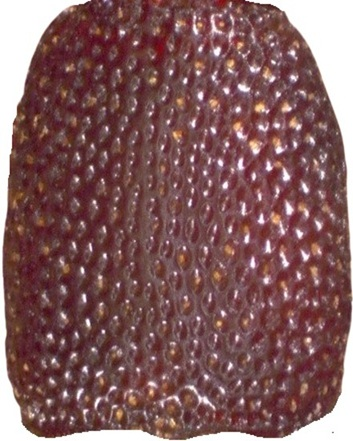

beetle-fragments-numerical-signatures-main/mwt8.jpg | Size: (353, 441) | Mode: RGB


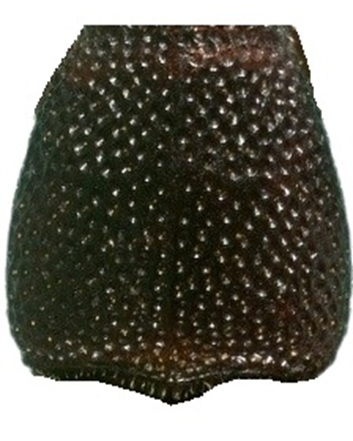

In [ ]:

from PIL import Image
from IPython.display import display
import io

for name in z.namelist():
    if name.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff")):
        with z.open(name) as f:
            img = Image.open(io.BytesIO(f.read()))
            print(name, "| Size:", img.size, "| Mode:", img.mode)
            display(img.copy())


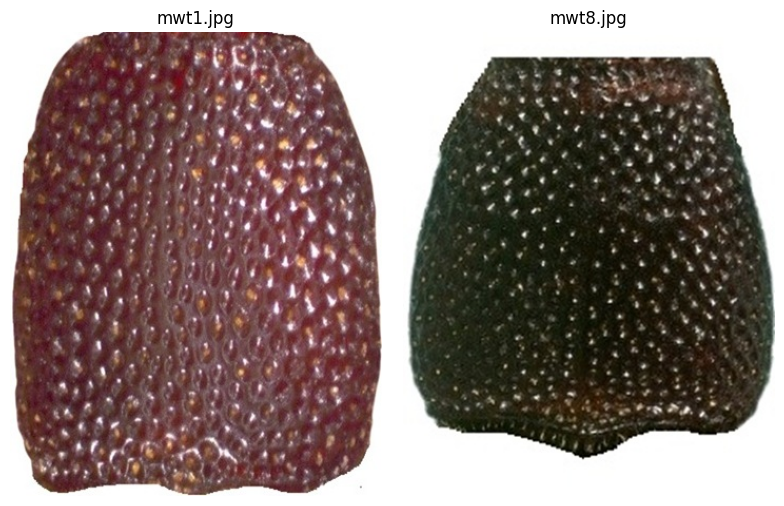

In [ ]:

from PIL import Image
from IPython.display import display
import matplotlib.pyplot as plt
import io

image_names = [
    "beetle-fragments-numerical-signatures-main/mwt1.jpg",
    "beetle-fragments-numerical-signatures-main/mwt8.jpg"
]

fig, axes = plt.subplots(1, 2, figsize=(8, 5))

for ax, name in zip(axes, image_names):
    with z.open(name) as f:
        img = Image.open(io.BytesIO(f.read()))
    ax.imshow(img)
    ax.set_title(name.split("/")[-1])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [".config", "sample_data"]]
    for f in files:
        if f.lower().endswith((".zip", ".tar", ".gz", ".7z")):
            print(os.path.join(root, f))


In [ ]:

from google.colab import files

uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))


Saving 29066444.zip to 29066444.zip
Uploaded files: ['29066444.zip']


In [ ]:

import os
import zipfile

zip_files = [
    f for f in os.listdir("/content")
    if f.lower().endswith(".zip")
]

print("ZIP files found:", zip_files)

for filename in zip_files:
    path = os.path.join("/content", filename)
    print(f"\nFilename: {filename}")
    print(f"Size: {os.path.getsize(path) / (1024**3):.2f} GB")

    with zipfile.ZipFile(path, "r") as archive:
        names = archive.namelist()
        print("Total archive entries:", len(names))
        print("\nFirst 25 entries:")
        for name in names[:25]:
            print(name)


ZIP files found: ['29066444.zip']

Filename: 29066444.zip
Size: 0.00 GB
Total archive entries: 244

First 25 entries:
lo/thorax/1.jpg
lo/thorax/10.jpg
lo/thorax/2.jpg
lo/thorax/3.jpg
lo/thorax/4.jpg
lo/thorax/5.jpg
lo/thorax/6.jpg
lo/thorax/7.jpg
lo/thorax/8.jpg
lo/thorax/9.jpg
lo/har/1.jpg
lo/har/10.jpg
lo/har/2.jpg
lo/har/3.jpg
lo/har/4.jpg
lo/har/5.jpg
lo/har/6.jpg
lo/har/7.jpg
lo/har/8.jpg
lo/har/9.jpg
lo/elytra/1.jpg
tenebrionidae_signature_metrics.csv
lo/elytra/10.jpg
curculionidae_signature_metrics.csv
lo/elytra/2.jpg


In [ ]:

import zipfile
from collections import Counter

zip_path = "/content/29066444.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    files = [n for n in archive.namelist() if not n.endswith("/")]

    print("Total files:", len(files))

    print("\nFile types:")
    print(Counter(
        name.rsplit(".", 1)[-1].lower()
        if "." in name.split("/")[-1] else "(no extension)"
        for name in files
    ))

    print("\nTop-level folders:")
    print(Counter(
        name.split("/")[0] for name in files if "/" in name
    ))

    print("\nCSV and spreadsheet files:")
    for name in files:
        if name.lower().endswith((".csv", ".xlsx", ".xls")):
            print(name)

    print("\nAll image paths:")
    for name in files:
        if name.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff")):
            print(name)


Total files: 244

File types:
Counter({'jpg': 239, 'csv': 4, 'docx': 1})

Top-level folders:
Counter({'lo': 40, 'mw': 40, 'rw': 40, 'tc': 40, 'tco': 40, 'ww': 39})

CSV and spreadsheet files:
tenebrionidae_signature_metrics.csv
curculionidae_signature_metrics.csv
fragment_metadata_curculionidae.csv
fragment_metadata_tenebrionidae.csv

All image paths:
lo/thorax/1.jpg
lo/thorax/10.jpg
lo/thorax/2.jpg
lo/thorax/3.jpg
lo/thorax/4.jpg
lo/thorax/5.jpg
lo/thorax/6.jpg
lo/thorax/7.jpg
lo/thorax/8.jpg
lo/thorax/9.jpg
lo/har/1.jpg
lo/har/10.jpg
lo/har/2.jpg
lo/har/3.jpg
lo/har/4.jpg
lo/har/5.jpg
lo/har/6.jpg
lo/har/7.jpg
lo/har/8.jpg
lo/har/9.jpg
lo/elytra/1.jpg
lo/elytra/10.jpg
lo/elytra/2.jpg
lo/elytra/3.jpg
lo/elytra/4.jpg
lo/elytra/5.jpg
lo/elytra/6.jpg
lo/elytra/7.jpg
lo/elytra/8.jpg
lo/elytra/9.jpg
lo/antennae/1.jpg
lo/antennae/10.jpg
lo/antennae/2.jpg
lo/antennae/3.jpg
lo/antennae/4.jpg
lo/antennae/5.jpg
lo/antennae/6.jpg
lo/antennae/7.jpg
lo/antennae/8.jpg
lo/antennae/9.jpg
mw/thorax/1.

In [ ]:

import zipfile
from collections import Counter
import os

zip_path = "/content/29066444.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    files = [n for n in archive.namelist() if not n.endswith("/")]

    image_files = [
        n for n in files
        if n.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff"))
    ]

    counts = Counter()
    for path in image_files:
        parts = path.split("/")
        if len(parts) >= 3:
            species, fragment = parts[0], parts[1]
            counts[(species, fragment)] += 1

    print("Total files:", len(files))
    print("Total images:", len(image_files))

    print("\nImages per species and fragment:")
    for (species, fragment), count in sorted(counts.items()):
        print(f"{species:5s} | {fragment:10s} | {count}")

    print("\nCSV files:")
    for name in files:
        if name.lower().endswith(".csv"):
            print(name)


Total files: 244
Total images: 239

Images per species and fragment:
lo    | antennae   | 10
lo    | elytra     | 10
lo    | har        | 10
lo    | thorax     | 10
mw    | antennae   | 10
mw    | elytra     | 10
mw    | snout      | 10
mw    | thorax     | 10
rw    | antennae   | 10
rw    | elytra     | 10
rw    | snout      | 10
rw    | thorax     | 10
tc    | antennae   | 10
tc    | elytra     | 10
tc    | har        | 10
tc    | thorax     | 10
tco   | antennae   | 10
tco   | elytra     | 10
tco   | har        | 10
tco   | thorax     | 10
ww    | antennae   | 10
ww    | elytra     | 9
ww    | snout      | 10
ww    | thorax     | 10

CSV files:
tenebrionidae_signature_metrics.csv
curculionidae_signature_metrics.csv
fragment_metadata_curculionidae.csv
fragment_metadata_tenebrionidae.csv


In [ ]:

import zipfile
import pandas as pd
from io import BytesIO

zip_path = "/content/29066444.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    for filename in [
        "curculionidae_signature_metrics.csv",
        "tenebrionidae_signature_metrics.csv",
        "fragment_metadata_curculionidae.csv",
        "fragment_metadata_tenebrionidae.csv"
    ]:
        with archive.open(filename) as f:
            df = pd.read_csv(BytesIO(f.read()))

        print("\n" + "=" * 55)
        print(filename)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(5))



curculionidae_signature_metrics.csv
Shape: (1553, 7)
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']


,ImageName,Skewness,Kurtosis,Entropy,StandardDeviation,Species,Fragment
0,1.jpg,0.996069,2.422996,2.270740,0.115924,mw,antenna
1,2.jpg,-0.055020,1.569616,2.947459,0.069458,mw,antenna
2,3.jpg,-0.128007,1.465497,2.964119,0.068367,mw,antenna
3,4.jpg,-0.077968,1.516452,2.955339,0.069111,mw,antenna
4,5.jpg,-0.083438,1.509684,2.942651,0.069507,mw,antenna



tenebrionidae_signature_metrics.csv
Shape: (1812, 7)
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']


,ImageName,Skewness,Kurtosis,Entropy,StandardDeviation,Species,Fragment
0,1.jpg,0.511828,1.449691,2.373752,0.103700,lo,antenna
1,2.jpg,0.261486,1.468518,2.653571,0.087080,lo,antenna
2,3.jpg,0.166969,1.318187,2.677977,0.085028,lo,antenna
3,4.jpg,0.261625,1.461871,2.651454,0.087202,lo,antenna
4,5.jpg,0.160233,1.280853,2.668759,0.085490,lo,antenna



fragment_metadata_curculionidae.csv
Shape: (1565, 5)
Columns: ['OriginalFile', 'RelativePath', 'AnatomicalRegion', 'Species', 'AugmentationType']


,OriginalFile,RelativePath,AnatomicalRegion,Species,AugmentationType
0,1.jpg,antenna\mw\1.jpg,antenna,Sitophilus zeamais,original
1,1.jpg,antenna\rw\1.jpg,antenna,Sitophilus oryzae,original
2,1.jpg,antenna\ww\1.jpg,antenna,Sitophilus granarius,original
3,1.jpg,elytra\mw\1.jpg,elytra,Sitophilus zeamais,original
4,1.jpg,elytra\rw\1.jpg,elytra,Sitophilus oryzae,original



fragment_metadata_tenebrionidae.csv
Shape: (1823, 5)
Columns: ['OriginalFile', 'RelativePath', 'AnatomicalRegion', 'Species', 'AugmentationType']


,OriginalFile,RelativePath,AnatomicalRegion,Species,AugmentationType
0,1.jpg,antenna\lo\1.jpg,antenna,Latheticus oryzae,original
1,1.jpg,antenna\tc\1.jpg,antenna,Traibolium casteneum,original
2,1.jpg,antenna\tco\1.jpg,antenna,Tribolium confusum,original
3,1.jpg,elytra\lo\1.jpg,elytra,Latheticus oryzae,original
4,1.jpg,elytra\tc\1.jpg,elytra,Traibolium casteneum,original


In [ ]:

import zipfile
import pandas as pd
from io import BytesIO
from collections import Counter

zip_path = "/content/29066444.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    for csv_name in [
        "curculionidae_signature_metrics.csv",
        "tenebrionidae_signature_metrics.csv"
    ]:
        df = pd.read_csv(BytesIO(archive.read(csv_name)))
        df["species"] = df["Species"].astype(str).str.lower()
        df["fragment"] = df["Fragment"].astype(str).str.lower()

        print("\n", csv_name)
        print("Feature-table rows:", len(df))
        print("Records by species and fragment:")
        display(pd.crosstab(df["species"], df["fragment"]))

    print("\nExample image paths:")
    image_paths = [
        p for p in archive.namelist()
        if p.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    for p in image_paths[:20]:
        print(p)



 curculionidae_signature_metrics.csv
Feature-table rows: 1553
Records by species and fragment:


fragment,antenna,elytra,snout,thorax
species,,,,
mw,144,108,192,138
rw,138,144,150,108
ww,114,89,114,114



 tenebrionidae_signature_metrics.csv
Feature-table rows: 1812
Records by species and fragment:


fragment,antenna,elytra,har,thorax
species,,,,
lo,162,168,210,180
tc,168,150,162,162
tco,120,114,102,114



Example image paths:
lo/thorax/1.jpg
lo/thorax/10.jpg
lo/thorax/2.jpg
lo/thorax/3.jpg
lo/thorax/4.jpg
lo/thorax/5.jpg
lo/thorax/6.jpg
lo/thorax/7.jpg
lo/thorax/8.jpg
lo/thorax/9.jpg
lo/har/1.jpg
lo/har/10.jpg
lo/har/2.jpg
lo/har/3.jpg
lo/har/4.jpg
lo/har/5.jpg
lo/har/6.jpg
lo/har/7.jpg
lo/har/8.jpg
lo/har/9.jpg


In [ ]:

import zipfile
import pandas as pd
from io import BytesIO
from pathlib import PurePosixPath

zip_path = "/content/29066444.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    image_paths = [
        p for p in archive.namelist()
        if p.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    images = pd.DataFrame({
        "path": image_paths,
        "species": [PurePosixPath(p).parts[0].lower() for p in image_paths],
        "fragment": [PurePosixPath(p).parts[1].lower() for p in image_paths],
        "ImageName": [PurePosixPath(p).name.lower() for p in image_paths]
    })

    # Standardize fragment labels
    images["fragment"] = images["fragment"].replace({
        "antennae": "antenna"
    })

    for csv_name in [
        "curculionidae_signature_metrics.csv",
        "tenebrionidae_signature_metrics.csv"
    ]:
        features = pd.read_csv(BytesIO(archive.read(csv_name)))
        features["species"] = features["Species"].astype(str).str.lower()
        features["fragment"] = features["Fragment"].astype(str).str.lower()
        features["ImageName"] = features["ImageName"].astype(str).str.lower()

        family_species = set(features["species"].unique())
        family_images = images[images["species"].isin(family_species)].copy()

        matched = family_images.merge(
            features[["species", "fragment", "ImageName"]],
            on=["species", "fragment", "ImageName"],
            how="left",
            indicator=True
        )

        print("\n", csv_name)
        print("Archived images:", len(family_images))
        print("Images matching a feature-table key:",
              (matched["_merge"] == "both").sum())
        print("Images without a matching feature-table key:",
              (matched["_merge"] == "left_only").sum())

        print("\nMatch counts by species and fragment:")
        print(
            matched.assign(
                matched=matched["_merge"].eq("both")
            ).groupby(["species", "fragment"])["matched"]
            .agg(["count", "sum"])
        )



 curculionidae_signature_metrics.csv
Archived images: 119
Images matching a feature-table key: 119
Images without a matching feature-table key: 0

Match counts by species and fragment:
                  count  sum
species fragment            
mw      antenna      10   10
        elytra       10   10
        snout        10   10
        thorax       10   10
rw      antenna      10   10
        elytra       10   10
        snout        10   10
        thorax       10   10
ww      antenna      10   10
        elytra        9    9
        snout        10   10
        thorax       10   10

 tenebrionidae_signature_metrics.csv
Archived images: 120
Images matching a feature-table key: 120
Images without a matching feature-table key: 0

Match counts by species and fragment:
                  count  sum
species fragment            
lo      antenna      10   10
        elytra       10   10
        har          10   10
        thorax       10   10
tc      antenna      10   10
        elytra     

In [ ]:

import zipfile
import pandas as pd
import numpy as np
from io import BytesIO
from pathlib import PurePosixPath
from PIL import Image
from scipy.stats import skew, kurtosis

zip_path = "/content/29066444.zip"

def calculate_features(image_bytes):
    img = Image.open(BytesIO(image_bytes)).convert("L")
    pixels = np.asarray(img, dtype=np.float64).ravel()

    # Pixel-intensity descriptors; entropy uses 256 grayscale bins
    hist = np.bincount(pixels.astype(np.uint8), minlength=256)
    probabilities = hist[hist > 0] / hist.sum()
    entropy = -(probabilities * np.log2(probabilities)).sum()

    return {
        "Skewness_calc": skew(pixels, bias=True),
        "Kurtosis_calc": kurtosis(pixels, fisher=True, bias=True),
        "Entropy_calc": entropy,
        "StandardDeviation_calc": pixels.std(ddof=0)
    }

with zipfile.ZipFile(zip_path, "r") as archive:
    image_paths = [
        p for p in archive.namelist()
        if p.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    results = []

    for path in image_paths:
        parts = PurePosixPath(path).parts
        species = parts[0].lower()
        fragment = parts[1].lower().replace("antennae", "antenna")
        image_name = parts[-1].lower()

        csv_name = (
            "curculionidae_signature_metrics.csv"
            if species in {"mw", "rw", "ww"}
            else "tenebrionidae_signature_metrics.csv"
        )

        features = pd.read_csv(BytesIO(archive.read(csv_name)))
        features["species_key"] = features["Species"].astype(str).str.lower()
        features["fragment_key"] = features["Fragment"].astype(str).str.lower()
        features["image_key"] = features["ImageName"].astype(str).str.lower()

        row = features[
            (features["species_key"] == species) &
            (features["fragment_key"] == fragment) &
            (features["image_key"] == image_name)
        ]

        if len(row) != 1:
            continue

        calculated = calculate_features(archive.read(path))
        record = {
            "path": path,
            **calculated,
            "Skewness_csv": row.iloc[0]["Skewness"],
            "Kurtosis_csv": row.iloc[0]["Kurtosis"],
            "Entropy_csv": row.iloc[0]["Entropy"],
            "StandardDeviation_csv": row.iloc[0]["StandardDeviation"]
        }
        results.append(record)

comparison = pd.DataFrame(results)

for name in ["Skewness", "Kurtosis", "Entropy", "StandardDeviation"]:
    a = comparison[f"{name}_calc"].to_numpy()
    b = comparison[f"{name}_csv"].to_numpy()
    print(
        f"{name}: mean absolute difference = "
        f"{np.mean(np.abs(a - b)):.6f}"
    )

display(comparison.head(10))


Skewness: mean absolute difference = 2.830282
Kurtosis: mean absolute difference = 10.236644
Entropy: mean absolute difference = 1.532169
StandardDeviation: mean absolute difference = 61.225719


,path,Skewness_calc,Kurtosis_calc,Entropy_calc,StandardDeviation_calc,Skewness_csv,Kurtosis_csv,Entropy_csv,StandardDeviation_csv
0,lo/thorax/1.jpg,-0.606176,-1.562640,3.635755,84.220307,1.074051,3.110038,2.640836,0.097692
1,lo/thorax/10.jpg,-0.689177,-1.403390,3.769951,69.967580,0.365640,1.464675,2.671954,0.088543
2,lo/thorax/2.jpg,-1.901358,1.664418,1.797734,57.998040,0.241888,1.713552,3.260480,0.055893
3,lo/thorax/3.jpg,-1.899644,1.678538,1.936333,57.581258,0.246828,1.710978,3.258116,0.056120
4,lo/thorax/4.jpg,-1.905237,1.690059,1.916164,54.651804,0.242226,1.712161,3.259185,0.055997
5,lo/thorax/5.jpg,-1.901903,1.672328,1.918039,57.978354,0.242279,1.715639,3.259710,0.055946
6,lo/thorax/6.jpg,-1.901902,1.672313,1.914566,57.978600,0.242912,1.712966,3.259460,0.055978
7,lo/thorax/7.jpg,-1.901997,1.672672,1.915079,57.988152,0.241860,1.715814,3.259417,0.055964
8,lo/thorax/8.jpg,-0.678148,-1.432812,3.605097,74.186948,0.371242,1.460379,2.666819,0.088888
9,lo/thorax/9.jpg,-0.673364,-1.434525,3.766569,73.734938,0.374444,1.467553,2.682585,0.088289


In [ ]:

import zipfile
import numpy as np
import pandas as pd
from io import BytesIO
from PIL import Image
from scipy.stats import skew, kurtosis

zip_path = "/content/29066444.zip"
target = "lo/thorax/1.jpg"

with zipfile.ZipFile(zip_path, "r") as archive:
    pixels = np.asarray(
        Image.open(BytesIO(archive.read(target))).convert("L"),
        dtype=np.float64
    ).ravel()

    csv = pd.read_csv(
        BytesIO(archive.read("tenebrionidae_signature_metrics.csv"))
    )
    row = csv[
        (csv["Species"].str.lower() == "lo") &
        (csv["Fragment"].str.lower() == "thorax") &
        (csv["ImageName"].str.lower() == "1.jpg")
    ].iloc[0]

    normalized = pixels / 255.0

    # Correctly compute histogram first to avoid indexing with a lambda function
    hist = np.bincount(pixels.astype(np.uint8), minlength=256)
    probabilities = hist[hist > 0] / hist.sum()
    calculated_entropy = -np.sum(probabilities * np.log2(probabilities))

    comparison = pd.DataFrame({
        "Feature": ["Skewness", "Pearson kurtosis", "Entropy",
                    "Standard deviation (0–1 scale)"],
        "Recalculated": [
            skew(normalized),
            kurtosis(normalized, fisher=False),
            calculated_entropy,
            normalized.std()
        ],
        "CSV": [
            row["Skewness"], row["Kurtosis"],
            row["Entropy"], row["StandardDeviation"]
        ]
    })

display(comparison)

,Feature,Recalculated,CSV
0,Skewness,-0.606176,1.074051
1,Pearson kurtosis,1.437360,3.110038
2,Entropy,3.635755,2.640836
3,Standard deviation (0–1 scale),0.330276,0.097692


In [ ]:

# Inspect the repository ZIP already stored in variable `z`
# If `z` is unavailable, see the fallback below.

for name in z.namelist():
    low = name.lower()
    if low.endswith((".m", ".py", ".md", ".txt")):
        print(name)


beetle-fragments-numerical-signatures-main/README.md
beetle-fragments-numerical-signatures-main/roi_extract_augment.m
beetle-fragments-numerical-signatures-main/signature_extract.m
beetle-fragments-numerical-signatures-main/utils/metadata_checks.m


In [ ]:

files_to_inspect = [
    "beetle-fragments-numerical-signatures-main/README.md",
    "beetle-fragments-numerical-signatures-main/signature_extract.m",
    "beetle-fragments-numerical-signatures-main/roi_extract_augment.m",
]

for filename in files_to_inspect:
    print("\n" + "=" * 80)
    print(filename)
    print("=" * 80)
    print(z.read(filename).decode("utf-8", errors="replace"))



beetle-fragments-numerical-signatures-main/README.md
# beetle-fragments-numerical-signatures

MATLAB scripts for ROI extraction, augmentation, metadata logging, and numerical signature computation (skewness, kurtosis, entropy, std) for Curculionidae and Tenebrionidae beetle fragment dataset.

## Requirements
- MATLAB R2024b (tested)
- Image Processing Toolbox



beetle-fragments-numerical-signatures-main/signature_extract.m
%% signature_extract.m
% Compute numerical signature descriptors from fragment images
% Output: fragment_signatures.csv
% Author: Ronnie Serfa Juan

clear; clc;

% === Step 1: Select Folder with Fragment Images ===
imgFolder = uigetdir([], 'Select Folder with Fragment Images');
if imgFolder == 0
    error('No folder selected.');
end

% === Step 2: Prepare Image List ===
imgFiles = dir(fullfile(imgFolder, '*.png')); % or .jpg
if isempty(imgFiles)
    error('No PNG/JPG images found in the selected folder.');
end

% === Step 3: Initialize Results Table ===
results = {

In [ ]:

import zipfile
import pandas as pd
import numpy as np
from io import BytesIO
from PIL import Image
from scipy.stats import skew, kurtosis

zip_path = "/content/29066444.zip"
image_path = "lo/thorax/1.jpg"

with zipfile.ZipFile(zip_path, "r") as archive:
    img = Image.open(BytesIO(archive.read(image_path)))
    print("Image mode:", img.mode)
    print("Image dimensions:", img.size)

    gray = np.asarray(img.convert("L"), dtype=np.float64)
    print("Grayscale intensity range:", gray.min(), "to", gray.max())

    pixels = gray.ravel()
    print("\nRecalculated raw-image statistics:")
    print("Skewness:", skew(pixels, bias=False))
    print("Pearson kurtosis:", kurtosis(pixels, fisher=False, bias=False))
    print("Standard deviation:", gray.std(ddof=1))

    df = pd.read_csv(
        BytesIO(archive.read("tenebrionidae_signature_metrics.csv"))
    )
    row = df[
        (df["Species"].str.lower() == "lo") &
        (df["Fragment"].str.lower() == "thorax") &
        (df["ImageName"].str.lower() == "1.jpg")
    ]

    print("\nCorresponding CSV row:")
    display(row)


Image mode: RGB
Image dimensions: (256, 256)
Grayscale intensity range: 36.0 to 255.0

Recalculated raw-image statistics:
Skewness: -0.6061894975946572
Pearson kurtosis: 1.437332728981638
Standard deviation: 84.22094984786914

Corresponding CSV row:


,ImageName,Skewness,Kurtosis,Entropy,StandardDeviation,Species,Fragment
540,1.jpg,1.074051,3.110038,2.640836,0.097692,lo,thorax


In [ ]:

for filename in [
    "beetle-fragments-numerical-signatures-main/roi_extract_augment.m",
    "beetle-fragments-numerical-signatures-main/utils/metadata_checks.m"
]:
    print("\n" + "=" * 70)
    print(filename)
    print("=" * 70)

    lines = z.read(filename).decode("utf-8", errors="replace").splitlines()

    for i, line in enumerate(lines, start=1):
        print(f"{i:03}: {line}")



beetle-fragments-numerical-signatures-main/roi_extract_augment.m
001: %% roi_extract_augment.m
002: % Interactive ROI extraction, augmentation, and metadata logging
003: % Output: fragment_metadata.csv and augmented fragment images
004: % Author: Ronnie O. Serfa Juan
005: 
006: clc; clear; close all;
007: 
008: % === Step 1: Select Input & Output Folder ===
009: imgFolder = uigetdir([], 'Select Folder with Insect Images');
010: saveFolder = uigetdir([], 'Select Folder to Save Extracted and Augmented Fragments');
011: 
012: if imgFolder == 0 || saveFolder == 0
013:     error('Both input and output folders must be selected.');
014: end
015: 
016: % === Step 2: Prepare Image List and Metadata Header ===
017: imgFiles = dir(fullfile(imgFolder, '*.jpg'));  % can also use *.png
018: metadata = {'OriginalImage','FragmentImage','AnatomicalRegion','Species','AugmentationType'};
019: 
020: % === Step 3: Process Each Image ===
021: for i = 1:length(imgFiles)
022:     filename = imgFiles(i).name;

In [ ]:

filename = (
    "beetle-fragments-numerical-signatures-main/"
    "roi_extract_augment.m"
)

lines = z.read(filename).decode("utf-8", errors="replace").splitlines()

for i, line in enumerate(lines[45:], start=46):
    print(f"{i:03}: {line}")


046:     ba


In [ ]:

filename = (
    "beetle-fragments-numerical-signatures-main/"
    "roi_extract_augment.m"
)

content = z.read(filename).decode("utf-8", errors="replace")
print("Total lines:", len(content.splitlines()))
print("File size:", len(content), "characters")
print("\nLast 500 characters:\n")
print(content[-500:])


Total lines: 46
File size: 1612 characters

Last 500 characters:

   close;

    % Ask user for anatomical region and species
    prompt = {'Enter anatomical region (e.g., thorax, elytra, snout):', ...
              'Enter species name (e.g., Sitophilus_zeamais):'};
    dlgtitle = 'Fragment Metadata';
    dims = [1 50];
    definput = {'thorax','Sitophilus_zeamais'};
    answer = inputdlg(prompt, dlgtitle, dims, definput);

    anatomical = strrep(lower(answer{1}), ' ', '_');
    species = strrep(lower(answer{2}), ' ', '_');

    % Define base filename
    ba



In [ ]:

import zipfile
import pandas as pd
from io import BytesIO

zip_path = "/content/29066444.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    for filename in [
        "curculionidae_signature_metrics.csv",
        "tenebrionidae_signature_metrics.csv"
    ]:
        df = pd.read_csv(BytesIO(archive.read(filename)))

        print("\n", filename)
        for col in [
            "Skewness", "Kurtosis", "Entropy", "StandardDeviation"
        ]:
            print(f"\n{col}")
            print(df[col].describe().round(5))



 curculionidae_signature_metrics.csv

Skewness
count    1553.00000
mean        0.21887
std         0.31215
min        -0.94961
25%         0.06029
50%         0.19371
75%         0.29581
max         1.47213
Name: Skewness, dtype: float64

Kurtosis
count    1553.00000
mean        1.76140
std         0.30936
min         1.17352
25%         1.60300
50%         1.71207
75%         1.81162
max         3.55894
Name: Kurtosis, dtype: float64

Entropy
count    1553.00000
mean        3.03207
std         0.25793
min         1.97365
25%         2.94099
50%         3.09618
75%         3.24774
max         3.48138
Name: Entropy, dtype: float64

StandardDeviation
count    1553.00000
mean        0.06816
std         0.01576
min         0.03043
25%         0.05633
50%         0.06342
75%         0.07350
max         0.13849
Name: StandardDeviation, dtype: float64

 tenebrionidae_signature_metrics.csv

Skewness
count    1812.00000
mean        0.38199
std         0.34445
min        -0.46479
25%         0.

In [ ]:

import zipfile
import pandas as pd
from io import BytesIO

zip_path = "/content/29066444.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    files = {
        "Curculionidae": "curculionidae_signature_metrics.csv",
        "Tenebrionidae": "tenebrionidae_signature_metrics.csv"
    }

    feature_cols = [
        "Skewness", "Kurtosis", "Entropy", "StandardDeviation"
    ]

    for family, filename in files.items():
        df = pd.read_csv(BytesIO(archive.read(filename)))

        print("\n" + "=" * 55)
        print(family)
        print("=" * 55)
        print("Total records:", len(df))

        # Exact duplicate rows across all columns
        print("Exact duplicate rows:", df.duplicated().sum())

        # Identical numerical vectors, regardless of species or fragment
        print(
            "Duplicate numerical feature vectors:",
            df.duplicated(subset=feature_cols, keep=False).sum()
        )

        # Identical vectors belonging to different species
        grouped = df.groupby(feature_cols, dropna=False)
        cross_label_duplicates = grouped.filter(
            lambda g: g["Species"].nunique() > 1
        )

        print(
            "Records in repeated vectors shared across species:",
            len(cross_label_duplicates)
        )

        if len(cross_label_duplicates):
            display(
                cross_label_duplicates[
                    ["ImageName", "Species", "Fragment"] + feature_cols
                ].head(15)
            )



Curculionidae
Total records: 1553
Exact duplicate rows: 0
Duplicate numerical feature vectors: 0
Records in repeated vectors shared across species: 0

Tenebrionidae
Total records: 1812
Exact duplicate rows: 0
Duplicate numerical feature vectors: 0
Records in repeated vectors shared across species: 0


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving 29066444.zip to 29066444 (1).zip


In [ ]:

import os

print("ZIP file available:", os.path.exists("/content/29066444.zip"))


ZIP file available: True


In [ ]:

import zipfile
import pandas as pd
from io import BytesIO

zip_path = "/content/29066444.zip"

feature_cols = [
    "Skewness", "Kurtosis", "Entropy", "StandardDeviation"
]

with zipfile.ZipFile(zip_path, "r") as archive:
    files_to_check = {
        "Curculionidae": "curculionidae_signature_metrics.csv",
        "Tenebrionidae": "tenebrionidae_signature_metrics.csv"
    }

    for family, filename in files_to_check.items():
        df = pd.read_csv(BytesIO(archive.read(filename)))

        print("\n" + "=" * 50)
        print(family)
        print("=" * 50)
        print("Total records:", len(df))
        print("Exact duplicate rows:", df.duplicated().sum())

        duplicate_mask = df.duplicated(
            subset=feature_cols, keep=False
        )
        print("Records with repeated feature vectors:", duplicate_mask.sum())

        repeated = df.loc[duplicate_mask].copy()
        if not repeated.empty:
            print(
                "Repeated vectors shared across species:",
                repeated.groupby(feature_cols)["Species"]
                .nunique().gt(1).sum()
            )
            display(
                repeated[
                    ["ImageName", "Species", "Fragment"] + feature_cols
                ].head(10)
            )



Curculionidae
Total records: 1553
Exact duplicate rows: 0
Records with repeated feature vectors: 0

Tenebrionidae
Total records: 1812
Exact duplicate rows: 0
Records with repeated feature vectors: 0


In [ ]:

import zipfile
import pandas as pd
from io import BytesIO

zip_path = "/content/29066444.zip"

feature_cols = [
    "Skewness", "Kurtosis", "Entropy", "StandardDeviation"
]

with zipfile.ZipFile(zip_path, "r") as archive:
    for family, filename in {
        "Curculionidae": "curculionidae_signature_metrics.csv",
        "Tenebrionidae": "tenebrionidae_signature_metrics.csv"
    }.items():

        df = pd.read_csv(BytesIO(archive.read(filename)))
        rounded = df[feature_cols].round(3)

        duplicate_mask = rounded.duplicated(keep=False)
        flagged = df.loc[duplicate_mask].copy()
        flagged["rounded_signature"] = list(
            rounded.loc[duplicate_mask].itertuples(
                index=False, name=None
            )
        )

        print("\n" + "=" * 50)
        print(family)
        print("=" * 50)
        print("Records flagged after rounding:", len(flagged))
        print("Distinct rounded signatures repeated:",
              flagged["rounded_signature"].nunique())

        if not flagged.empty:
            print("Repeated signatures appearing across species:",
                  flagged.groupby("rounded_signature")["Species"]
                  .nunique().gt(1).sum())

            display(
                flagged[
                    ["ImageName", "Species", "Fragment"]
                    + feature_cols + ["rounded_signature"]
                ].head(15)
            )



Curculionidae
Records flagged after rounding: 94
Distinct rounded signatures repeated: 41
Repeated signatures appearing across species: 0


,ImageName,Species,Fragment,Skewness,Kurtosis,Entropy,StandardDeviation,rounded_signature
8,9.jpg,mw,antenna,0.211354,1.831324,3.286046,0.053411,"(0.211, 1.831, 3.286, 0.053)"
11,12.jpg,mw,antenna,0.211498,1.831077,3.286079,0.053409,"(0.211, 1.831, 3.286, 0.053)"
34,35.jpg,mw,antenna,0.211705,1.710472,3.270558,0.054897,"(0.212, 1.71, 3.271, 0.055)"
35,36.jpg,mw,antenna,0.212157,1.710189,3.270764,0.054882,"(0.212, 1.71, 3.271, 0.055)"
36,37.jpg,mw,antenna,0.211869,1.710388,3.270544,0.054899,"(0.212, 1.71, 3.271, 0.055)"
43,44.jpg,mw,antenna,0.209594,1.716371,3.271026,0.054811,"(0.21, 1.716, 3.271, 0.055)"
47,48.jpg,mw,antenna,0.209592,1.715900,3.270924,0.054820,"(0.21, 1.716, 3.271, 0.055)"
70,71.jpg,mw,antenna,0.224233,1.739086,3.270722,0.054895,"(0.224, 1.739, 3.271, 0.055)"
72,73.jpg,mw,antenna,0.223854,1.738910,3.270728,0.054892,"(0.224, 1.739, 3.271, 0.055)"
98,99.jpg,mw,antenna,0.190719,1.693202,3.271521,0.054707,"(0.191, 1.693, 3.272, 0.055)"



Tenebrionidae
Records flagged after rounding: 171
Distinct rounded signatures repeated: 73
Repeated signatures appearing across species: 2


,ImageName,Species,Fragment,Skewness,Kurtosis,Entropy,StandardDeviation,rounded_signature
39,40.jpg,lo,antenna,0.148837,1.739095,3.286760,0.053093,"(0.149, 1.739, 3.287, 0.053)"
40,41.jpg,lo,antenna,0.147718,1.739554,3.287033,0.053063,"(0.148, 1.74, 3.287, 0.053)"
41,42.jpg,lo,antenna,0.148829,1.738958,3.286743,0.053095,"(0.149, 1.739, 3.287, 0.053)"
42,43.jpg,lo,antenna,0.148185,1.740316,3.287011,0.053067,"(0.148, 1.74, 3.287, 0.053)"
87,88.jpg,lo,antenna,0.155263,1.737472,3.284551,0.053311,"(0.155, 1.737, 3.285, 0.053)"
88,89.jpg,lo,antenna,0.155554,1.738503,3.284576,0.053310,"(0.156, 1.739, 3.285, 0.053)"
89,90.jpg,lo,antenna,0.155374,1.737441,3.284539,0.053313,"(0.155, 1.737, 3.285, 0.053)"
90,91.jpg,lo,antenna,0.155985,1.738829,3.284517,0.053317,"(0.156, 1.739, 3.285, 0.053)"
91,92.jpg,lo,antenna,0.093900,1.680736,3.290720,0.052516,"(0.094, 1.681, 3.291, 0.053)"
92,93.jpg,lo,antenna,0.093059,1.679777,3.290799,0.052506,"(0.093, 1.68, 3.291, 0.053)"


In [ ]:

import zipfile
import pandas as pd
from io import BytesIO

zip_path = "/content/29066444.zip"
feature_cols = [
    "Skewness", "Kurtosis", "Entropy", "StandardDeviation"
]

with zipfile.ZipFile(zip_path, "r") as archive:
    filename = "tenebrionidae_signature_metrics.csv"
    df = pd.read_csv(BytesIO(archive.read(filename)))

    df["rounded_signature"] = list(
        df[feature_cols].round(3).itertuples(
            index=False, name=None
        )
    )

    cross_species = (
        df.groupby("rounded_signature")
        .filter(lambda group: group["Species"].nunique() > 1)
        .sort_values("rounded_signature")
    )

    print("Records in cross-species rounded matches:",
          len(cross_species))

    display(
        cross_species[
            ["ImageName", "Species", "Fragment"]
            + feature_cols + ["rounded_signature"]
        ].sort_values(["Species", "Fragment", "ImageName"])
    )


Records in cross-species rounded matches: 7


,ImageName,Species,Fragment,Skewness,Kurtosis,Entropy,StandardDeviation,rounded_signature
751,34.jpg,tc,antenna,0.158454,1.738028,3.284764,0.053311,"(0.158, 1.738, 3.285, 0.053)"
755,38.jpg,tc,antenna,0.158192,1.738467,3.284858,0.053302,"(0.158, 1.738, 3.285, 0.053)"
769,52.jpg,tc,antenna,0.158078,1.738164,3.285134,0.053280,"(0.158, 1.738, 3.285, 0.053)"
770,53.jpg,tc,antenna,0.159388,1.739718,3.285120,0.053288,"(0.159, 1.74, 3.285, 0.053)"
773,56.jpg,tc,antenna,0.158428,1.738254,3.285087,0.053286,"(0.158, 1.738, 3.285, 0.053)"
1466,3.jpg,tco,antenna,0.158472,1.738452,3.285274,0.053276,"(0.158, 1.738, 3.285, 0.053)"
1468,5.jpg,tco,antenna,0.159373,1.739636,3.285311,0.053277,"(0.159, 1.74, 3.285, 0.053)"


In [ ]:

import zipfile
import pandas as pd
import numpy as np
from io import BytesIO
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances

zip_path = "/content/29066444.zip"
features = ["Skewness", "Kurtosis", "Entropy", "StandardDeviation"]

with zipfile.ZipFile(zip_path, "r") as archive:
    df = pd.read_csv(
        BytesIO(archive.read("tenebrionidae_signature_metrics.csv"))
    )

antenna = df[df["Fragment"].str.lower() == "antenna"].copy()
X = StandardScaler().fit_transform(antenna[features])
distances = pairwise_distances(X)

species = antenna["Species"].astype(str).to_numpy()
np.fill_diagonal(distances, np.inf)

results = []

for i in range(len(antenna)):
    other_species = species != species[i]
    valid_distances = distances[i].copy()
    valid_distances[~other_species] = np.inf

    j = np.argmin(valid_distances)
    results.append({
        "Species": species[i],
        "ImageName": antenna.iloc[i]["ImageName"],
        "Nearest_other_species": species[j],
        "Nearest_other_image": antenna.iloc[j]["ImageName"],
        "Standardized_distance": distances[i, j]
    })

nearest = pd.DataFrame(results)

print("Nearest cross-species distance summary:")
print(nearest["Standardized_distance"].describe().round(4))

print("\nSmallest cross-species distances:")
display(nearest.nsmallest(15, "Standardized_distance"))


Nearest cross-species distance summary:
count    450.0000
mean       0.3028
std        0.5032
min        0.0007
25%        0.0097
50%        0.0907
75%        0.3915
max        3.2863
Name: Standardized_distance, dtype: float64

Smallest cross-species distances:


,Species,ImageName,Nearest_other_species,Nearest_other_image,Standardized_distance
212,tc,53.jpg,tco,5.jpg,0.000657
334,tco,5.jpg,tc,53.jpg,0.000657
215,tc,56.jpg,tco,3.jpg,0.000866
332,tco,3.jpg,tc,56.jpg,0.000866
211,tc,52.jpg,tco,3.jpg,0.001589
119,lo,120.jpg,tc,80.jpg,0.001649
238,tc,80.jpg,lo,120.jpg,0.001649
197,tc,38.jpg,tco,3.jpg,0.001666
111,lo,112.jpg,tc,127.jpg,0.001711
282,tc,127.jpg,lo,112.jpg,0.001711


In [ ]:

import zipfile
import pandas as pd
import numpy as np
from io import BytesIO
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances

zip_path = "/content/29066444.zip"
features = ["Skewness", "Kurtosis", "Entropy", "StandardDeviation"]

with zipfile.ZipFile(zip_path, "r") as archive:
    df = pd.read_csv(
        BytesIO(archive.read("tenebrionidae_signature_metrics.csv"))
    )

antenna = df[df["Fragment"].str.lower() == "antenna"].reset_index(drop=True)
X = StandardScaler().fit_transform(antenna[features])
D = pairwise_distances(X)

sp = antenna["Species"].astype(str).to_numpy()
pairs = []

for i in range(len(antenna)):
    for j in range(i + 1, len(antenna)):
        if sp[i] != sp[j]:
            pairs.append((D[i, j], i, j))

pairs.sort(key=lambda x: x[0])

for distance, i, j in pairs[:10]:
    a, b = antenna.iloc[i], antenna.iloc[j]
    print(
        f"\n{a['Species']} {a['ImageName']} vs "
        f"{b['Species']} {b['ImageName']} | "
        f"standardized distance = {distance:.6f}"
    )
    print("A:", a[features].to_dict())
    print("B:", b[features].to_dict())
    print("Absolute differences:",
          (a[features] - b[features]).abs().to_dict())



tc 53.jpg vs tco 5.jpg | standardized distance = 0.000657
A: {'Skewness': 0.159388404, 'Kurtosis': 1.739718063, 'Entropy': 3.285120364, 'StandardDeviation': 0.053287513}
B: {'Skewness': 0.159373048, 'Kurtosis': 1.739635971, 'Entropy': 3.285310752, 'StandardDeviation': 0.053277365}
Absolute differences: {'Skewness': 1.5356000000021908e-05, 'Kurtosis': 8.209199999997807e-05, 'Entropy': 0.0001903880000000413, 'StandardDeviation': 1.014800000000149e-05}

tc 56.jpg vs tco 3.jpg | standardized distance = 0.000866
A: {'Skewness': 0.158428168, 'Kurtosis': 1.738253541, 'Entropy': 3.285086636, 'StandardDeviation': 0.053286189}
B: {'Skewness': 0.158471594, 'Kurtosis': 1.738451519, 'Entropy': 3.285273597, 'StandardDeviation': 0.05327628}
Absolute differences: {'Skewness': 4.342599999998531e-05, 'Kurtosis': 0.00019797800000009858, 'Entropy': 0.00018696100000026306, 'StandardDeviation': 9.90899999999545e-06}

tc 52.jpg vs tco 3.jpg | standardized distance = 0.001589
A: {'Skewness': 0.158077836, 'Ku

In [ ]:

import zipfile
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

zip_path = "/content/29066444.zip"

# Inspect the archive paths first so we don't assume folder structure.
with zipfile.ZipFile(zip_path, "r") as z:
    matches = [
        n for n in z.namelist()
        if n.lower().endswith((".jpg", ".jpeg", ".png"))
        and (
            ("tc" in n.lower() and "53.jpg" in n.lower())
            or ("tco" in n.lower() and "5.jpg" in n.lower())
            or ("tc" in n.lower() and "56.jpg" in n.lower())
            or ("tco" in n.lower() and "3.jpg" in n.lower())
        )
    ]

    print("Candidate image paths:")
    for p in matches:
        print(p)


Candidate image paths:
tco/thorax/3.jpg
tco/thorax/5.jpg
tco/har/3.jpg
tco/har/5.jpg
tco/elytra/3.jpg
tco/elytra/5.jpg
tco/antennae/3.jpg
tco/antennae/5.jpg


In [ ]:

import zipfile
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt
import numpy as np

zip_path = "/content/29066444.zip"

pairs = [
    ("tc/antennae/53.jpg", "tco/antennae/5.jpg"),
    ("tc/antennae/56.jpg", "tco/antennae/3.jpg"),
]

with zipfile.ZipFile(zip_path, "r") as z:
    files = set(z.namelist())

    for path_a, path_b in pairs:
        print(f"\nComparing: {path_a} vs {path_b}")

        if path_a not in files or path_b not in files:
            print("One or both paths not found.")
            print("Matching paths:")
            for p in sorted(files):
                if p.endswith(("53.jpg", "56.jpg", "5.jpg", "3.jpg")) \
                   and ("antennae/" in p):
                    print(p)
            continue

        img_a = Image.open(BytesIO(z.read(path_a))).convert("RGB")
        img_b = Image.open(BytesIO(z.read(path_b))).convert("RGB")

        print("Image sizes:", img_a.size, img_b.size)

        fig, ax = plt.subplots(1, 2, figsize=(8, 4))
        ax[0].imshow(img_a)
        ax[0].set_title(path_a)
        ax[0].axis("off")

        ax[1].imshow(img_b)
        ax[1].set_title(path_b)
        ax[1].axis("off")

        plt.tight_layout()
        plt.show()

        if img_a.size == img_b.size:
            a = np.asarray(img_a, dtype=np.int16)
            b = np.asarray(img_b, dtype=np.int16)
            print("Pixel-wise identical:", np.array_equal(a, b))
            print("Mean absolute pixel difference:",
                  round(np.abs(a - b).mean(), 4))



Comparing: tc/antennae/53.jpg vs tco/antennae/5.jpg
One or both paths not found.
Matching paths:
lo/antennae/3.jpg
lo/antennae/5.jpg
mw/antennae/3.jpg
mw/antennae/5.jpg
rw/antennae/3.jpg
rw/antennae/5.jpg
tc/antennae/3.jpg
tc/antennae/5.jpg
tco/antennae/3.jpg
tco/antennae/5.jpg
ww/antennae/3.jpg
ww/antennae/5.jpg

Comparing: tc/antennae/56.jpg vs tco/antennae/3.jpg
One or both paths not found.
Matching paths:
lo/antennae/3.jpg
lo/antennae/5.jpg
mw/antennae/3.jpg
mw/antennae/5.jpg
rw/antennae/3.jpg
rw/antennae/5.jpg
tc/antennae/3.jpg
tc/antennae/5.jpg
tco/antennae/3.jpg
tco/antennae/5.jpg
ww/antennae/3.jpg
ww/antennae/5.jpg


In [ ]:

import zipfile
import pandas as pd
from io import BytesIO

zip_path = "/content/29066444.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    print("CSV rows for the suspicious records:")
    df = pd.read_csv(
        BytesIO(z.read("tenebrionidae_signature_metrics.csv"))
    )
    mask = (
        ((df["Species"] == "tc") & df["ImageName"].isin(["53.jpg", "56.jpg"]))
        | ((df["Species"] == "tco") & df["ImageName"].isin(["3.jpg", "5.jpg"]))
    )
    display(df.loc[mask])

    print("\nActual tc antenna image files:")
    for p in sorted(z.namelist()):
        if p.startswith("tc/antennae/"):
            print(p)

    print("\nActual tco antenna image files:")
    for p in sorted(z.namelist()):
        if p.startswith("tco/antennae/"):
            print(p)


CSV rows for the suspicious records:


,ImageName,Skewness,Kurtosis,Entropy,StandardDeviation,Species,Fragment
770,53.jpg,0.159388,1.739718,3.285120,0.053288,tc,antenna
773,56.jpg,0.158428,1.738254,3.285087,0.053286,tc,antenna
938,53.jpg,0.498570,1.921807,3.048807,0.070145,tc,elytra
941,56.jpg,0.449083,1.867884,3.059898,0.069027,tc,elytra
1088,53.jpg,0.926114,2.306097,2.394292,0.109563,tc,thorax
1091,56.jpg,0.949846,2.374304,2.389645,0.110070,tc,thorax
1250,53.jpg,0.365781,1.583544,2.655538,0.088125,tc,har
1253,56.jpg,0.347667,1.579979,2.664093,0.087432,tc,har
1364,3.jpg,0.933247,2.373968,2.457379,0.106445,tco,har
1366,5.jpg,0.970322,2.436112,2.435760,0.108186,tco,har



Actual tc antenna image files:
tc/antennae/1.jpg
tc/antennae/10.jpg
tc/antennae/2.jpg
tc/antennae/3.jpg
tc/antennae/4.jpg
tc/antennae/5.jpg
tc/antennae/6.jpg
tc/antennae/7.jpg
tc/antennae/8.jpg
tc/antennae/9.jpg

Actual tco antenna image files:
tco/antennae/1.jpg
tco/antennae/10.jpg
tco/antennae/2.jpg
tco/antennae/3.jpg
tco/antennae/4.jpg
tco/antennae/5.jpg
tco/antennae/6.jpg
tco/antennae/7.jpg
tco/antennae/8.jpg
tco/antennae/9.jpg


In [ ]:

import zipfile
import pandas as pd
from io import BytesIO

zip_path = "/content/29066444.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    for filename in [
        "fragment_metadata_tenebrionidae.csv",
        "tenebrionidae_signature_metrics.csv"
    ]:
        print(f"\n--- {filename} ---")
        df = pd.read_csv(BytesIO(z.read(filename)))
        print("Columns:", df.columns.tolist())

        if "Species" in df.columns and "AnatomicalRegion" in df.columns:
            display(
                df[
                    (df["Species"].isin(["tc", "tco"]))
                    & (df["AnatomicalRegion"].str.lower() == "antenna")
                ].head(15)
            )
        elif "Species" in df.columns and "Fragment" in df.columns:
            display(
                df[
                    (df["Species"].isin(["tc", "tco"]))
                    & (df["Fragment"].str.lower() == "antenna")
                ].head(15)
            )



--- fragment_metadata_tenebrionidae.csv ---
Columns: ['OriginalFile', 'RelativePath', 'AnatomicalRegion', 'Species', 'AugmentationType']


,OriginalFile,RelativePath,AnatomicalRegion,Species,AugmentationType



--- tenebrionidae_signature_metrics.csv ---
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']


,ImageName,Skewness,Kurtosis,Entropy,StandardDeviation,Species,Fragment
720,1.jpg,0.163525,1.744881,3.284153,0.053385,tc,antenna
721,2.jpg,0.164599,1.746628,3.284112,0.053393,tc,antenna
722,3.jpg,0.162902,1.744657,3.284270,0.053372,tc,antenna
723,4.jpg,0.162806,1.745815,3.284405,0.053359,tc,antenna
724,5.jpg,0.162844,1.744667,3.284308,0.053369,tc,antenna
725,6.jpg,0.164106,1.745968,3.284117,0.053390,tc,antenna
726,7.jpg,0.169701,1.755816,3.283969,0.053426,tc,antenna
727,8.jpg,0.378942,1.320087,2.487244,0.096497,tc,antenna
728,9.jpg,0.162914,1.738383,3.284832,0.053335,tc,antenna
729,10.jpg,0.162536,1.738364,3.284923,0.053325,tc,antenna


In [ ]:

import zipfile
import pandas as pd
from io import BytesIO

with zipfile.ZipFile("/content/29066444.zip", "r") as z:
    meta = pd.read_csv(
        BytesIO(z.read("fragment_metadata_tenebrionidae.csv"))
    )

    print("Rows:", len(meta))
    print("\nSpecies labels:")
    print(meta["Species"].value_counts(dropna=False))

    print("\nAnatomical region labels:")
    print(meta["AnatomicalRegion"].value_counts(dropna=False))

    print("\nFirst 20 metadata rows:")
    display(meta.head(20))

    print("\nRows mentioning tc or tco:")
    display(
        meta[
            meta.astype(str).apply(
                lambda col: col.str.contains(r"\btc\b|\btco\b", case=False, regex=True)
            ).any(axis=1)
        ].head(30)
    )


Rows: 1823

Species labels:
Species
Latheticus oryzae       724
Traibolium casteneum    646
Tribolium confusum      453
Name: count, dtype: int64

Anatomical region labels:
AnatomicalRegion
har        477
thorax     459
antenna    452
elytra     435
Name: count, dtype: int64

First 20 metadata rows:


,OriginalFile,RelativePath,AnatomicalRegion,Species,AugmentationType
0,1.jpg,antenna\lo\1.jpg,antenna,Latheticus oryzae,original
1,1.jpg,antenna\tc\1.jpg,antenna,Traibolium casteneum,original
2,1.jpg,antenna\tco\1.jpg,antenna,Tribolium confusum,original
3,1.jpg,elytra\lo\1.jpg,elytra,Latheticus oryzae,original
4,1.jpg,elytra\tc\1.jpg,elytra,Traibolium casteneum,original
5,1.jpg,elytra\tco\1.jpg,elytra,Tribolium confusum,original
6,1.jpg,har\lo\1.jpg,har,Latheticus oryzae,original
7,1.jpg,har\tc\1.jpg,har,Traibolium casteneum,original
8,1.jpg,har\tco\1.jpg,har,Tribolium confusum,original
9,1.jpg,thorax\lo\1.jpg,thorax,Latheticus oryzae,original



Rows mentioning tc or tco:


,OriginalFile,RelativePath,AnatomicalRegion,Species,AugmentationType
1,1.jpg,antenna\tc\1.jpg,antenna,Traibolium casteneum,original
2,1.jpg,antenna\tco\1.jpg,antenna,Tribolium confusum,original
4,1.jpg,elytra\tc\1.jpg,elytra,Traibolium casteneum,original
5,1.jpg,elytra\tco\1.jpg,elytra,Tribolium confusum,original
7,1.jpg,har\tc\1.jpg,har,Traibolium casteneum,original
8,1.jpg,har\tco\1.jpg,har,Tribolium confusum,original
10,1.jpg,thorax\tc\1.jpg,thorax,Traibolium casteneum,original
11,1.jpg,thorax\tco\1.jpg,thorax,Tribolium confusum,original
13,2.jpg,antenna\tc\2.jpg,antenna,Traibolium casteneum,original
14,2.jpg,antenna\tco\2.jpg,antenna,Tribolium confusum,original


In [ ]:

import zipfile
import pandas as pd
from io import BytesIO
import re

zip_path = "/content/29066444.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    meta = pd.read_csv(
        BytesIO(z.read("fragment_metadata_tenebrionidae.csv"))
    )
    features = pd.read_csv(
        BytesIO(z.read("tenebrionidae_signature_metrics.csv"))
    )

    # Normalize metadata species names to feature-table abbreviations
    species_map = {
        "Latheticus oryzae": "lo",
        "Traibolium casteneum": "tc",
        "Tribolium confusum": "tco"
    }

    meta["species_code"] = meta["Species"].str.strip().map(species_map)
    meta["image_name"] = meta["OriginalFile"].astype(str).str.strip()
    meta["region"] = meta["AnatomicalRegion"].str.strip().str.lower()

    features["image_name"] = features["ImageName"].astype(str).str.strip()
    features["species_code"] = features["Species"].astype(str).str.strip()
    features["region"] = features["Fragment"].astype(str).str.strip().str.lower()

    # Compare metadata records against feature-table identifiers
    keys = ["species_code", "region", "image_name"]

    print("Metadata rows:", len(meta))
    print("Feature rows:", len(features))
    print("Metadata rows with unmapped species:",
          meta["species_code"].isna().sum())

    comparison = meta.merge(
        features[keys].drop_duplicates(),
        on=keys,
        how="left",
        indicator=True
    )

    print("\nMetadata-to-feature match status:")
    print(comparison["_merge"].value_counts())

    print("\nUnmatched metadata examples:")
    display(
        comparison.loc[
            comparison["_merge"] == "left_only",
            ["OriginalFile", "RelativePath", "Species", "AnatomicalRegion"]
        ].head(15)
    )

    # Check how many actual images are present in the archive
    image_paths = [
        p for p in z.namelist()
        if p.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff"))
    ]
    print("\nImage files in ZIP:", len(image_paths))
    print("Sample image paths:")
    print(*image_paths[:20], sep="\n")


Metadata rows: 1823
Feature rows: 1812
Metadata rows with unmapped species: 0

Metadata-to-feature match status:
_merge
both          1812
left_only       11
right_only       0
Name: count, dtype: int64

Unmatched metadata examples:


,OriginalFile,RelativePath,Species,AnatomicalRegion
1812,line plot.jpg,antenna\lo\line plot.jpg,Latheticus oryzae,antenna
1813,line plot.jpg,antenna\tc\line plot.jpg,Traibolium casteneum,antenna
1814,line plot.jpg,elytra\lo\line plot.jpg,Latheticus oryzae,elytra
1815,line plot.jpg,elytra\tc\line plot.jpg,Traibolium casteneum,elytra
1816,line plot.jpg,elytra\tco\line plot.jpg,Tribolium confusum,elytra
1817,line plot.jpg,har\lo\line plot.jpg,Latheticus oryzae,har
1818,line plot.jpg,har\tc\line plot.jpg,Traibolium casteneum,har
1819,line plot.jpg,har\tco\line plot.jpg,Tribolium confusum,har
1820,line plot.jpg,thorax\lo\line plot.jpg,Latheticus oryzae,thorax
1821,line plot.jpg,thorax\tc\line plot.jpg,Traibolium casteneum,thorax



Image files in ZIP: 239
Sample image paths:
lo/thorax/1.jpg
lo/thorax/10.jpg
lo/thorax/2.jpg
lo/thorax/3.jpg
lo/thorax/4.jpg
lo/thorax/5.jpg
lo/thorax/6.jpg
lo/thorax/7.jpg
lo/thorax/8.jpg
lo/thorax/9.jpg
lo/har/1.jpg
lo/har/10.jpg
lo/har/2.jpg
lo/har/3.jpg
lo/har/4.jpg
lo/har/5.jpg
lo/har/6.jpg
lo/har/7.jpg
lo/har/8.jpg
lo/har/9.jpg


In [ ]:

import zipfile
import pandas as pd
from io import BytesIO
import posixpath

zip_path = "/content/29066444.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    features = pd.read_csv(
        BytesIO(z.read("tenebrionidae_signature_metrics.csv"))
    )

    archive_images = {
        p.lower()
        for p in z.namelist()
        if p.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff"))
    }

    def expected_path(row):
        region = str(row["Fragment"]).strip().lower()
        if region == "antenna":
            region = "antennae"
        return (
            f'{str(row["Species"]).strip().lower()}/'
            f'{region}/'
            f'{str(row["ImageName"]).strip()}'
        ).lower()

    features["expected_path"] = features.apply(expected_path, axis=1)
    features["image_exists"] = features["expected_path"].isin(archive_images)

    print("Feature records:", len(features))
    print("Records with image found:",
          int(features["image_exists"].sum()))
    print("Records without image found:",
          int((~features["image_exists"]).sum()))

    print("\nAvailability by species and fragment:")
    display(
        features.groupby(["Species", "Fragment"])["image_exists"]
        .agg(["count", "sum"])
        .rename(columns={"count": "feature_records",
                         "sum": "images_found"})
        .reset_index()
    )

    print("\nExamples of feature records without a matching image:")
    display(
        features.loc[
            ~features["image_exists"],
            ["ImageName", "Species", "Fragment", "expected_path"]
        ].head(15)
    )


Feature records: 1812
Records with image found: 120
Records without image found: 1692

Availability by species and fragment:


,Species,Fragment,feature_records,images_found
0,lo,antenna,162,10
1,lo,elytra,168,10
2,lo,har,210,10
3,lo,thorax,180,10
4,tc,antenna,168,10
5,tc,elytra,150,10
6,tc,har,162,10
7,tc,thorax,162,10
8,tco,antenna,120,10
9,tco,elytra,114,10



Examples of feature records without a matching image:


,ImageName,Species,Fragment,expected_path
10,11.jpg,lo,antenna,lo/antennae/11.jpg
11,12.jpg,lo,antenna,lo/antennae/12.jpg
12,13.jpg,lo,antenna,lo/antennae/13.jpg
13,14.jpg,lo,antenna,lo/antennae/14.jpg
14,15.jpg,lo,antenna,lo/antennae/15.jpg
15,16.jpg,lo,antenna,lo/antennae/16.jpg
16,17.jpg,lo,antenna,lo/antennae/17.jpg
17,18.jpg,lo,antenna,lo/antennae/18.jpg
18,19.jpg,lo,antenna,lo/antennae/19.jpg
19,20.jpg,lo,antenna,lo/antennae/20.jpg


In [ ]:

import zipfile
import pandas as pd
import numpy as np
from io import BytesIO
from PIL import Image
from scipy.stats import skew, kurtosis
from skimage.measure import shannon_entropy

zip_path = "/content/29066444.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    features = pd.read_csv(
        BytesIO(z.read("tenebrionidae_signature_metrics.csv"))
    )

    results = []

    for _, row in features.iterrows():
        species = str(row["Species"]).strip().lower()
        fragment = str(row["Fragment"]).strip().lower()
        folder_fragment = "antennae" if fragment == "antenna" else fragment
        image_name = str(row["ImageName"]).strip()
        path = f"{species}/{folder_fragment}/{image_name}"

        if path not in z.namelist():
            continue

        img = Image.open(BytesIO(z.read(path))).convert("L")
        pixels = np.asarray(img, dtype=np.float64)
        values = pixels.ravel()

        results.append({
            "Species": species,
            "Fragment": fragment,
            "ImageName": image_name,
            "CSV_SD": row["StandardDeviation"],
            "Raw_SD": np.std(values, ddof=0),
            "CSV_Skewness": row["Skewness"],
            "Raw_Skewness": skew(values, bias=False),
            "CSV_Kurtosis": row["Kurtosis"],
            "Raw_Kurtosis_Pearson": kurtosis(
                values, fisher=False, bias=False
            ),
            "CSV_Entropy": row["Entropy"],
            "Raw_Entropy": shannon_entropy(values)
        })

    audit = pd.DataFrame(results)

    print("Images compared:", len(audit))
    print("\nFeature scale comparison:")
    display(audit[[
        "CSV_SD", "Raw_SD",
        "CSV_Skewness", "Raw_Skewness",
        "CSV_Kurtosis", "Raw_Kurtosis_Pearson",
        "CSV_Entropy", "Raw_Entropy"
    ]].describe().round(4))

    print("\nExample comparisons:")
    display(audit.head(12).round(5))

    print("\nMedian CSV SD:", audit["CSV_SD"].median())
    print("Median raw-image SD:", audit["Raw_SD"].median())


Images compared: 120

Feature scale comparison:


,CSV_SD,Raw_SD,CSV_Skewness,Raw_Skewness,CSV_Kurtosis,Raw_Kurtosis_Pearson,CSV_Entropy,Raw_Entropy
count,120.0000,120.0000,120.0000,120.0000,120.0000,120.0000,120.0000,120.0000
mean,0.0824,54.2141,0.4390,-3.0819,1.8521,16.5619,2.7907,2.0551
std,0.0261,24.0996,0.3676,2.3540,0.4691,20.2130,0.4441,1.2801
min,0.0532,16.4475,-0.1473,-9.3295,1.2809,1.1238,1.5644,0.2187
25%,0.0577,26.4353,0.1629,-4.5797,1.5453,2.3848,2.4226,0.8139
50%,0.0739,63.5584,0.3248,-1.9567,1.7387,4.9172,2.9250,1.9171
75%,0.1067,73.0649,0.6476,-1.0998,1.8239,22.2935,3.2410,3.0164
max,0.1536,91.1067,1.2807,0.0121,3.1138,89.7296,3.2857,4.9397



Example comparisons:


,Species,Fragment,ImageName,CSV_SD,Raw_SD,CSV_Skewness,Raw_Skewness,CSV_Kurtosis,Raw_Kurtosis_Pearson,CSV_Entropy,Raw_Entropy
0,lo,antenna,1.jpg,0.10370,32.50663,0.51183,-4.39945,1.44969,21.02627,2.37375,0.92270
1,lo,antenna,2.jpg,0.08708,23.94441,0.26149,-4.20500,1.46852,20.25588,2.65357,1.10565
2,lo,antenna,3.jpg,0.08503,23.60364,0.16697,-4.19667,1.31819,20.23712,2.67798,1.22886
3,lo,antenna,4.jpg,0.08720,22.11176,0.26162,-4.24791,1.46187,20.77300,2.65145,1.20279
4,lo,antenna,5.jpg,0.08549,23.91596,0.16023,-4.21317,1.28085,20.38869,2.66876,1.21727
5,lo,antenna,6.jpg,0.08604,23.91630,0.19569,-4.21314,1.34289,20.38831,2.66349,1.21422
6,lo,antenna,7.jpg,0.08582,23.92465,0.16843,-4.21201,1.28390,20.37619,2.66390,1.21238
7,lo,antenna,8.jpg,0.11313,21.07641,0.75720,-6.39358,1.80414,43.11894,2.24852,0.61315
8,lo,antenna,9.jpg,0.11010,20.74219,0.69780,-6.36855,1.71566,43.04750,2.29538,0.69314
9,lo,antenna,10.jpg,0.11147,19.74152,0.74236,-6.41858,1.79593,43.60635,2.28200,0.69176



Median CSV SD: 0.073912796
Median raw-image SD: 63.55843858828479


In [ ]:

import numpy as np
import pandas as pd
from scipy.stats import spearmanr, pearsonr

pairs = [
    ("CSV_SD", "Raw_SD"),
    ("CSV_Skewness", "Raw_Skewness"),
    ("CSV_Kurtosis", "Raw_Kurtosis_Pearson"),
    ("CSV_Entropy", "Raw_Entropy"),
]

for csv_col, raw_col in pairs:
    x = audit[csv_col].to_numpy(dtype=float)
    y = audit[raw_col].to_numpy(dtype=float)

    pearson = pearsonr(x, y)
    spearman = spearmanr(x, y)

    print(f"\n{csv_col} vs {raw_col}")
    print(f"Pearson r:  {pearson.statistic:.4f}")
    print(f"Spearman ρ: {spearman.statistic:.4f}")
    print(f"Paired records: {len(x)}")



CSV_SD vs Raw_SD
Pearson r:  0.1397
Spearman ρ: 0.2667
Paired records: 120

CSV_Skewness vs Raw_Skewness
Pearson r:  0.0051
Spearman ρ: -0.1117
Paired records: 120

CSV_Kurtosis vs Raw_Kurtosis_Pearson
Pearson r:  -0.0299
Spearman ρ: 0.1753
Paired records: 120

CSV_Entropy vs Raw_Entropy
Pearson r:  0.1757
Spearman ρ: -0.0294
Paired records: 120


In [ ]:

import os
import zipfile
import pandas as pd

zip_path = "/content/29066444.zip"

if not os.path.exists(zip_path):
    raise FileNotFoundError(
        "Dataset ZIP not found. Please upload 29066444.zip to Colab first."
    )

with zipfile.ZipFile(zip_path, "r") as z:
    files = z.namelist()

    cur_file = next(
        (f for f in files if f.endswith("curculionidae_signature_metrics.csv")),
        None
    )
    ten_file = next(
        (f for f in files if f.endswith("tenebrionidae_signature_metrics.csv")),
        None
    )

    if cur_file is None or ten_file is None:
        raise FileNotFoundError(
            "Could not find both signature feature tables in the ZIP."
        )

    cur = pd.read_csv(z.open(cur_file))
    ten = pd.read_csv(z.open(ten_file))

feature_cols = ["Skewness", "Kurtosis", "Entropy", "StandardDeviation"]

for name, df in [
    ("Curculionidae", cur),
    ("Tenebrionidae", ten)
]:
    print(f"\n{'=' * 55}")
    print(name)
    print("=" * 55)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nMissing values:")
    print(df.isna().sum())

    print("\nRecords per fragment and species:")
    print(pd.crosstab(df["Fragment"], df["Species"]))

    print("\nFeature values finite:",
          df[feature_cols].apply(
              lambda col: pd.to_numeric(col, errors="coerce")
          ).apply(lambda col: col.map(lambda x: pd.notna(x) and abs(x) != float("inf")).all()).all())

print("\nStep 1 complete.")



Curculionidae
Shape: (1553, 7)
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']

Missing values:
ImageName            0
Skewness             0
Kurtosis             0
Entropy              0
StandardDeviation    0
Species              0
Fragment             0
dtype: int64

Records per fragment and species:
Species    mw   rw   ww
Fragment               
antenna   144  138  114
elytra    108  144   89
snout     192  150  114
thorax    138  108  114

Feature values finite: True

Tenebrionidae
Shape: (1812, 7)
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']

Missing values:
ImageName            0
Skewness             0
Kurtosis             0
Entropy              0
StandardDeviation    0
Species              0
Fragment             0
dtype: int64

Records per fragment and species:
Species    lo   tc  tco
Fragment               
antenna   162  168  120
elytra    168  150  114
har       2

In [ ]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

FEATURES = [
    "Skewness",
    "Kurtosis",
    "Entropy",
    "StandardDeviation"
]

SEED = 42

models = {
    "Dummy baseline": DummyClassifier(strategy="prior"),
    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    ),
    "SVM (RBF)": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", class_weight="balanced")
    )
}

def cross_fragment_experiment(df, family_name):
    df = df.copy()

    # Validate inputs
    df[FEATURES] = df[FEATURES].apply(pd.to_numeric, errors="raise")
    assert np.isfinite(df[FEATURES].to_numpy()).all()
    assert df["Species"].notna().all()
    assert df["Fragment"].notna().all()

    fragments = sorted(df["Fragment"].unique())
    all_results = []
    predictions = {}

    for held_out in fragments:
        train = df[df["Fragment"] != held_out].copy()
        test = df[df["Fragment"] == held_out].copy()

        X_train = train[FEATURES]
        y_train = train["Species"]
        X_test = test[FEATURES]
        y_test = test["Species"]

        # Ensure every test class occurs in the training labels
        missing_classes = set(y_test.unique()) - set(y_train.unique())
        if missing_classes:
            raise ValueError(
                f"{family_name}, held-out {held_out}: "
                f"classes missing from training: {missing_classes}"
            )

        print(
            f"{family_name} | Held-out: {held_out} | "
            f"Train: {len(train)} | Test: {len(test)}"
        )

        for model_name, model in models.items():
            fitted = clone(model)
            fitted.fit(X_train, y_train)
            y_pred = fitted.predict(X_test)

            all_results.append({
                "Family": family_name,
                "HeldOutFragment": held_out,
                "Model": model_name,
                "TrainN": len(train),
                "TestN": len(test),
                "Accuracy": accuracy_score(y_test, y_pred),
                "BalancedAccuracy": balanced_accuracy_score(y_test, y_pred),
                "MacroF1": f1_score(
                    y_test, y_pred, average="macro", zero_division=0
                )
            })

            predictions[(family_name, held_out, model_name)] = (
                y_test.reset_index(drop=True),
                pd.Series(y_pred, name="PredictedSpecies")
            )

    return pd.DataFrame(all_results), predictions


cur_results, cur_predictions = cross_fragment_experiment(
    cur, "Curculionidae"
)

ten_results, ten_predictions = cross_fragment_experiment(
    ten, "Tenebrionidae"
)

results = pd.concat(
    [cur_results, ten_results],
    ignore_index=True
)

print("\nDETAILED RESULTS")
display(
    results.sort_values(["Family", "HeldOutFragment", "Model"])
    .round(4)
)

print("\nMEAN PERFORMANCE ACROSS HELD-OUT FRAGMENTS")
summary = (
    results.groupby(["Family", "Model"])[
        ["Accuracy", "BalancedAccuracy", "MacroF1"]
    ]
    .mean()
    .reset_index()
)

display(summary.round(4))

print("\nStep 2 complete.")


Curculionidae | Held-out: antenna | Train: 1157 | Test: 396
Curculionidae | Held-out: elytra | Train: 1212 | Test: 341
Curculionidae | Held-out: snout | Train: 1097 | Test: 456
Curculionidae | Held-out: thorax | Train: 1193 | Test: 360
Tenebrionidae | Held-out: antenna | Train: 1362 | Test: 450
Tenebrionidae | Held-out: elytra | Train: 1380 | Test: 432
Tenebrionidae | Held-out: har | Train: 1338 | Test: 474
Tenebrionidae | Held-out: thorax | Train: 1356 | Test: 456

DETAILED RESULTS


,Family,HeldOutFragment,Model,TrainN,TestN,Accuracy,BalancedAccuracy,MacroF1
0,Curculionidae,antenna,Dummy baseline,1157,396,0.3636,0.3333,0.1778
1,Curculionidae,antenna,Random Forest,1157,396,0.3131,0.3051,0.3032
2,Curculionidae,antenna,SVM (RBF),1157,396,0.4015,0.3917,0.3800
3,Curculionidae,elytra,Dummy baseline,1212,341,0.3167,0.3333,0.1604
4,Curculionidae,elytra,Random Forest,1212,341,0.3314,0.3318,0.3305
5,Curculionidae,elytra,SVM (RBF),1212,341,0.2493,0.2634,0.2296
6,Curculionidae,snout,Dummy baseline,1097,456,0.4211,0.3333,0.1975
7,Curculionidae,snout,Random Forest,1097,456,0.3618,0.3401,0.3375
8,Curculionidae,snout,SVM (RBF),1097,456,0.4342,0.4323,0.4157
9,Curculionidae,thorax,Dummy baseline,1193,360,0.3833,0.3333,0.1847



MEAN PERFORMANCE ACROSS HELD-OUT FRAGMENTS


,Family,Model,Accuracy,BalancedAccuracy,MacroF1
0,Curculionidae,Dummy baseline,0.3712,0.3333,0.1801
1,Curculionidae,Random Forest,0.3321,0.3241,0.3227
2,Curculionidae,SVM (RBF),0.3421,0.3454,0.3148
3,Tenebrionidae,Dummy baseline,0.3967,0.3333,0.1891
4,Tenebrionidae,Random Forest,0.3854,0.3556,0.3449
5,Tenebrionidae,SVM (RBF),0.3818,0.3613,0.3455



Step 2 complete.


In [ ]:

import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix
from IPython.display import display

prediction_sets = {
    "Curculionidae": cur_predictions,
    "Tenebrionidae": ten_predictions
}

class_rows = []
confusion_tables = {}

for family, prediction_dict in prediction_sets.items():
    family_df = cur if family == "Curculionidae" else ten
    labels = sorted(family_df["Species"].unique())
    fragments = sorted(family_df["Fragment"].unique())

    for fragment in fragments:
        for model_name in ["Random Forest", "SVM (RBF)"]:
            y_true, y_pred = prediction_dict[
                (family, fragment, model_name)
            ]

            report = classification_report(
                y_true,
                y_pred,
                labels=labels,
                output_dict=True,
                zero_division=0
            )

            for species in labels:
                row = report[species]
                class_rows.append({
                    "Family": family,
                    "HeldOutFragment": fragment,
                    "Model": model_name,
                    "Species": species,
                    "Precision": row["precision"],
                    "Recall": row["recall"],
                    "F1": row["f1-score"],
                    "Support": int(row["support"])
                })

            cm = confusion_matrix(
                y_true, y_pred, labels=labels
            )

            cm_df = pd.DataFrame(
                cm,
                index=[f"Actual {s}" for s in labels],
                columns=[f"Predicted {s}" for s in labels]
            )

            confusion_tables[(family, fragment, model_name)] = cm_df

class_results = pd.DataFrame(class_rows)

print("CLASS-WISE RESULTS")
display(
    class_results.sort_values(
        ["Family", "HeldOutFragment", "Model", "Species"]
    ).round(3)
)

print("\nCONFUSION MATRICES")
for key, cm_df in confusion_tables.items():
    family, fragment, model_name = key
    print(f"\n{family} | Held out: {fragment} | {model_name}")
    display(cm_df)

print("\nStep 3 complete.")


CLASS-WISE RESULTS


,Family,HeldOutFragment,Model,Species,Precision,Recall,F1,Support
0,Curculionidae,antenna,Random Forest,mw,0.318,0.389,0.350,144
1,Curculionidae,antenna,Random Forest,rw,0.359,0.333,0.346,138
2,Curculionidae,antenna,Random Forest,ww,0.239,0.193,0.214,114
3,Curculionidae,antenna,SVM (RBF),mw,0.463,0.347,0.397,144
4,Curculionidae,antenna,SVM (RBF),rw,0.398,0.609,0.481,138
5,Curculionidae,antenna,SVM (RBF),ww,0.325,0.219,0.262,114
6,Curculionidae,elytra,Random Forest,mw,0.301,0.380,0.336,108
7,Curculionidae,elytra,Random Forest,rw,0.354,0.312,0.332,144
8,Curculionidae,elytra,Random Forest,ww,0.346,0.303,0.323,89
9,Curculionidae,elytra,SVM (RBF),mw,0.245,0.491,0.327,108



CONFUSION MATRICES

Curculionidae | Held out: antenna | Random Forest


,Predicted mw,Predicted rw,Predicted ww
Actual mw,56,50,38
Actual rw,60,46,32
Actual ww,60,32,22



Curculionidae | Held out: antenna | SVM (RBF)


...


Tenebrionidae | Held out: thorax | Random Forest


,Predicted lo,Predicted tc,Predicted tco
Actual lo,105,58,17
Actual tc,52,59,51
Actual tco,59,26,29



Tenebrionidae | Held out: thorax | SVM (RBF)


,Predicted lo,Predicted tc,Predicted tco
Actual lo,83,73,24
Actual tc,66,59,37
Actual tco,70,29,15



Step 3 complete.


In [ ]:

import numpy as np
import pandas as pd
from IPython.display import display

FEATURES = [
    "Skewness",
    "Kurtosis",
    "Entropy",
    "StandardDeviation"
]

def calculate_feature_shift(df, family_name):
    rows = []

    for held_out in sorted(df["Fragment"].unique()):
        train = df[df["Fragment"] != held_out]
        test = df[df["Fragment"] == held_out]

        for species in sorted(df["Species"].unique()):
            train_s = train[train["Species"] == species]
            test_s = test[test["Species"] == species]

            for feature in FEATURES:
                train_mean = train_s[feature].mean()
                test_mean = test_s[feature].mean()

                # Standardize the difference using pooled SD
                n1, n2 = len(train_s), len(test_s)
                s1, s2 = train_s[feature].std(), test_s[feature].std()

                pooled_sd = np.sqrt(
                    ((n1 - 1) * s1**2 + (n2 - 1) * s2**2)
                    / (n1 + n2 - 2)
                ) if n1 + n2 > 2 else np.nan

                smd = (
                    (test_mean - train_mean) / pooled_sd
                    if pd.notna(pooled_sd) and pooled_sd > 0
                    else np.nan
                )

                rows.append({
                    "Family": family_name,
                    "HeldOutFragment": held_out,
                    "Species": species,
                    "Feature": feature,
                    "TrainMean": train_mean,
                    "TestMean": test_mean,
                    "StandardizedMeanDifference": smd,
                    "AbsoluteSMD": abs(smd) if pd.notna(smd) else np.nan
                })

    return pd.DataFrame(rows)

shift_cur = calculate_feature_shift(cur, "Curculionidae")
shift_ten = calculate_feature_shift(ten, "Tenebrionidae")

feature_shift = pd.concat(
    [shift_cur, shift_ten],
    ignore_index=True
)

print("FEATURE SHIFT BY SPECIES AND HELD-OUT FRAGMENT")
display(feature_shift.round(3))

print("\nSUMMARY: MEAN ABSOLUTE STANDARDIZED DIFFERENCE")
shift_summary = (
    feature_shift
    .groupby(["Family", "HeldOutFragment"])["AbsoluteSMD"]
    .mean()
    .reset_index(name="MeanAbsoluteSMD")
    .sort_values(["Family", "MeanAbsoluteSMD"], ascending=[True, False])
)

display(shift_summary.round(3))

print("\nStep 4 complete.")


FEATURE SHIFT BY SPECIES AND HELD-OUT FRAGMENT


,Family,HeldOutFragment,Species,Feature,TrainMean,TestMean,StandardizedMeanDifference,AbsoluteSMD
0,Curculionidae,antenna,mw,Skewness,0.080,0.365,0.869,0.869
1,Curculionidae,antenna,mw,Kurtosis,1.689,1.947,0.884,0.884
2,Curculionidae,antenna,mw,Entropy,3.070,2.966,-0.457,0.457
3,Curculionidae,antenna,mw,StandardDeviation,0.065,0.073,0.533,0.533
4,Curculionidae,antenna,rw,Skewness,0.191,0.505,1.221,1.221
...,...,...,...,...,...,...,...,...
91,Tenebrionidae,thorax,tc,StandardDeviation,0.070,0.080,0.493,0.493
92,Tenebrionidae,thorax,tco,Skewness,0.312,0.560,0.743,0.743
93,Tenebrionidae,thorax,tco,Kurtosis,1.825,1.955,0.271,0.271
94,Tenebrionidae,thorax,tco,Entropy,2.960,2.818,-0.430,0.430



SUMMARY: MEAN ABSOLUTE STANDARDIZED DIFFERENCE


,Family,HeldOutFragment,MeanAbsoluteSMD
0,Curculionidae,antenna,0.647
1,Curculionidae,elytra,0.338
3,Curculionidae,thorax,0.315
2,Curculionidae,snout,0.234
5,Tenebrionidae,elytra,0.643
4,Tenebrionidae,antenna,0.510
6,Tenebrionidae,har,0.436
7,Tenebrionidae,thorax,0.403



Step 4 complete.


In [ ]:

import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

FEATURES = [
    "Skewness", "Kurtosis", "Entropy", "StandardDeviation"
]

MODELS = {
    "StandardScaler + SVM": lambda: make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", class_weight="balanced")
    ),
    "RobustScaler + SVM": lambda: make_pipeline(
        RobustScaler(),
        SVC(kernel="rbf", class_weight="balanced")
    ),
    "StandardScaler + LogisticRegression": lambda: make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        )
    )
}

def evaluate_fragment_models(df, family):
    rows = []

    for held_out in sorted(df["Fragment"].unique()):
        train = df[df["Fragment"] != held_out]
        test = df[df["Fragment"] == held_out]

        X_train = train[FEATURES]
        y_train = train["Species"]
        X_test = test[FEATURES]
        y_test = test["Species"]

        for model_name, build_model in MODELS.items():
            model = build_model()
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)

            rows.append({
                "Family": family,
                "HeldOutFragment": held_out,
                "Model": model_name,
                "Accuracy": accuracy_score(y_test, predictions),
                "BalancedAccuracy": balanced_accuracy_score(
                    y_test, predictions
                ),
                "MacroF1": f1_score(
                    y_test, predictions, average="macro",
                    zero_division=0
                )
            })

    return pd.DataFrame(rows)

step5_results = pd.concat([
    evaluate_fragment_models(cur, "Curculionidae"),
    evaluate_fragment_models(ten, "Tenebrionidae")
], ignore_index=True)

print("RESULTS BY HELD-OUT FRAGMENT")
display(step5_results.round(3))

print("\nMEAN PERFORMANCE BY FAMILY AND MODEL")
step5_summary = (
    step5_results
    .groupby(["Family", "Model"])[
        ["Accuracy", "BalancedAccuracy", "MacroF1"]
    ]
    .mean()
    .reset_index()
    .sort_values(["Family", "MacroF1"], ascending=[True, False])
)

display(step5_summary.round(3))

print("\nStep 5 complete.")


RESULTS BY HELD-OUT FRAGMENT


,Family,HeldOutFragment,Model,Accuracy,BalancedAccuracy,MacroF1
0,Curculionidae,antenna,StandardScaler + SVM,0.402,0.392,0.380
1,Curculionidae,antenna,RobustScaler + SVM,0.402,0.391,0.379
2,Curculionidae,antenna,StandardScaler + LogisticRegression,0.391,0.392,0.380
3,Curculionidae,elytra,StandardScaler + SVM,0.249,0.263,0.230
4,Curculionidae,elytra,RobustScaler + SVM,0.214,0.231,0.195
5,Curculionidae,elytra,StandardScaler + LogisticRegression,0.284,0.291,0.265
6,Curculionidae,snout,StandardScaler + SVM,0.434,0.432,0.416
7,Curculionidae,snout,RobustScaler + SVM,0.445,0.445,0.432
8,Curculionidae,snout,StandardScaler + LogisticRegression,0.401,0.387,0.342
9,Curculionidae,thorax,StandardScaler + SVM,0.283,0.294,0.234



MEAN PERFORMANCE BY FAMILY AND MODEL


,Family,Model,Accuracy,BalancedAccuracy,MacroF1
1,Curculionidae,StandardScaler + LogisticRegression,0.355,0.356,0.331
0,Curculionidae,RobustScaler + SVM,0.339,0.342,0.317
2,Curculionidae,StandardScaler + SVM,0.342,0.345,0.315
5,Tenebrionidae,StandardScaler + SVM,0.382,0.361,0.346
3,Tenebrionidae,RobustScaler + SVM,0.397,0.370,0.345
4,Tenebrionidae,StandardScaler + LogisticRegression,0.343,0.318,0.293



Step 5 complete.


In [ ]:

# Summarize the original and new model results consistently.
# Original results are in `results`; new results are in `step5_results`.

original_summary = (
    results
    .groupby(["Family", "Model"])[
        ["Accuracy", "BalancedAccuracy", "MacroF1"]
    ]
    .mean()
    .reset_index()
)

new_summary = (
    step5_results
    .groupby(["Family", "Model"])[
        ["Accuracy", "BalancedAccuracy", "MacroF1"]
    ]
    .mean()
    .reset_index()
)

combined_summary = pd.concat(
    [original_summary, new_summary],
    ignore_index=True
).drop_duplicates(
    subset=["Family", "Model"],
    keep="last"
)

display(
    combined_summary
    .sort_values(["Family", "MacroF1"], ascending=[True, False])
    .round(3)
)

print("\nMean results across held-out fragments:")
display(
    combined_summary
    .groupby("Family")[["BalancedAccuracy", "MacroF1"]]
    .mean()
    .round(3)
)

print("\nStep 6 complete.")


,Family,Model,Accuracy,BalancedAccuracy,MacroF1
7,Curculionidae,StandardScaler + LogisticRegression,0.355,0.356,0.331
1,Curculionidae,Random Forest,0.332,0.324,0.323
6,Curculionidae,RobustScaler + SVM,0.339,0.342,0.317
2,Curculionidae,SVM (RBF),0.342,0.345,0.315
8,Curculionidae,StandardScaler + SVM,0.342,0.345,0.315
0,Curculionidae,Dummy baseline,0.371,0.333,0.180
5,Tenebrionidae,SVM (RBF),0.382,0.361,0.346
11,Tenebrionidae,StandardScaler + SVM,0.382,0.361,0.346
9,Tenebrionidae,RobustScaler + SVM,0.397,0.370,0.345
4,Tenebrionidae,Random Forest,0.385,0.356,0.345



Mean results across held-out fragments:


,BalancedAccuracy,MacroF1
Family,,
Curculionidae,0.341,0.297
Tenebrionidae,0.350,0.311



Step 6 complete.


In [ ]:

import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import balanced_accuracy_score, f1_score

FEATURES = [
    "Skewness", "Kurtosis", "Entropy", "StandardDeviation"
]

def cross_fragment_ablation(df, family, model_name):
    rows = []

    for held_out in sorted(df["Fragment"].unique()):
        train = df[df["Fragment"] != held_out]
        test = df[df["Fragment"] == held_out]

        for removed_feature in ["None"] + FEATURES:
            used_features = (
                FEATURES if removed_feature == "None"
                else [f for f in FEATURES if f != removed_feature]
            )

            if model_name == "Logistic Regression":
                model = make_pipeline(
                    StandardScaler(),
                    LogisticRegression(
                        max_iter=3000,
                        class_weight="balanced",
                        random_state=42
                    )
                )
            else:
                model = make_pipeline(
                    StandardScaler(),
                    SVC(kernel="rbf", class_weight="balanced")
                )

            model.fit(train[used_features], train["Species"])
            pred = model.predict(test[used_features])

            rows.append({
                "Family": family,
                "HeldOutFragment": held_out,
                "Model": model_name,
                "RemovedFeature": removed_feature,
                "BalancedAccuracy": balanced_accuracy_score(
                    test["Species"], pred
                ),
                "MacroF1": f1_score(
                    test["Species"], pred,
                    average="macro", zero_division=0
                )
            })

    return pd.DataFrame(rows)

ablation_cur = cross_fragment_ablation(
    cur, "Curculionidae", "Logistic Regression"
)
ablation_ten = cross_fragment_ablation(
    ten, "Tenebrionidae", "SVM"
)

cross_ablation = pd.concat(
    [ablation_cur, ablation_ten],
    ignore_index=True
)

print("MEAN PERFORMANCE BY REMOVED FEATURE")
ablation_summary = (
    cross_ablation
    .groupby(["Family", "RemovedFeature"])[
        ["BalancedAccuracy", "MacroF1"]
    ]
    .mean()
    .reset_index()
    .sort_values(["Family", "MacroF1"], ascending=[True, False])
)

display(ablation_summary.round(3))

print("\nRESULTS BY INDIVIDUAL HELD-OUT FRAGMENT")
display(cross_ablation.round(3))

print("\nStep 7 complete.")


MEAN PERFORMANCE BY REMOVED FEATURE


,Family,RemovedFeature,BalancedAccuracy,MacroF1
1,Curculionidae,Kurtosis,0.373,0.337
0,Curculionidae,Entropy,0.353,0.334
2,Curculionidae,None,0.356,0.331
4,Curculionidae,StandardDeviation,0.344,0.326
3,Curculionidae,Skewness,0.341,0.320
8,Tenebrionidae,Skewness,0.399,0.385
7,Tenebrionidae,None,0.361,0.346
5,Tenebrionidae,Entropy,0.362,0.339
6,Tenebrionidae,Kurtosis,0.351,0.338
9,Tenebrionidae,StandardDeviation,0.359,0.336



RESULTS BY INDIVIDUAL HELD-OUT FRAGMENT


,Family,HeldOutFragment,Model,RemovedFeature,BalancedAccuracy,MacroF1
0,Curculionidae,antenna,Logistic Regression,None,0.392,0.380
1,Curculionidae,antenna,Logistic Regression,Skewness,0.392,0.395
2,Curculionidae,antenna,Logistic Regression,Kurtosis,0.383,0.372
3,Curculionidae,antenna,Logistic Regression,Entropy,0.384,0.372
4,Curculionidae,antenna,Logistic Regression,StandardDeviation,0.366,0.356
5,Curculionidae,elytra,Logistic Regression,None,0.291,0.265
6,Curculionidae,elytra,Logistic Regression,Skewness,0.260,0.251
7,Curculionidae,elytra,Logistic Regression,Kurtosis,0.343,0.244
8,Curculionidae,elytra,Logistic Regression,Entropy,0.300,0.269
9,Curculionidae,elytra,Logistic Regression,StandardDeviation,0.295,0.273



Step 7 complete.


In [ ]:

# Compare each ablation with the all-feature baseline
baseline = (
    cross_ablation[cross_ablation["RemovedFeature"] == "None"]
    [["Family", "HeldOutFragment", "MacroF1", "BalancedAccuracy"]]
    .rename(columns={
        "MacroF1": "BaselineMacroF1",
        "BalancedAccuracy": "BaselineBalancedAccuracy"
    })
)

ablation_changes = cross_ablation.merge(
    baseline,
    on=["Family", "HeldOutFragment"],
    how="left"
)

ablation_changes["MacroF1Change"] = (
    ablation_changes["MacroF1"]
    - ablation_changes["BaselineMacroF1"]
)

ablation_changes["BalancedAccuracyChange"] = (
    ablation_changes["BalancedAccuracy"]
    - ablation_changes["BaselineBalancedAccuracy"]
)

# Exclude the baseline itself
ablation_changes = ablation_changes[
    ablation_changes["RemovedFeature"] != "None"
]

print("CHANGE IN MACRO-F1 BY HELD-OUT FRAGMENT")
display(
    ablation_changes[
        [
            "Family", "HeldOutFragment", "RemovedFeature",
            "BaselineMacroF1", "MacroF1", "MacroF1Change"
        ]
    ].sort_values(
        ["Family", "RemovedFeature", "HeldOutFragment"]
    ).round(3)
)

print("\nSUMMARY: CONSISTENCY OF EACH ABLATION")
consistency = (
    ablation_changes
    .groupby(["Family", "RemovedFeature"])
    .agg(
        MeanMacroF1Change=("MacroF1Change", "mean"),
        FragmentsImproved=("MacroF1Change", lambda x: int((x > 0).sum())),
        FragmentsTested=("MacroF1Change", "count"),
        MinimumChange=("MacroF1Change", "min"),
        MaximumChange=("MacroF1Change", "max")
    )
    .reset_index()
    .sort_values(["Family", "MeanMacroF1Change"], ascending=[True, False])
)

display(consistency.round(3))
print("\nStep 8 complete.")


CHANGE IN MACRO-F1 BY HELD-OUT FRAGMENT


,Family,HeldOutFragment,RemovedFeature,BaselineMacroF1,MacroF1,MacroF1Change
3,Curculionidae,antenna,Entropy,0.380,0.372,-0.008
8,Curculionidae,elytra,Entropy,0.265,0.269,0.004
13,Curculionidae,snout,Entropy,0.342,0.343,0.001
18,Curculionidae,thorax,Entropy,0.338,0.350,0.012
2,Curculionidae,antenna,Kurtosis,0.380,0.372,-0.008
7,Curculionidae,elytra,Kurtosis,0.265,0.244,-0.021
12,Curculionidae,snout,Kurtosis,0.342,0.425,0.083
17,Curculionidae,thorax,Kurtosis,0.338,0.306,-0.032
1,Curculionidae,antenna,Skewness,0.380,0.395,0.015
6,Curculionidae,elytra,Skewness,0.265,0.251,-0.014



SUMMARY: CONSISTENCY OF EACH ABLATION


,Family,RemovedFeature,MeanMacroF1Change,FragmentsImproved,FragmentsTested,MinimumChange,MaximumChange
1,Curculionidae,Kurtosis,0.005,1,4,-0.032,0.083
0,Curculionidae,Entropy,0.002,3,4,-0.008,0.012
3,Curculionidae,StandardDeviation,-0.006,1,4,-0.024,0.008
2,Curculionidae,Skewness,-0.011,2,4,-0.066,0.019
6,Tenebrionidae,Skewness,0.040,4,4,0.002,0.102
4,Tenebrionidae,Entropy,-0.007,2,4,-0.024,0.009
5,Tenebrionidae,Kurtosis,-0.007,1,4,-0.014,0.004
7,Tenebrionidae,StandardDeviation,-0.010,0,4,-0.015,-0.004



Step 8 complete.


In [ ]:

import pandas as pd
import numpy as np
from IPython.display import display

FEATURES = [
    "Skewness", "Kurtosis", "Entropy", "StandardDeviation"
]

def feature_quality_audit(df, family):
    rows = []

    for (species, fragment), group in df.groupby(
        ["Species", "Fragment"]
    ):
        for feature in FEATURES:
            x = group[feature].dropna()
            q1 = x.quantile(0.25)
            q3 = x.quantile(0.75)
            iqr = q3 - q1

            # Tukey-rule flags are screening indicators, not errors.
            lower = q1 - 1.5 * iqr
            upper = q3 + 1.5 * iqr
            outliers = ((x < lower) | (x > upper)).sum()

            rows.append({
                "Family": family,
                "Species": species,
                "Fragment": fragment,
                "Feature": feature,
                "N": len(x),
                "Median": x.median(),
                "Q1": q1,
                "Q3": q3,
                "Min": x.min(),
                "Max": x.max(),
                "OutlierCount": int(outliers)
            })

    return pd.DataFrame(rows)

quality_cur = feature_quality_audit(cur, "Curculionidae")
quality_ten = feature_quality_audit(ten, "Tenebrionidae")

quality_results = pd.concat(
    [quality_cur, quality_ten],
    ignore_index=True
)

print("FEATURE DISTRIBUTION AUDIT")
display(quality_results.round(4))

print("\nLARGEST OUTLIER COUNTS")
display(
    quality_results
    .sort_values("OutlierCount", ascending=False)
    .head(15)
    .round(4)
)

print("\nStep 9 complete.")


FEATURE DISTRIBUTION AUDIT


,Family,Species,Fragment,Feature,N,Median,Q1,Q3,Min,Max,OutlierCount
0,Curculionidae,mw,antenna,Skewness,144,0.2240,0.1344,0.7687,-0.1280,1.0382,0
1,Curculionidae,mw,antenna,Kurtosis,144,1.7789,1.7102,2.2177,1.3402,2.8411,0
2,Curculionidae,mw,antenna,Entropy,144,3.0563,2.6586,3.2709,2.2707,3.2862,0
3,Curculionidae,mw,antenna,StandardDeviation,144,0.0687,0.0548,0.0925,0.0511,0.1159,0
4,Curculionidae,mw,elytra,Skewness,108,0.1395,0.0126,0.2100,-0.2162,0.5700,4
...,...,...,...,...,...,...,...,...,...,...,...
91,Tenebrionidae,tco,har,StandardDeviation,102,0.0868,0.0701,0.1081,0.0555,0.1504,0
92,Tenebrionidae,tco,thorax,Skewness,114,0.4599,0.3638,0.7983,0.2141,1.1319,0
93,Tenebrionidae,tco,thorax,Kurtosis,114,1.7892,1.6978,2.1000,1.4019,2.9667,10
94,Tenebrionidae,tco,thorax,Entropy,114,2.7592,2.5850,3.2143,2.3596,3.2554,0



LARGEST OUTLIER COUNTS


,Family,Species,Fragment,Feature,N,Median,Q1,Q3,Min,Max,OutlierCount
65,Tenebrionidae,tc,antenna,Kurtosis,168,1.7395,1.7293,1.7460,1.2086,1.9983,48
64,Tenebrionidae,tc,antenna,Skewness,168,0.1679,0.1584,0.2016,-0.3584,0.8731,45
82,Tenebrionidae,tco,antenna,Entropy,120,3.2830,3.2579,3.2851,2.2415,3.3674,33
81,Tenebrionidae,tco,antenna,Kurtosis,120,1.7371,1.7203,1.7520,1.3754,2.7954,33
83,Tenebrionidae,tco,antenna,StandardDeviation,120,0.0535,0.0533,0.0557,0.0416,0.1137,33
60,Tenebrionidae,lo,thorax,Skewness,180,0.4241,0.3127,0.5757,-0.4154,1.7444,31
61,Tenebrionidae,lo,thorax,Kurtosis,180,1.7969,1.5915,2.0055,1.1970,4.7787,27
22,Curculionidae,rw,elytra,Entropy,144,3.0919,3.0530,3.1228,2.7536,3.2344,25
56,Tenebrionidae,lo,har,Skewness,210,0.3621,0.2575,0.5332,-0.2399,1.3675,25
11,Curculionidae,mw,snout,StandardDeviation,192,0.0617,0.0561,0.0672,0.0304,0.1160,24



Step 9 complete.


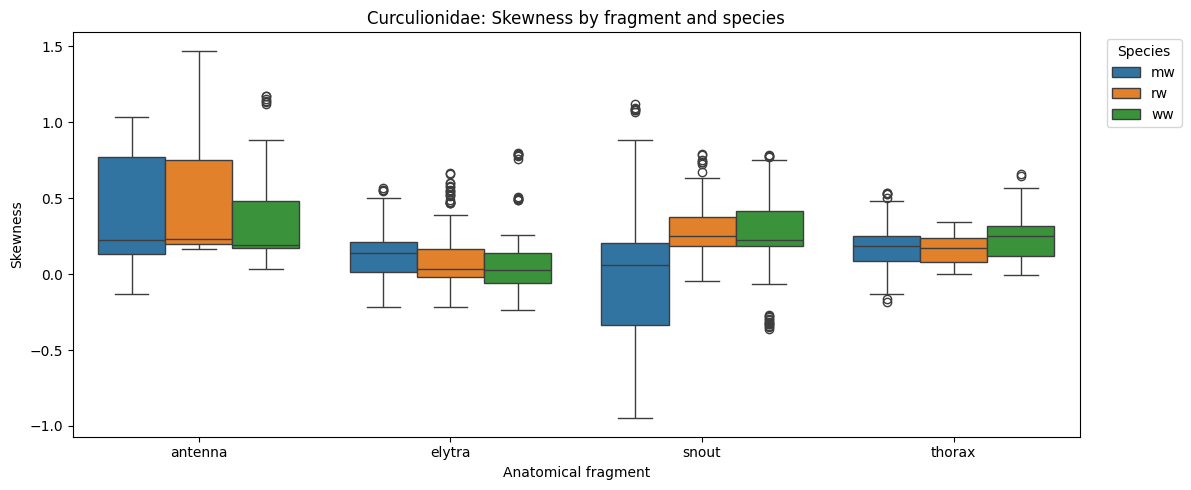

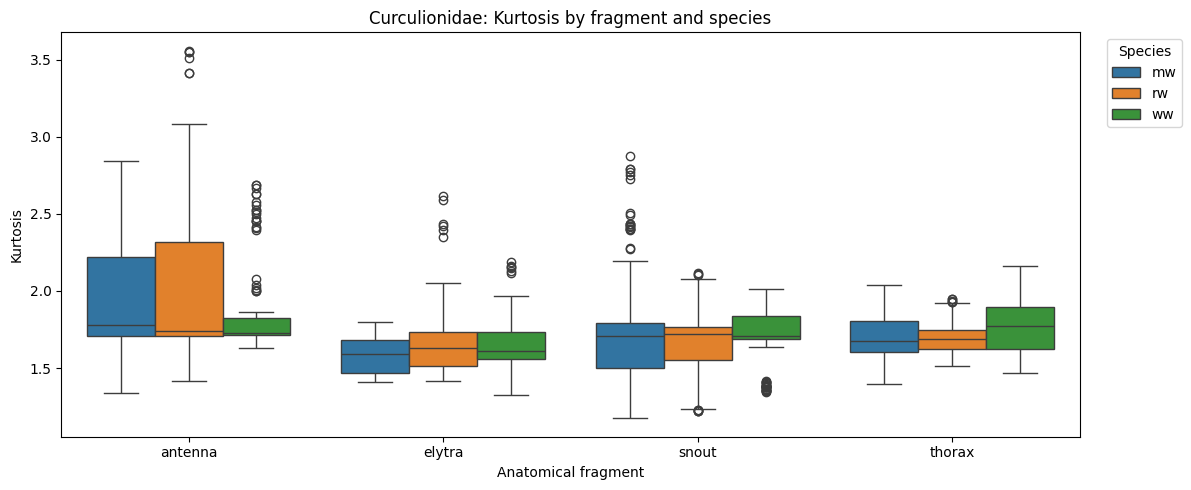

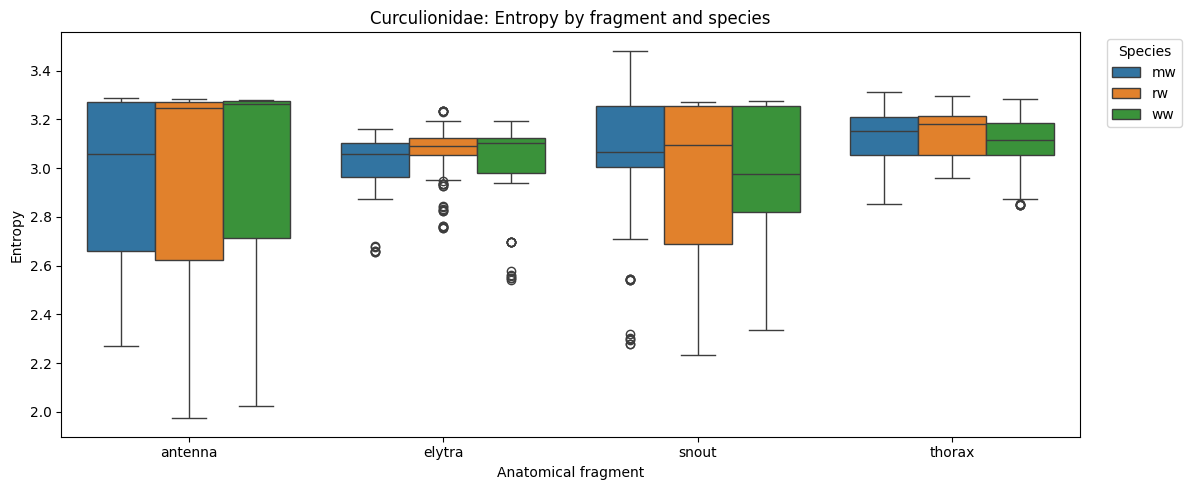

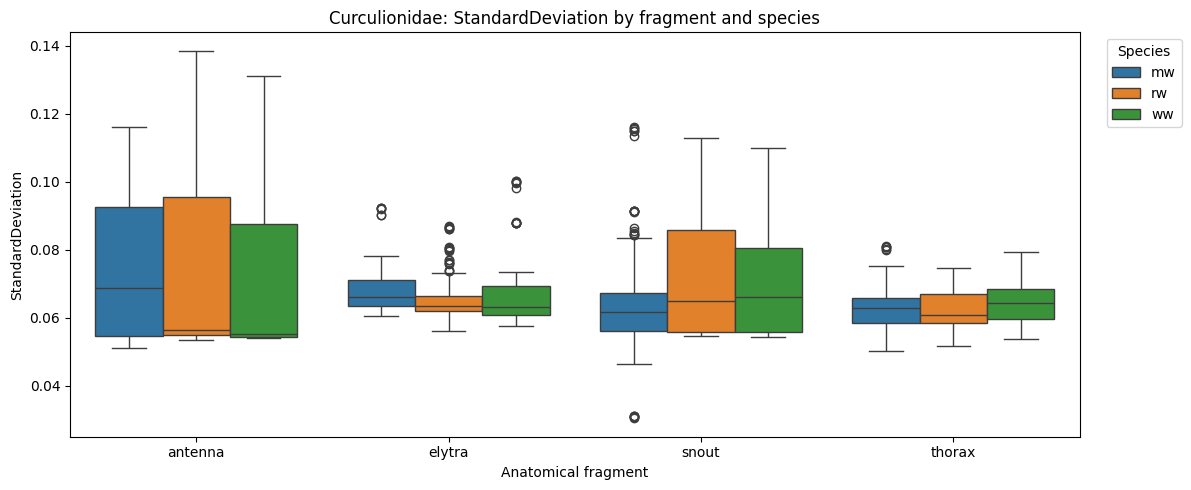

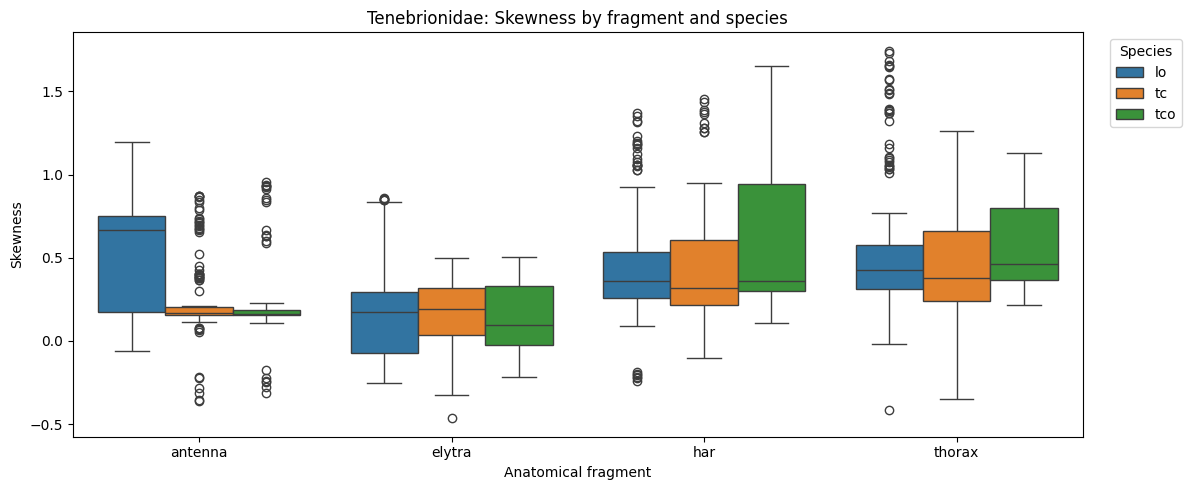

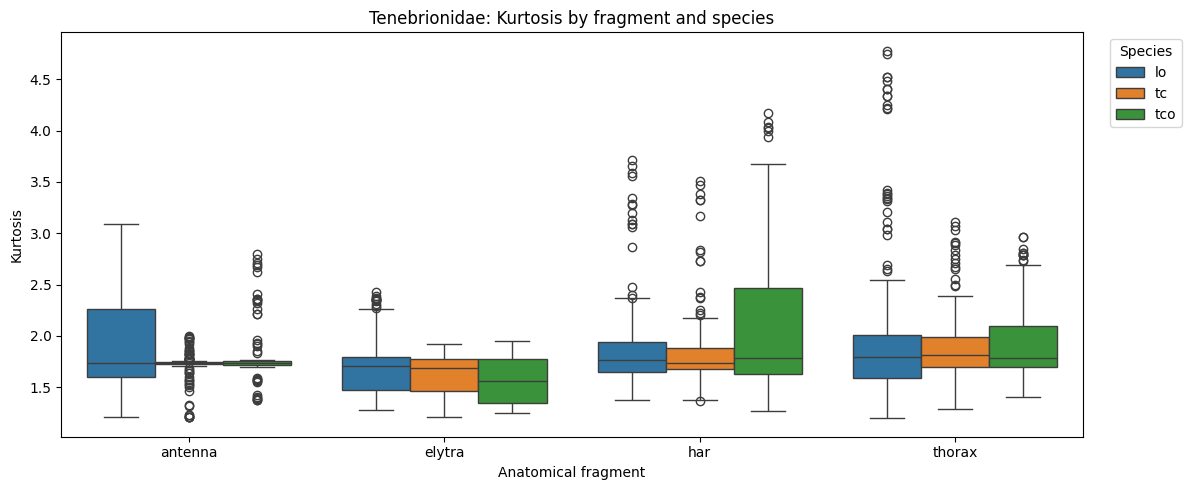

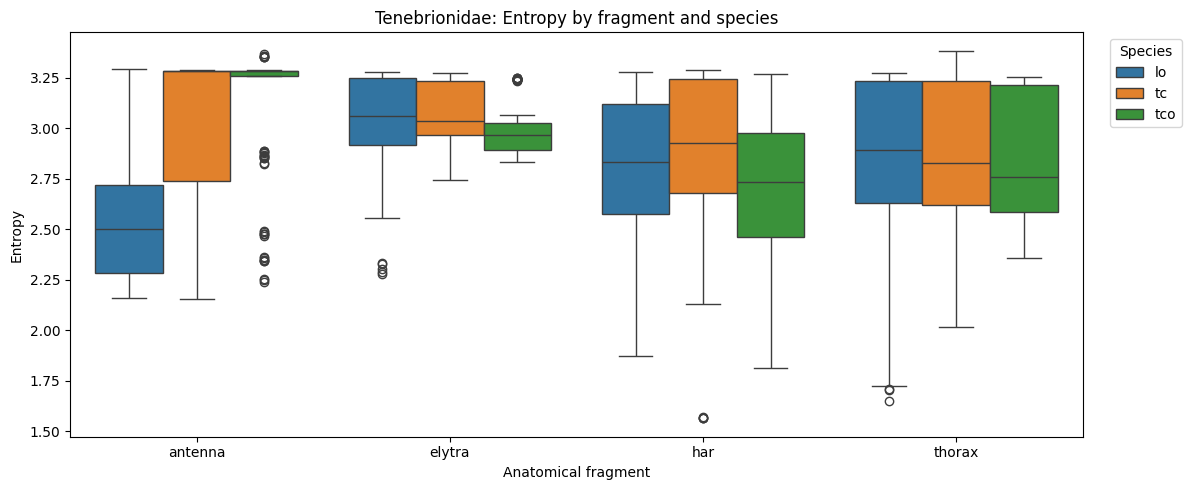

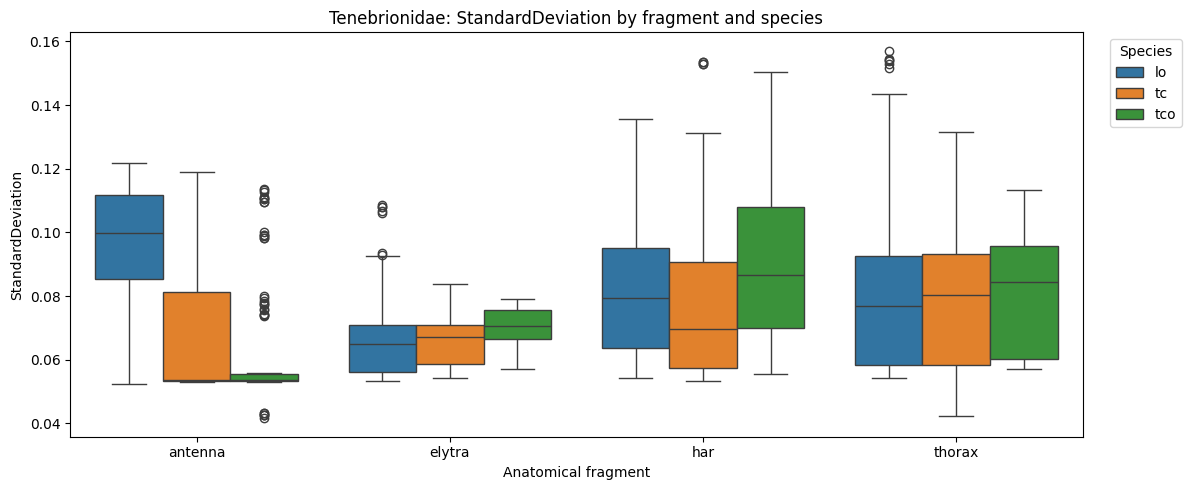

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

FEATURES = [
    "Skewness", "Kurtosis", "Entropy", "StandardDeviation"
]

def plot_feature_distributions(df, family):
    for feature in FEATURES:
        plt.figure(figsize=(12, 5))
        sns.boxplot(
            data=df,
            x="Fragment",
            y=feature,
            hue="Species",
            showfliers=True
        )
        plt.title(f"{family}: {feature} by fragment and species")
        plt.xlabel("Anatomical fragment")
        plt.ylabel(feature)
        plt.legend(title="Species", bbox_to_anchor=(1.02, 1),
                   loc="upper left")
        plt.tight_layout()
        plt.show()

plot_feature_distributions(cur, "Curculionidae")
plot_feature_distributions(ten, "Tenebrionidae")


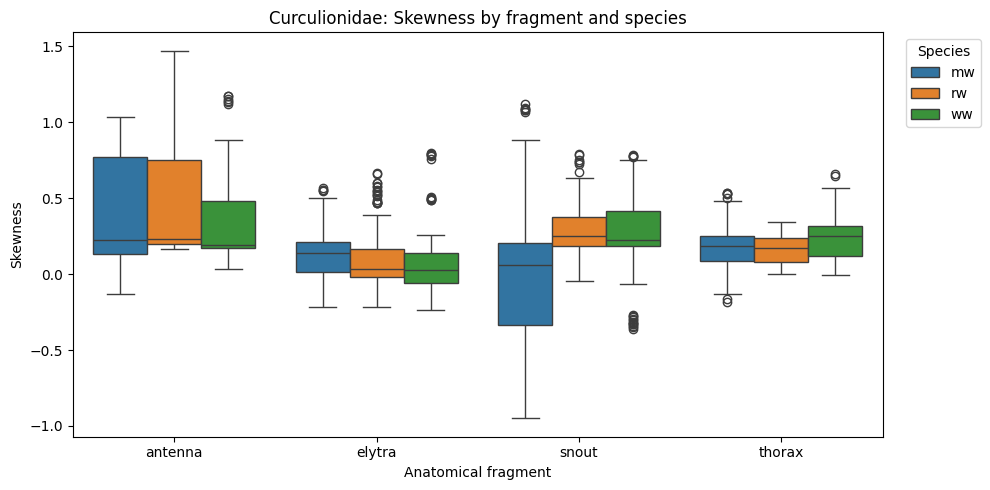

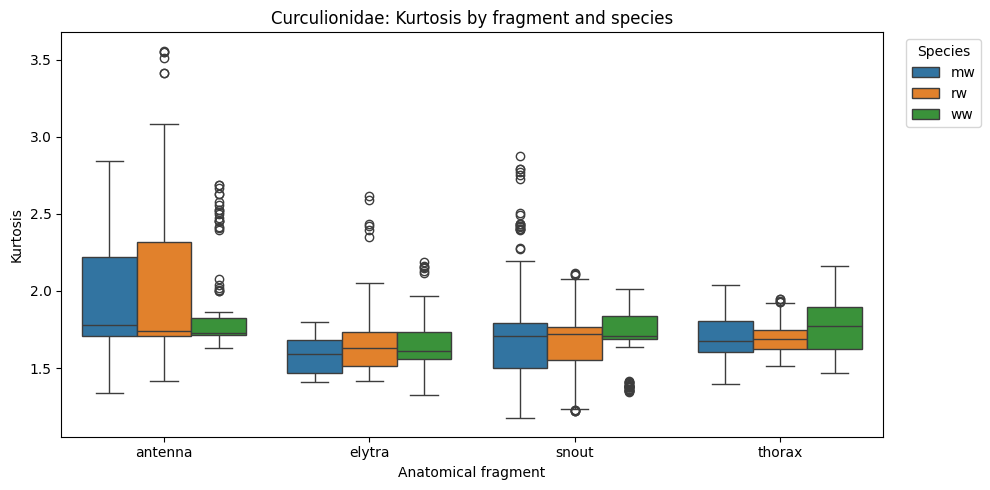

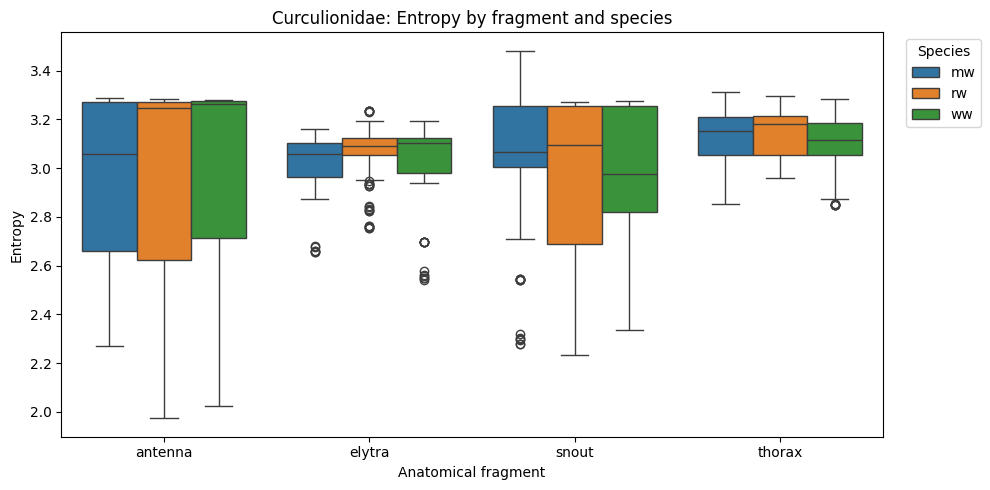

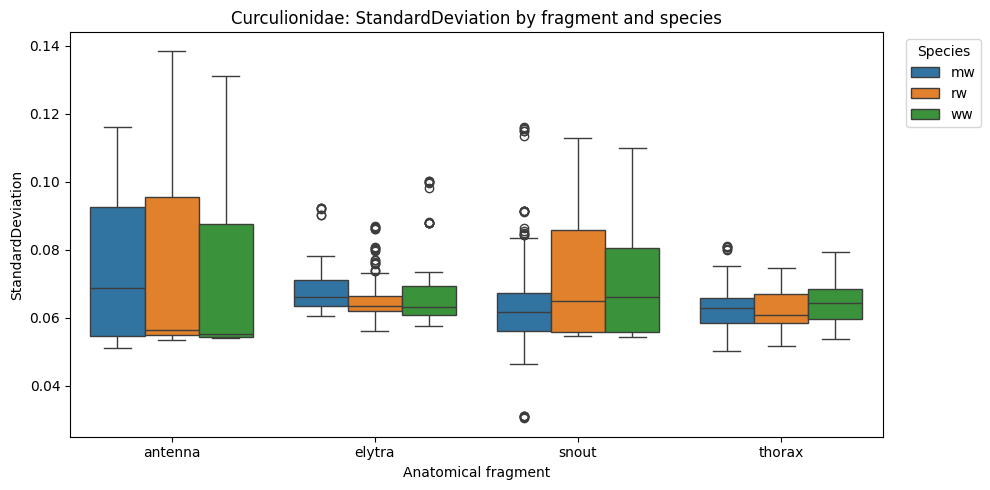

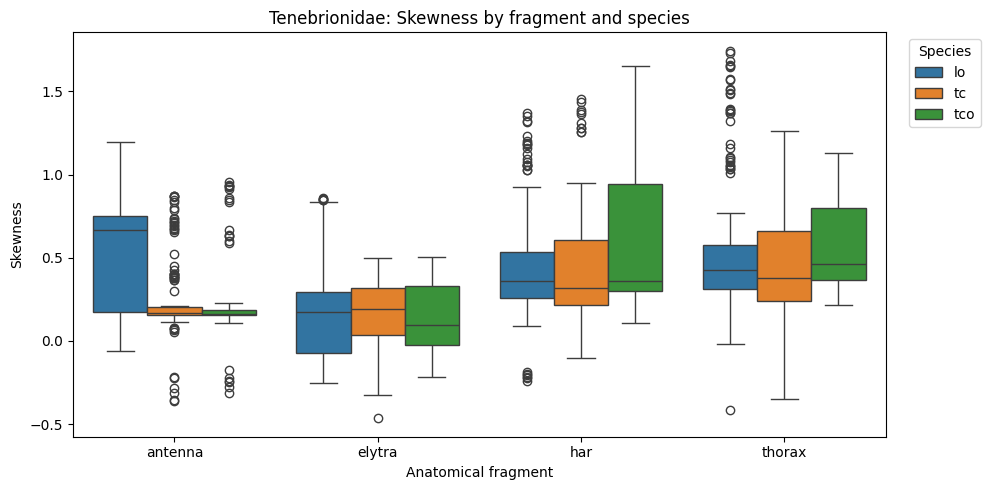

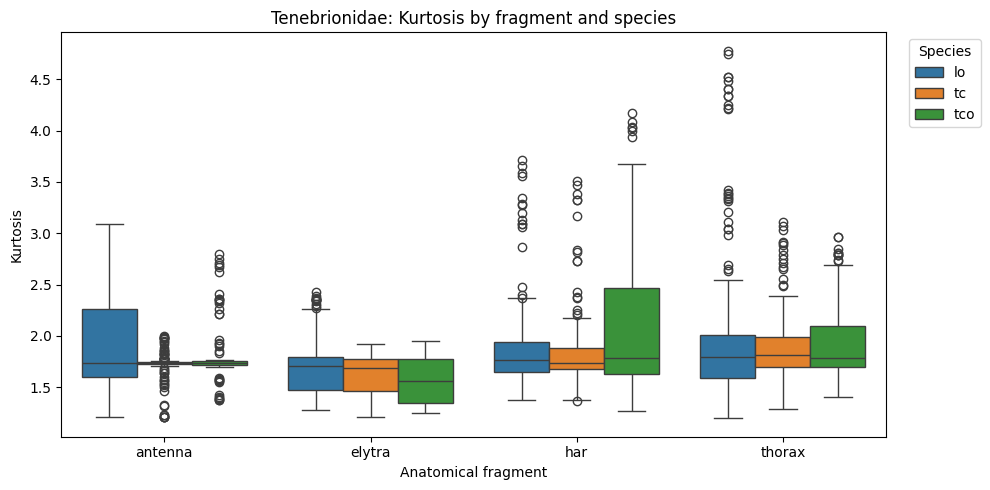

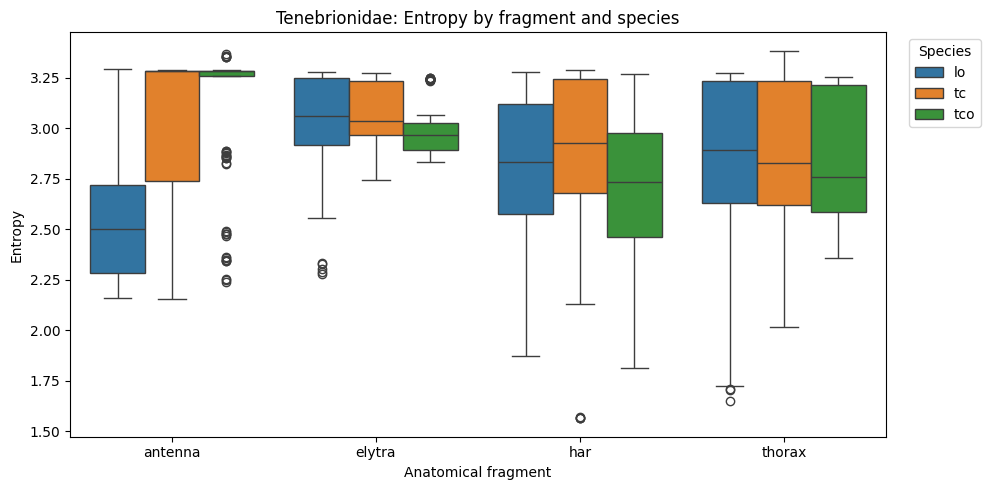

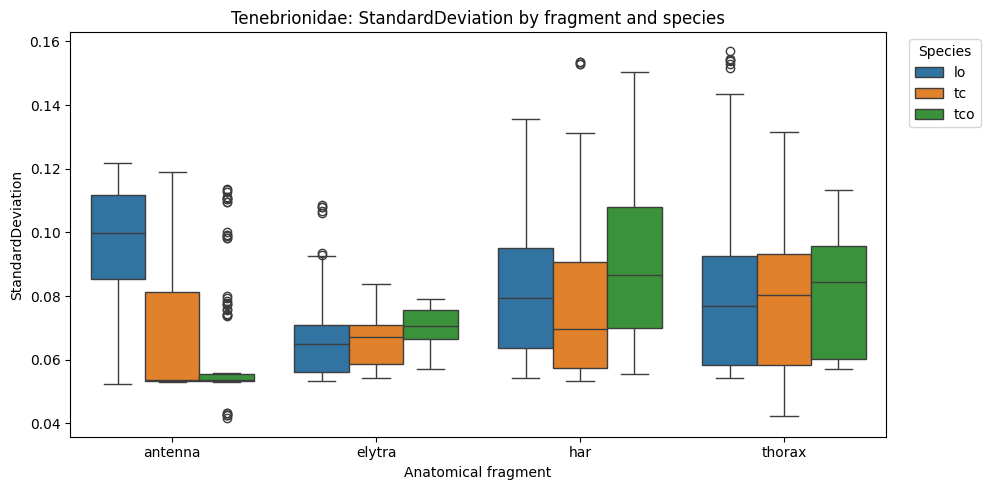

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

FEATURES = [
    "Skewness",
    "Kurtosis",
    "Entropy",
    "StandardDeviation"
]

def plot_feature_distributions(df, family):
    for feature in FEATURES:
        plt.figure(figsize=(10, 5))
        sns.boxplot(
            data=df,
            x="Fragment",
            y=feature,
            hue="Species",
            showfliers=True
        )
        plt.title(f"{family}: {feature} by fragment and species")
        plt.xlabel("Anatomical fragment")
        plt.ylabel(feature)
        plt.legend(title="Species", bbox_to_anchor=(1.02, 1),
                   loc="upper left")
        plt.tight_layout()
        plt.show()

plot_feature_distributions(cur, "Curculionidae")
plot_feature_distributions(ten, "Tenebrionidae")

In [ ]:

import pandas as pd
import numpy as np

FEATURES = [
    "Skewness",
    "Kurtosis",
    "Entropy",
    "StandardDeviation"
]

def summarise_features(df, family):
    print(f"\n{'='*65}")
    print(f"{family.upper()} — FEATURE DISTRIBUTION SUMMARY")
    print(f"{'='*65}")

    for feature in FEATURES:
        summary = (
            df.groupby(["Fragment", "Species"])[feature]
            .agg(["count", "median", "std", "min", "max"])
            .round(4)
        )

        print(f"\n--- {feature} ---")
        print(summary.to_string())

    # Variation in each feature across species within each fragment
    print("\n--- Largest within-fragment species differences ---")
    for fragment, group in df.groupby("Fragment"):
        differences = {}
        for feature in FEATURES:
            means = group.groupby("Species")[feature].mean()
            differences[feature] = means.max() - means.min()

        largest = max(differences, key=differences.get)
        print(
            f"{fragment}: {largest} has the largest "
            f"difference between species means "
            f"({differences[largest]:.4f})"
        )

summarise_features(cur, "Curculionidae")
summarise_features(ten, "Tenebrionidae")



CURCULIONIDAE — FEATURE DISTRIBUTION SUMMARY

--- Skewness ---
                  count  median     std     min     max
Fragment Species                                       
antenna  mw         144  0.2240  0.3773 -0.1280  1.0382
         rw         138  0.2340  0.3993  0.1686  1.4721
         ww         114  0.1929  0.2957  0.0310  1.1752
elytra   mw         108  0.1395  0.1654 -0.2162  0.5700
         rw         144  0.0314  0.2121 -0.2138  0.6695
         ww          89  0.0255  0.2479 -0.2362  0.7992
snout    mw         192  0.0617  0.4130 -0.9496  1.1182
         rw         150  0.2535  0.1649 -0.0444  0.7904
         ww         114  0.2270  0.2778 -0.3578  0.7876
thorax   mw         138  0.1888  0.1524 -0.1809  0.5331
         rw         108  0.1742  0.0917  0.0037  0.3464
         ww         114  0.2540  0.1377 -0.0077  0.6617

--- Kurtosis ---
                  count  median     std     min     max
Fragment Species                                       
antenna  mw         14

In [ ]:

import numpy as np
import pandas as pd
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests

FEATURES = [
    "Skewness",
    "Kurtosis",
    "Entropy",
    "StandardDeviation"
]

def test_feature_separation(df, family):
    rows = []

    for fragment, frag_df in df.groupby("Fragment"):
        species_groups = list(frag_df.groupby("Species"))

        for feature in FEATURES:
            groups = [
                group[feature].dropna().to_numpy()
                for _, group in species_groups
            ]

            H, p = kruskal(*groups)

            # Approximate Kruskal-Wallis effect size
            n = sum(len(g) for g in groups)
            k = len(groups)
            epsilon_sq = max(0, (H - k + 1) / (n - k))

            rows.append({
                "Family": family,
                "Fragment": fragment,
                "Feature": feature,
                "H_statistic": H,
                "p_value": p,
                "epsilon_squared": epsilon_sq
            })

    results = pd.DataFrame(rows)
    results["p_adjusted_BH"] = multipletests(
        results["p_value"], method="fdr_bh"
    )[1]
    results["FDR_significant"] = results["p_adjusted_BH"] < 0.05

    return results.sort_values(
        ["p_adjusted_BH", "epsilon_squared"]
    )

cur_tests = test_feature_separation(cur, "Curculionidae")
ten_tests = test_feature_separation(ten, "Tenebrionidae")

print("CURCULIONIDAE")
print(cur_tests.round(5).to_string(index=False))

print("\nTENEBRIONIDAE")
print(ten_tests.round(5).to_string(index=False))


CURCULIONIDAE
       Family Fragment           Feature  H_statistic  p_value  epsilon_squared  p_adjusted_BH  FDR_significant
Curculionidae    snout          Skewness     93.53940  0.00000          0.20207        0.00000             True
Curculionidae  antenna          Skewness     17.64465  0.00015          0.03981        0.00093             True
Curculionidae   thorax          Skewness     17.15074  0.00019          0.04244        0.00093             True
Curculionidae   elytra StandardDeviation     16.73148  0.00023          0.04358        0.00093             True
Curculionidae   thorax          Kurtosis     13.19095  0.00137          0.03135        0.00364             True
Curculionidae   elytra           Entropy     13.42588  0.00122          0.03380        0.00364             True
Curculionidae   elytra          Skewness     11.68899  0.00290          0.02867        0.00662             True
Curculionidae   elytra          Kurtosis     10.18937  0.00613          0.02423        0.0

In [ ]:

def audit_identifiers(df, family):
    print(f"\n{family}")

    print("Rows:", len(df))
    print("Unique ImageName values:", df["ImageName"].nunique())

    repeated_names = (
        df.groupby("ImageName")
        .agg(
            row_count=("ImageName", "size"),
            species_count=("Species", "nunique"),
            fragment_count=("Fragment", "nunique")
        )
        .query("row_count > 1")
        .sort_values("row_count", ascending=False)
    )

    print("\nRepeated image names:")
    print(repeated_names.head(15).to_string())

    print("\nRepeated-name groups:", len(repeated_names))
    print(
        "Names shared across species:",
        int((repeated_names["species_count"] > 1).sum())
    )
    print(
        "Names shared across fragments:",
        int((repeated_names["fragment_count"] > 1).sum())
    )

audit_identifiers(cur, "Curculionidae")
audit_identifiers(ten, "Tenebrionidae")



Curculionidae
Rows: 1553
Unique ImageName values: 240

Repeated image names:
           row_count  species_count  fragment_count
ImageName                                          
10.jpg            12              3               4
11.jpg            12              3               4
7.jpg             12              3               4
4.jpg             12              3               4
39.jpg            12              3               4
38.jpg            12              3               4
15.jpg            12              3               4
18.jpg            12              3               4
17.jpg            12              3               4
16.jpg            12              3               4
19.jpg            12              3               4
21.jpg            12              3               4
20.jpg            12              3               4
2.jpg             12              3               4
23.jpg            12              3               4

Repeated-name groups: 150
Names share

In [ ]:

def check_full_keys(df, family):
    keys = ["Species", "Fragment", "ImageName"]

    duplicate_mask = df.duplicated(keys, keep=False)
    duplicate_rows = df.loc[duplicate_mask].sort_values(keys)

    print(f"\n{family}")
    print("Total rows:", len(df))
    print("Unique full keys:", df[keys].drop_duplicates().shape[0])
    print("Rows with duplicated full keys:", int(duplicate_mask.sum()))

    if not duplicate_rows.empty:
        print("\nExample duplicated keys:")
        print(duplicate_rows[keys].head(20).to_string(index=False))
    else:
        print("All species-fragment-filename keys are unique.")

check_full_keys(cur, "Curculionidae")
check_full_keys(ten, "Tenebrionidae")



Curculionidae
Total rows: 1553
Unique full keys: 1553
Rows with duplicated full keys: 0
All species-fragment-filename keys are unique.

Tenebrionidae
Total rows: 1812
Unique full keys: 1812
Rows with duplicated full keys: 0
All species-fragment-filename keys are unique.


In [ ]:
print("Curculionidae feature rows:", len(cur))
print("Tenebrionidae feature rows:", len(ten))
print("Combined feature rows:", len(cur) + len(ten))

print("\nCurculionidae species counts:")
print(cur["Species"].value_counts().sort_index())

print("\nTenebrionidae species counts:")
print(ten["Species"].value_counts().sort_index())

print("\nCurculionidae fragment counts:")
print(cur["Fragment"].value_counts().sort_index())

print("\nTenebrionidae fragment counts:")
print(ten["Fragment"].value_counts().sort_index())

Curculionidae feature rows: 1553
Tenebrionidae feature rows: 1812
Combined feature rows: 3365

Curculionidae species counts:
Species
mw    582
rw    540
ww    431
Name: count, dtype: int64

Tenebrionidae species counts:
Species
lo     720
tc     642
tco    450
Name: count, dtype: int64

Curculionidae fragment counts:
Fragment
antenna    396
elytra     341
snout      456
thorax     360
Name: count, dtype: int64

Tenebrionidae fragment counts:
Fragment
antenna    450
elytra     432
har        474
thorax     456
Name: count, dtype: int64


In [ ]:
import numpy as np
import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

features = [
    "Skewness",
    "Kurtosis",
    "Entropy",
    "StandardDeviation"
]

def test_dummy_baselines(df, family):
    print(f"\n{family}")

    for held_out in sorted(df["Fragment"].unique()):
        train = df[df["Fragment"] != held_out]
        test = df[df["Fragment"] == held_out]

        X_train = train[features]
        y_train = train["Species"]
        X_test = test[features]
        y_test = test["Species"]

        for strategy in ["most_frequent", "prior", "stratified"]:
            model = DummyClassifier(
                strategy=strategy,
                random_state=42
            )
            model.fit(X_train, y_train)
            pred = model.predict(X_test)

            print(
                held_out,
                strategy,
                "accuracy =", round(
                    accuracy_score(y_test, pred), 3
                ),
                "balanced accuracy =", round(
                    balanced_accuracy_score(y_test, pred), 3
                ),
                "macro-F1 =", round(
                    f1_score(
                        y_test, pred,
                        average="macro",
                        zero_division=0
                    ), 3
                )
            )

test_dummy_baselines(cur, "Curculionidae")
test_dummy_baselines(ten, "Tenebrionidae")


Curculionidae
antenna most_frequent accuracy = 0.364 balanced accuracy = 0.333 macro-F1 = 0.178
antenna prior accuracy = 0.364 balanced accuracy = 0.333 macro-F1 = 0.178
antenna stratified accuracy = 0.336 balanced accuracy = 0.33 macro-F1 = 0.33
elytra most_frequent accuracy = 0.317 balanced accuracy = 0.333 macro-F1 = 0.16
elytra prior accuracy = 0.317 balanced accuracy = 0.333 macro-F1 = 0.16
elytra stratified accuracy = 0.334 balanced accuracy = 0.336 macro-F1 = 0.333
snout most_frequent accuracy = 0.421 balanced accuracy = 0.333 macro-F1 = 0.198
snout prior accuracy = 0.421 balanced accuracy = 0.333 macro-F1 = 0.198
snout stratified accuracy = 0.307 balanced accuracy = 0.294 macro-F1 = 0.295
thorax most_frequent accuracy = 0.383 balanced accuracy = 0.333 macro-F1 = 0.185
thorax prior accuracy = 0.383 balanced accuracy = 0.333 macro-F1 = 0.185
thorax stratified accuracy = 0.35 balanced accuracy = 0.346 macro-F1 = 0.346

Tenebrionidae
antenna most_frequent accuracy = 0.36 balanced 

In [ ]:

import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

features = [
    "Skewness",
    "Kurtosis",
    "Entropy",
    "StandardDeviation"
]

all_results = []

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 75)
    print("FAMILY:", family)
    print("Records:", len(df))
    print(
        "Duplicate species-fragment-filename keys:",
        df.duplicated(["Species", "Fragment", "ImageName"]).sum()
    )

    for held_out in sorted(df["Fragment"].unique()):
        train = df[df["Fragment"] != held_out].copy()
        test = df[df["Fragment"] == held_out].copy()

        X_train = train[features]
        y_train = train["Species"]
        X_test = test[features]
        y_test = test["Species"]

        models = {
            "Dummy (most frequent)": DummyClassifier(
                strategy="most_frequent"
            ),
            "SVM (RBF)": make_pipeline(
                StandardScaler(),
                SVC(class_weight="balanced")
            ),
            "Random Forest (300 trees)": RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        }

        for model_name, model in models.items():
            model.fit(X_train, y_train)
            pred = model.predict(X_test)

            all_results.append({
                "Family": family,
                "Held-out fragment": held_out,
                "Model": model_name,
                "Accuracy": accuracy_score(y_test, pred),
                "Balanced accuracy": balanced_accuracy_score(
                    y_test, pred
                ),
                "Macro F1": f1_score(
                    y_test, pred, average="macro", zero_division=0
                )
            })

results_df = pd.DataFrame(all_results)

print("\n\nDETAILED RESULTS")
print(results_df.round(3).to_string(index=False))

print("\n\nMEAN RESULTS ACROSS HELD-OUT FRAGMENTS")
summary_df = (
    results_df.groupby(["Family", "Model"])[
        ["Accuracy", "Balanced accuracy", "Macro F1"]
    ]
    .mean()
    .reset_index()
)
print(summary_df.round(3).to_string(index=False))



FAMILY: Curculionidae
Records: 1553
Duplicate species-fragment-filename keys: 0

FAMILY: Tenebrionidae
Records: 1812
Duplicate species-fragment-filename keys: 0


DETAILED RESULTS
       Family Held-out fragment                     Model  Accuracy  Balanced accuracy  Macro F1
Curculionidae           antenna     Dummy (most frequent)     0.364              0.333     0.178
Curculionidae           antenna                 SVM (RBF)     0.402              0.392     0.380
Curculionidae           antenna Random Forest (300 trees)     0.308              0.302     0.302
Curculionidae            elytra     Dummy (most frequent)     0.317              0.333     0.160
Curculionidae            elytra                 SVM (RBF)     0.249              0.263     0.230
Curculionidae            elytra Random Forest (300 trees)     0.328              0.328     0.326
Curculionidae             snout     Dummy (most frequent)     0.421              0.333     0.198
Curculionidae             snout            


Family: Curculionidae | Held-out fragment: antenna
              precision    recall  f1-score   support

          mw       0.46      0.35      0.40       144
          rw       0.40      0.61      0.48       138
          ww       0.32      0.22      0.26       114

    accuracy                           0.40       396
   macro avg       0.40      0.39      0.38       396
weighted avg       0.40      0.40      0.39       396



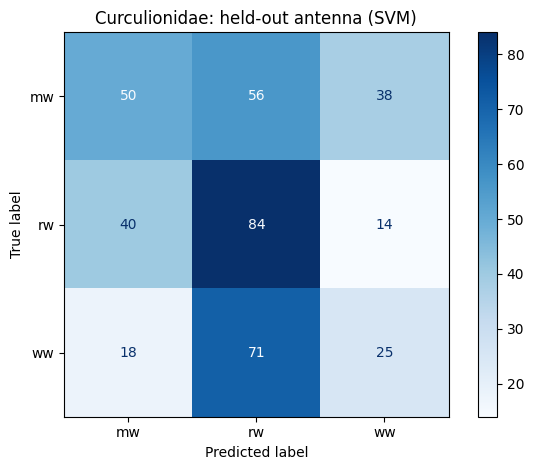


Family: Curculionidae | Held-out fragment: elytra
              precision    recall  f1-score   support

          mw       0.25      0.49      0.33       108
          rw       0.30      0.10      0.15       144
          ww       0.23      0.20      0.21        89

    accuracy                           0.25       341
   macro avg       0.26      0.26      0.23       341
weighted avg       0.27      0.25      0.22       341



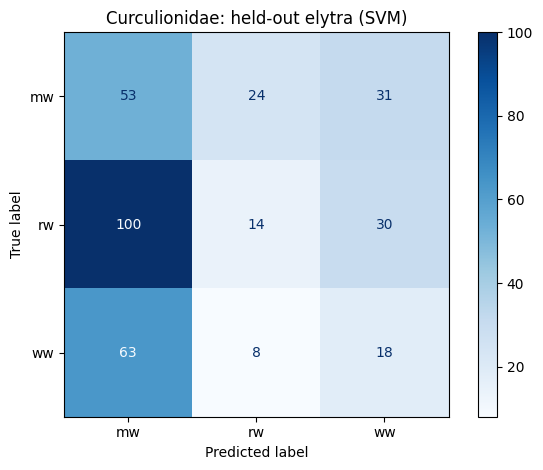


Family: Curculionidae | Held-out fragment: snout
              precision    recall  f1-score   support

          mw       0.54      0.34      0.42       192
          rw       0.42      0.66      0.52       150
          ww       0.33      0.30      0.31       114

    accuracy                           0.43       456
   macro avg       0.43      0.43      0.42       456
weighted avg       0.45      0.43      0.42       456



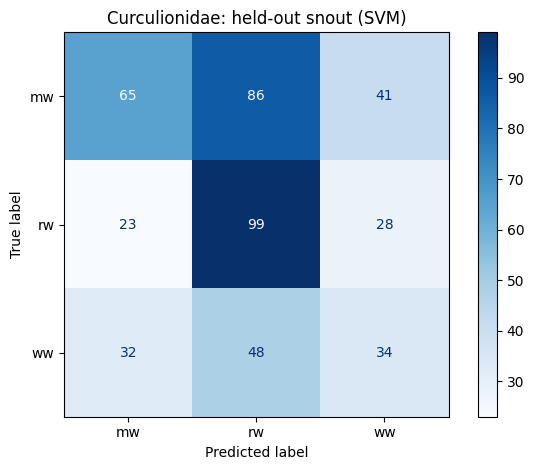


Family: Curculionidae | Held-out fragment: thorax
              precision    recall  f1-score   support

          mw       0.33      0.22      0.26       138
          rw       0.30      0.65      0.41       108
          ww       0.05      0.02      0.03       114

    accuracy                           0.28       360
   macro avg       0.23      0.29      0.23       360
weighted avg       0.23      0.28      0.23       360



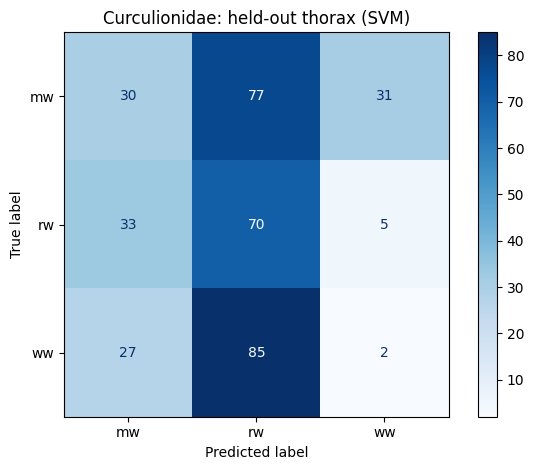


Family: Tenebrionidae | Held-out fragment: antenna
              precision    recall  f1-score   support

          lo       0.72      0.39      0.50       162
          tc       0.45      0.77      0.57       168
         tco       0.23      0.15      0.18       120

    accuracy                           0.47       450
   macro avg       0.47      0.44      0.42       450
weighted avg       0.49      0.47      0.44       450



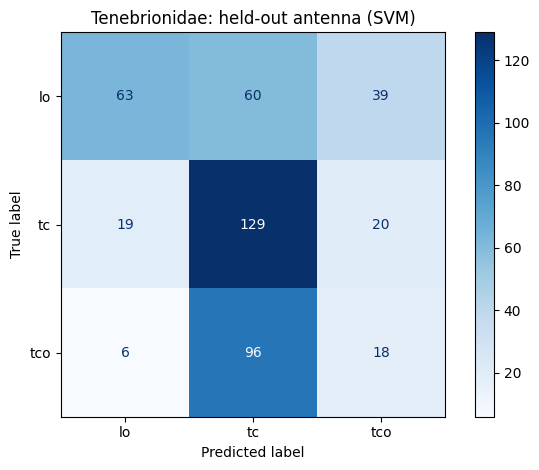


Family: Tenebrionidae | Held-out fragment: elytra
              precision    recall  f1-score   support

          lo       0.36      0.20      0.25       168
          tc       0.30      0.59      0.39       150
         tco       0.15      0.05      0.08       114

    accuracy                           0.30       432
   macro avg       0.27      0.28      0.24       432
weighted avg       0.28      0.30      0.26       432



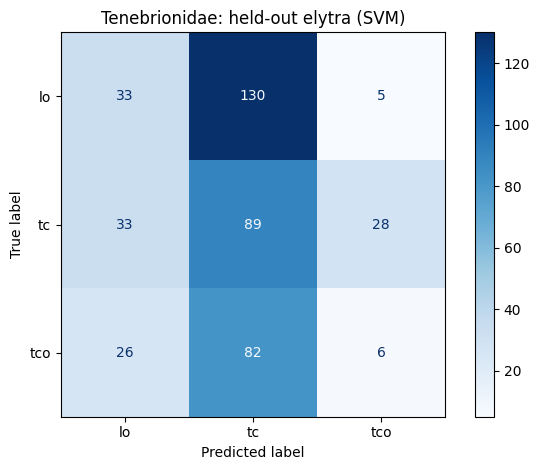


Family: Tenebrionidae | Held-out fragment: har
              precision    recall  f1-score   support

          lo       0.47      0.40      0.43       210
          tc       0.54      0.51      0.52       162
         tco       0.23      0.32      0.27       102

    accuracy                           0.42       474
   macro avg       0.41      0.41      0.41       474
weighted avg       0.44      0.42      0.43       474



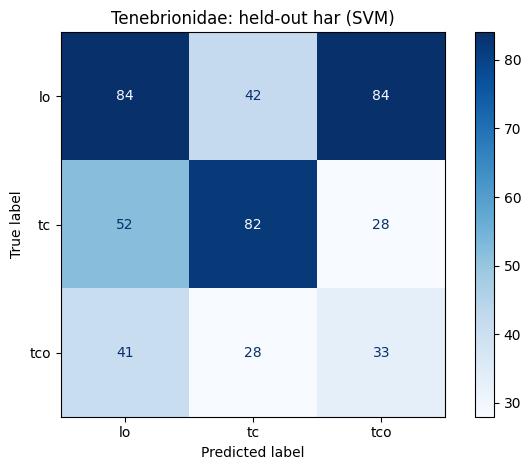


Family: Tenebrionidae | Held-out fragment: thorax
              precision    recall  f1-score   support

          lo       0.38      0.46      0.42       180
          tc       0.37      0.36      0.37       162
         tco       0.20      0.13      0.16       114

    accuracy                           0.34       456
   macro avg       0.31      0.32      0.31       456
weighted avg       0.33      0.34      0.33       456



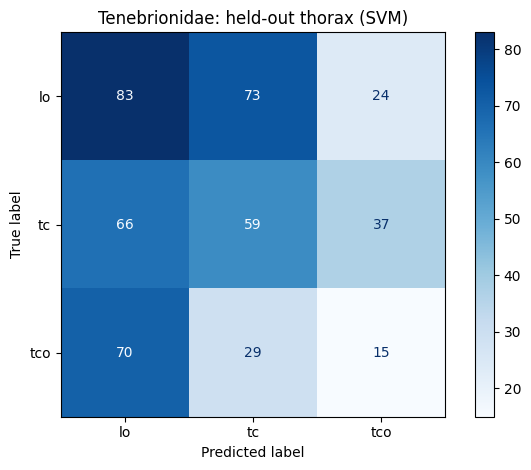

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

features = ["Skewness", "Kurtosis", "Entropy", "StandardDeviation"]

for family, url in urls.items():
    df = pd.read_csv(url)

    for held_out in sorted(df["Fragment"].unique()):
        train = df[df["Fragment"] != held_out]
        test = df[df["Fragment"] == held_out]

        X_train = train[features]
        y_train = train["Species"]
        X_test = test[features]
        y_test = test["Species"]

        model = make_pipeline(
            StandardScaler(),
            SVC(class_weight="balanced")
        )
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

        print("\n" + "=" * 65)
        print(f"Family: {family} | Held-out fragment: {held_out}")
        print(classification_report(
            y_test, pred, zero_division=0
        ))

        ConfusionMatrixDisplay.from_predictions(
            y_test,
            pred,
            labels=sorted(df["Species"].unique()),
            display_labels=sorted(df["Species"].unique()),
            cmap="Blues",
            values_format="d"
        )
        plt.title(f"{family}: held-out {held_out} (SVM)")
        plt.tight_layout()
        plt.show()


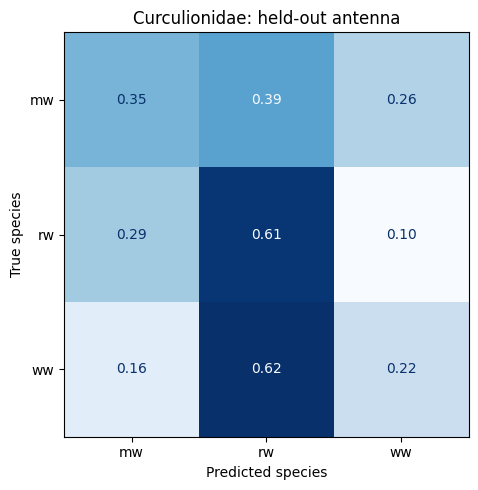

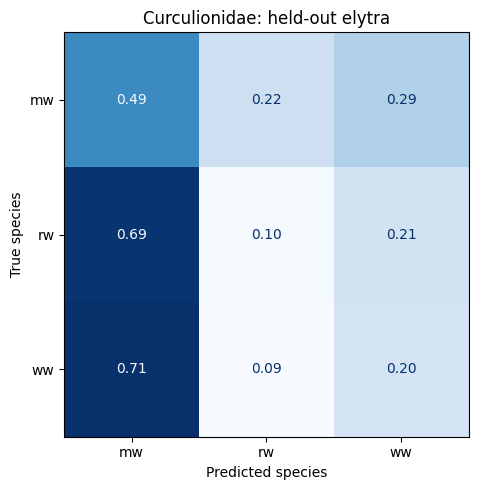

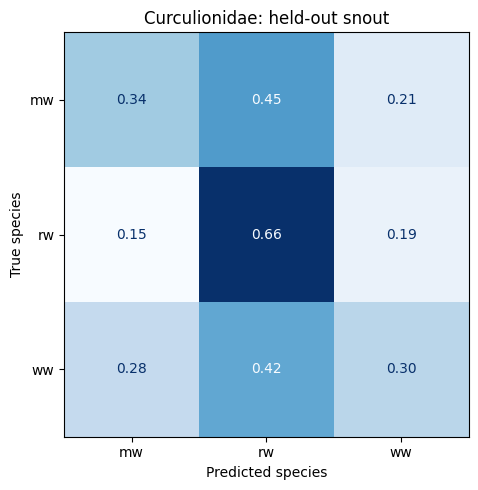

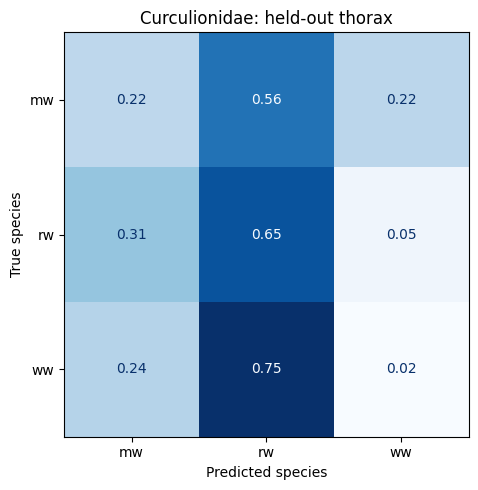

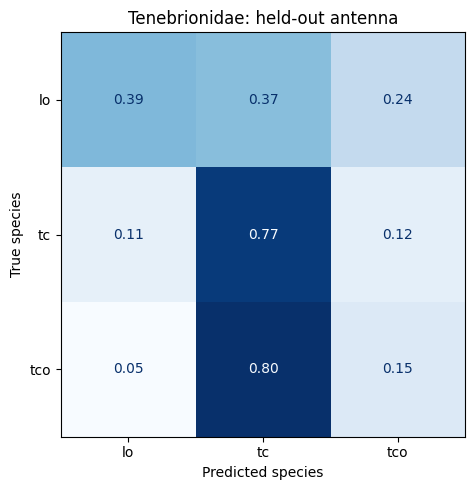

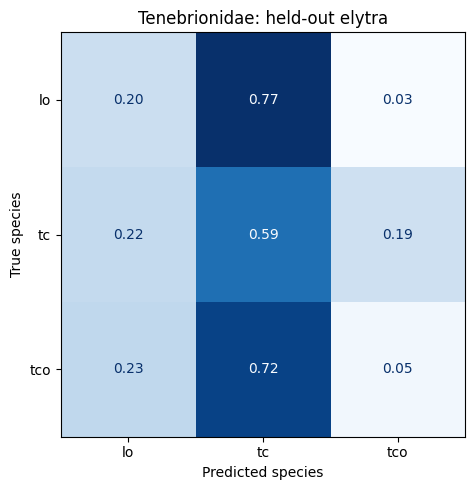

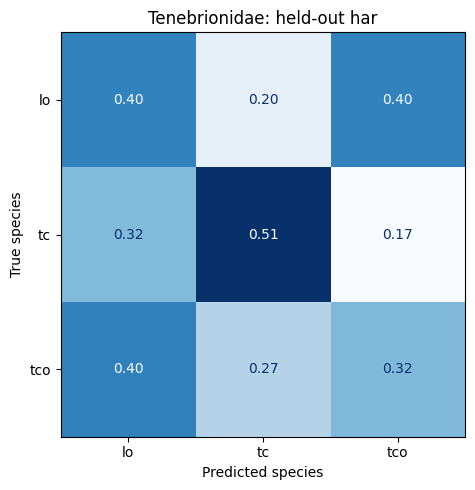

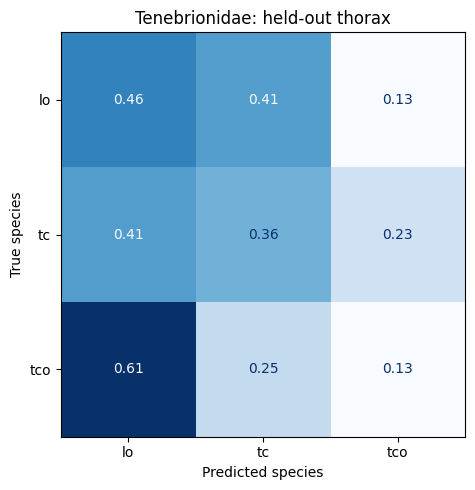

Figures saved in: normalised_confusion_matrices
ZIP file created: normalised_confusion_matrices.zip


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

features = ["Skewness", "Kurtosis", "Entropy", "StandardDeviation"]
output_dir = "normalised_confusion_matrices"
os.makedirs(output_dir, exist_ok=True)

for family, url in urls.items():
    df = pd.read_csv(url)
    species_order = sorted(df["Species"].unique())

    for held_out in sorted(df["Fragment"].unique()):
        train = df[df["Fragment"] != held_out]
        test = df[df["Fragment"] == held_out]

        model = make_pipeline(
            StandardScaler(),
            SVC(class_weight="balanced")
        )
        model.fit(train[features], train["Species"])
        pred = model.predict(test[features])

        cm = confusion_matrix(
            test["Species"],
            pred,
            labels=species_order,
            normalize="true"
        )

        fig, ax = plt.subplots(figsize=(6, 5))
        display = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=species_order
        )
        display.plot(
            ax=ax,
            cmap="Blues",
            values_format=".2f",
            colorbar=False
        )

        ax.set_title(f"{family}: held-out {held_out}")
        ax.set_xlabel("Predicted species")
        ax.set_ylabel("True species")
        plt.tight_layout()

        filename = f"{family}_{held_out}_normalised_cm.png"
        fig.savefig(
            os.path.join(output_dir, filename),
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

print(f"Figures saved in: {output_dir}")

# Package all eight figures into one ZIP file
import shutil
shutil.make_archive(output_dir, "zip", output_dir)
print(f"ZIP file created: {output_dir}.zip")


In [ ]:
from google.colab import files
files.download("normalised_confusion_matrices.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

features = ["Skewness", "Kurtosis", "Entropy", "StandardDeviation"]

for family, url in urls.items():
    df = pd.read_csv(url)
    print("\n", "=" * 50, "\n", family)

    for held_out in sorted(df["Fragment"].unique()):
        train = df[df["Fragment"] != held_out]
        test = df[df["Fragment"] == held_out]

        model = make_pipeline(
            StandardScaler(),
            SVC(class_weight="balanced")
        )
        model.fit(train[features], train["Species"])
        pred = model.predict(test[features])

        labels = sorted(df["Species"].unique())
        cm = confusion_matrix(
            test["Species"], pred,
            labels=labels, normalize="true"
        )

        print(f"\nHeld-out fragment: {held_out}")
        print(pd.DataFrame(
            cm, index=labels, columns=labels
        ).round(2))



 Curculionidae

Held-out fragment: antenna
      mw    rw    ww
mw  0.35  0.39  0.26
rw  0.29  0.61  0.10
ww  0.16  0.62  0.22

Held-out fragment: elytra
      mw    rw    ww
mw  0.49  0.22  0.29
rw  0.69  0.10  0.21
ww  0.71  0.09  0.20

Held-out fragment: snout
      mw    rw    ww
mw  0.34  0.45  0.21
rw  0.15  0.66  0.19
ww  0.28  0.42  0.30

Held-out fragment: thorax
      mw    rw    ww
mw  0.22  0.56  0.22
rw  0.31  0.65  0.05
ww  0.24  0.75  0.02

 Tenebrionidae

Held-out fragment: antenna
       lo    tc   tco
lo   0.39  0.37  0.24
tc   0.11  0.77  0.12
tco  0.05  0.80  0.15

Held-out fragment: elytra
       lo    tc   tco
lo   0.20  0.77  0.03
tc   0.22  0.59  0.19
tco  0.23  0.72  0.05

Held-out fragment: har
       lo    tc   tco
lo   0.40  0.20  0.40
tc   0.32  0.51  0.17
tco  0.40  0.27  0.32

Held-out fragment: thorax
       lo    tc   tco
lo   0.46  0.41  0.13
tc   0.41  0.36  0.23
tco  0.61  0.25  0.13


In [ ]:

import pandas as pd
import numpy as np
from scipy.stats import t
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score
)

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}
features = ["Skewness", "Kurtosis", "Entropy", "StandardDeviation"]

all_results = []

for family, url in urls.items():
    df = pd.read_csv(url)
    print("\n" + "=" * 75)
    print("FAMILY:", family)
    print("Rows:", len(df))
    print("Species:", sorted(df["Species"].unique()))
    print("Fragment categories:", sorted(df["Fragment"].unique()))

    for held_out in sorted(df["Fragment"].unique()):
        train = df[df["Fragment"] != held_out].copy()
        test = df[df["Fragment"] == held_out].copy()

        models = {
            "Dummy": DummyClassifier(strategy="most_frequent"),
            "SVM": make_pipeline(
                StandardScaler(),
                SVC(class_weight="balanced")
            ),
            "Random Forest": RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42
            )
        }

        for name, model in models.items():
            model.fit(train[features], train["Species"])
            pred = model.predict(test[features])

            row = {
                "Family": family,
                "Held-out fragment": held_out,
                "Model": name,
                "N test": len(test),
                "Accuracy": accuracy_score(test["Species"], pred),
                "Balanced accuracy": balanced_accuracy_score(
                    test["Species"], pred
                ),
                "Macro-F1": f1_score(
                    test["Species"], pred, average="macro",
                    zero_division=0
                )
            }
            all_results.append(row)

results = pd.DataFrame(all_results)

print("\n\nPER-FRAGMENT RESULTS")
print(results.round(4).to_string(index=False))

summary = []
for (family, model), group in results.groupby(
    ["Family", "Model"], sort=True
):
    for metric in ["Accuracy", "Balanced accuracy", "Macro-F1"]:
        values = group[metric].to_numpy()
        n = len(values)
        mean = values.mean()
        sd = values.std(ddof=1)
        margin = t.ppf(0.975, n - 1) * sd / np.sqrt(n)

        summary.append({
            "Family": family,
            "Model": model,
            "Metric": metric,
            "Mean": mean,
            "SD": sd,
            "CI lower": mean - margin,
            "CI upper": mean + margin,
            "Number of fragments": n
        })

summary = pd.DataFrame(summary)

print("\n\nSUMMARY: MEAN, SD AND EXPLORATORY 95% CI")
print(summary.round(4).to_string(index=False))

results.to_csv("verified_per_fragment_results.csv", index=False)
summary.to_csv("verified_summary_results.csv", index=False)

print("\nSaved both verified tables as CSV files.")



FAMILY: Curculionidae
Rows: 1553
Species: ['mw', 'rw', 'ww']
Fragment categories: ['antenna', 'elytra', 'snout', 'thorax']

FAMILY: Tenebrionidae
Rows: 1812
Species: ['lo', 'tc', 'tco']
Fragment categories: ['antenna', 'elytra', 'har', 'thorax']


PER-FRAGMENT RESULTS
       Family Held-out fragment         Model  N test  Accuracy  Balanced accuracy  Macro-F1
Curculionidae           antenna         Dummy     396    0.3636             0.3333    0.1778
Curculionidae           antenna           SVM     396    0.4015             0.3917    0.3800
Curculionidae           antenna Random Forest     396    0.3081             0.3023    0.3021
Curculionidae            elytra         Dummy     341    0.3167             0.3333    0.1604
Curculionidae            elytra           SVM     341    0.2493             0.2634    0.2296
Curculionidae            elytra Random Forest     341    0.3284             0.3282    0.3259
Curculionidae             snout         Dummy     456    0.4211             0.3

In [ ]:

import os
import glob
import pandas as pd

csv_files = glob.glob("*.csv")

print("CSV files found:", csv_files)

for file in csv_files:
    print("\n" + "=" * 60)
    print("FILE:", file)
    df = pd.read_csv(file)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(5).to_string(index=False))


CSV files found: ['tenebrionidae_signature_metrics.csv', 'verified_per_fragment_results.csv', 'verified_summary_results.csv', 'curculionidae_signature_metrics.csv']

FILE: tenebrionidae_signature_metrics.csv
Shape: (1812, 7)
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']
ImageName  Skewness  Kurtosis  Entropy  StandardDeviation Species Fragment
    1.jpg  0.511828  1.449691 2.373752           0.103700      lo  antenna
    2.jpg  0.261486  1.468518 2.653571           0.087080      lo  antenna
    3.jpg  0.166969  1.318187 2.677977           0.085028      lo  antenna
    4.jpg  0.261625  1.461871 2.651454           0.087202      lo  antenna
    5.jpg  0.160233  1.280853 2.668759           0.085490      lo  antenna

FILE: verified_per_fragment_results.csv
Shape: (24, 7)
Columns: ['Family', 'Held-out fragment', 'Model', 'N test', 'Accuracy', 'Balanced accuracy', 'Macro-F1']
       Family Held-out fragment         Model  N test  Accurac

In [ ]:

import os

print("Current directory:", os.getcwd())
print("\nFiles and folders here:")
print(os.listdir())


Current directory: /content

Files and folders here:
['.config', '29066444.zip', 'tenebrionidae_signature_metrics.csv', 'rerun_validation.py', 'verified_per_fragment_results.csv', 'normalised_confusion_matrices.zip', 'drive', '29066444 (1).zip', 'verified_summary_results.csv', 'validation_outputs', 'normalised_confusion_matrices', 'curculionidae_signature_metrics.csv', 'sample_data']


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.lower().endswith('.csv'):
            print(os.path.join(root, file))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

import os

count = 0

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.lower().endswith(('.csv', '.ipynb', '.xlsx', '.pkl', '.joblib')):
            print(os.path.join(root, file))
            count += 1

print(f"\nTotal matching files: {count}")


/content/drive/MyDrive/Colab Notebooks/Beetle_Fragment_Classification_Machine_Learning.ipynb
/content/drive/MyDrive/Colab Notebooks/Sitophilus_Cyt_b5_r_Analysis.ipynb
/content/drive/MyDrive/Colab Notebooks/Sitophilus_oryzae_DLD_Analysis.ipynb
/content/drive/MyDrive/Classroom/ECK Tour Course COM 311 Agro-Informatics Batch A & B/SUDALAIYANDI.Y 2020030073.xlsx

Total matching files: 4


In [ ]:

import pandas as pd
import numpy as np
from scipy.stats import t
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score
)

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}
features = ["Skewness", "Kurtosis", "Entropy", "StandardDeviation"]

all_results = []

for family, url in urls.items():
    df = pd.read_csv(url)
    print("\n" + "=" * 75)
    print("FAMILY:", family)
    print("Rows:", len(df))
    print("Species:", sorted(df["Species"].unique()))
    print("Fragment categories:", sorted(df["Fragment"].unique()))

    for held_out in sorted(df["Fragment"].unique()):
        train = df[df["Fragment"] != held_out].copy()
        test = df[df["Fragment"] == held_out].copy()

        models = {
            "Dummy": DummyClassifier(strategy="most_frequent"),
            "SVM": make_pipeline(
                StandardScaler(),
                SVC(class_weight="balanced")
            ),
            "Random Forest": RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42
            )
        }

        for name, model in models.items():
            model.fit(train[features], train["Species"])
            pred = model.predict(test[features])

            row = {
                "Family": family,
                "Held-out fragment": held_out,
                "Model": name,
                "N test": len(test),
                "Accuracy": accuracy_score(test["Species"], pred),
                "Balanced accuracy": balanced_accuracy_score(
                    test["Species"], pred
                ),
                "Macro-F1": f1_score(
                    test["Species"], pred, average="macro",
                    zero_division=0
                )
            }
            all_results.append(row)

results = pd.DataFrame(all_results)

print("\n\nPER-FRAGMENT RESULTS")
print(results.round(4).to_string(index=False))

summary = []
for (family, model), group in results.groupby(
    ["Family", "Model"], sort=True
):
    for metric in ["Accuracy", "Balanced accuracy", "Macro-F1"]:
        values = group[metric].to_numpy()
        n = len(values)
        mean = values.mean()
        sd = values.std(ddof=1)
        margin = t.ppf(0.975, n - 1) * sd / np.sqrt(n)

        summary.append({
            "Family": family,
            "Model": model,
            "Metric": metric,
            "Mean": mean,
            "SD": sd,
            "CI lower": mean - margin,
            "CI upper": mean + margin,
            "Number of fragments": n
        })

summary = pd.DataFrame(summary)

print("\n\nSUMMARY: MEAN, SD AND EXPLORATORY 95% CI")
print(summary.round(4).to_string(index=False))

results.to_csv("verified_per_fragment_results.csv", index=False)
summary.to_csv("verified_summary_results.csv", index=False)

print("\nSaved both verified tables as CSV files.")



FAMILY: Curculionidae
Rows: 1553
Species: ['mw', 'rw', 'ww']
Fragment categories: ['antenna', 'elytra', 'snout', 'thorax']

FAMILY: Tenebrionidae
Rows: 1812
Species: ['lo', 'tc', 'tco']
Fragment categories: ['antenna', 'elytra', 'har', 'thorax']


PER-FRAGMENT RESULTS
       Family Held-out fragment         Model  N test  Accuracy  Balanced accuracy  Macro-F1
Curculionidae           antenna         Dummy     396    0.3636             0.3333    0.1778
Curculionidae           antenna           SVM     396    0.4015             0.3917    0.3800
Curculionidae           antenna Random Forest     396    0.3081             0.3023    0.3021
Curculionidae            elytra         Dummy     341    0.3167             0.3333    0.1604
Curculionidae            elytra           SVM     341    0.2493             0.2634    0.2296
Curculionidae            elytra Random Forest     341    0.3284             0.3282    0.3259
Curculionidae             snout         Dummy     456    0.4211             0.3

In [ ]:

import pandas as pd

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 65)
    print("FAMILY:", family)
    print("Total records:", len(df))
    print("Exact duplicate rows:", df.duplicated().sum())
    print(
        "Duplicate species-fragment-image keys:",
        df.duplicated(["Species", "Fragment", "ImageName"]).sum()
    )

    # Check whether image names occur in multiple fragment categories
    fragments_per_image = df.groupby("ImageName")["Fragment"].nunique()
    repeated_across_fragments = fragments_per_image[
        fragments_per_image > 1
    ]

    print(
        "Image names appearing in multiple fragment categories:",
        len(repeated_across_fragments)
    )

    # Inspect every held-out fragment split
    for held_out in sorted(df["Fragment"].unique()):
        train = df[df["Fragment"] != held_out]
        test = df[df["Fragment"] == held_out]

        train_names = set(train["ImageName"].astype(str))
        test_names = set(test["ImageName"].astype(str))
        overlap = train_names.intersection(test_names)

        print(f"\nHeld-out fragment: {held_out}")
        print("Training records:", len(train))
        print("Test records:", len(test))
        print("Training species counts:")
        print(train["Species"].value_counts().sort_index().to_dict())
        print("Test species counts:")
        print(test["Species"].value_counts().sort_index().to_dict())
        print("Image names shared between train and test:", len(overlap))



FAMILY: Curculionidae
Total records: 1553
Exact duplicate rows: 0
Duplicate species-fragment-image keys: 0
Image names appearing in multiple fragment categories: 144

Held-out fragment: antenna
Training records: 1157
Test records: 396
Training species counts:
{'mw': 438, 'rw': 402, 'ww': 317}
Test species counts:
{'mw': 144, 'rw': 138, 'ww': 114}
Image names shared between train and test: 144

Held-out fragment: elytra
Training records: 1212
Test records: 341
Training species counts:
{'mw': 474, 'rw': 396, 'ww': 342}
Test species counts:
{'mw': 108, 'rw': 144, 'ww': 89}
Image names shared between train and test: 144

Held-out fragment: snout
Training records: 1097
Test records: 456
Training species counts:
{'mw': 390, 'rw': 390, 'ww': 317}
Test species counts:
{'mw': 192, 'rw': 150, 'ww': 114}
Image names shared between train and test: 144

Held-out fragment: thorax
Training records: 1193
Test records: 360
Training species counts:
{'mw': 444, 'rw': 432, 'ww': 317}
Test species counts:

In [ ]:

import pandas as pd

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 70)
    print("FAMILY:", family)

    # Inspect filenames associated with multiple fragment categories
    counts = df.groupby("ImageName")["Fragment"].nunique()
    shared_names = counts[counts > 1].index

    sample_names = list(shared_names[:10])

    print("Example filenames shared across fragment categories:")
    print(df[df["ImageName"].isin(sample_names)]
          .sort_values(["ImageName", "Fragment"])
          [["ImageName", "Species", "Fragment"]]
          .to_string(index=False))

    # Check whether a filename is associated with multiple species
    species_per_image = df.groupby("ImageName")["Species"].nunique()
    print(
        "\nFilenames associated with multiple species:",
        int((species_per_image > 1).sum())
    )



FAMILY: Curculionidae
Example filenames shared across fragment categories:
ImageName Species Fragment
    1.jpg      mw  antenna
    1.jpg      rw  antenna
    1.jpg      ww  antenna
    1.jpg      mw   elytra
    1.jpg      rw   elytra
    1.jpg      mw    snout
    1.jpg      rw    snout
    1.jpg      ww    snout
    1.jpg      mw   thorax
    1.jpg      rw   thorax
    1.jpg      ww   thorax
   10.jpg      mw  antenna
   10.jpg      rw  antenna
   10.jpg      ww  antenna
   10.jpg      mw   elytra
   10.jpg      rw   elytra
   10.jpg      ww   elytra
   10.jpg      mw    snout
   10.jpg      rw    snout
   10.jpg      ww    snout
   10.jpg      mw   thorax
   10.jpg      rw   thorax
   10.jpg      ww   thorax
  100.jpg      mw  antenna
  100.jpg      rw  antenna
  100.jpg      ww  antenna
  100.jpg      rw   elytra
  100.jpg      ww   elytra
  100.jpg      mw    snout
  100.jpg      rw    snout
  100.jpg      ww    snout
  100.jpg      mw   thorax
  100.jpg      rw   thorax
  100.

In [ ]:

import pandas as pd

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 65)
    print("FAMILY:", family)
    print("\nAll columns:")
    print(df.columns.tolist())

    print("\nFirst five records:")
    print(df.head().to_string(index=False))

    print("\nPossible identifier columns:")
    for col in df.columns:
        if any(word in col.lower() for word in
               ["id", "specimen", "image", "original", "source", "path"]):
            print(f"\n{col}:")
            print(df[col].head(10).tolist())


In [ ]:

import pandas as pd

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

feature_cols = [
    "Skewness", "Kurtosis", "Entropy", "StandardDeviation"
]

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 70)
    print("FAMILY:", family)
    print("=" * 70)

    # 1. Dataset size
    print("\nDataset shape:", df.shape)

    # 2. Records per species
    print("\nRecords per species:")
    print(df["Species"].value_counts().sort_index())

    # 3. Records per fragment
    print("\nRecords per fragment:")
    print(df["Fragment"].value_counts().sort_index())

    # 4. Species-fragment distribution
    print("\nSpecies x Fragment:")
    print(pd.crosstab(df["Species"], df["Fragment"]))

    # 5. Missing values
    print("\nMissing values:")
    print(df.isnull().sum())

    # 6. Exact duplicate rows
    print("\nExact duplicate rows:", df.duplicated().sum())

    # 7. Repeated feature vectors
    print(
        "Repeated feature vectors:",
        df.duplicated(subset=feature_cols).sum()
    )

    # 8. Identical feature vectors with different labels
    label_cols = ["Species", "Fragment"]
    feature_label_counts = (
        df.groupby(feature_cols)[label_cols]
          .nunique()
    )

    conflicting = feature_label_counts[
        (feature_label_counts["Species"] > 1) |
        (feature_label_counts["Fragment"] > 1)
    ]

    print(
        "Feature vectors associated with conflicting labels:",
        len(conflicting)
    )

    # 9. Feature summary
    print("\nFeature statistics:")
    print(df[feature_cols].describe().round(4))

    # 10. Filename reuse across labels
    print("\nExample repeated filenames:")
    print(
        df.groupby("ImageName")
          .agg(
              records=("ImageName", "size"),
              species=("Species", "nunique"),
              fragments=("Fragment", "nunique")
          )
          .query("records > 1")
          .head(10)
          .to_string()
    )



FAMILY: Curculionidae

Dataset shape: (1553, 7)

Records per species:
Species
mw    582
rw    540
ww    431
Name: count, dtype: int64

Records per fragment:
Fragment
antenna    396
elytra     341
snout      456
thorax     360
Name: count, dtype: int64

Species x Fragment:
Fragment  antenna  elytra  snout  thorax
Species                                 
mw            144     108    192     138
rw            138     144    150     108
ww            114      89    114     114

Missing values:
ImageName            0
Skewness             0
Kurtosis             0
Entropy              0
StandardDeviation    0
Species              0
Fragment             0
dtype: int64

Exact duplicate rows: 0
Repeated feature vectors: 0
Feature vectors associated with conflicting labels: 0

Feature statistics:
        Skewness   Kurtosis    Entropy  StandardDeviation
count  1553.0000  1553.0000  1553.0000          1553.0000
mean      0.2189     1.7614     3.0321             0.0682
std       0.3122     0.3094 

In [ ]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

features = [
    "Skewness",
    "Kurtosis",
    "Entropy",
    "StandardDeviation"
]

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42
    ),
    "SVM-RBF": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        SVC(class_weight="balanced")
    ),
    "KNN": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )
}

results = []

for family, url in urls.items():
    df = pd.read_csv(url)
    X = df[features]

    for target in ["Species", "Fragment"]:
        y = df[target]

        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=0.20,
            random_state=42,
            stratify=y
        )

        print("\n" + "=" * 70)
        print(f"{family} | Target: {target}")
        print("=" * 70)

        for model_name, model in models.items():
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)

            accuracy = accuracy_score(y_test, predictions)
            balanced_acc = balanced_accuracy_score(
                y_test, predictions
            )
            macro_f1 = f1_score(
                y_test, predictions, average="macro"
            )

            results.append({
                "Family": family,
                "Target": target,
                "Model": model_name,
                "Accuracy": accuracy,
                "Balanced_Accuracy": balanced_acc,
                "Macro_F1": macro_f1
            })

            print(
                f"{model_name}: "
                f"Accuracy={accuracy:.4f}, "
                f"Balanced accuracy={balanced_acc:.4f}, "
                f"Macro-F1={macro_f1:.4f}"
            )

            print(classification_report(
                y_test,
                predictions,
                zero_division=0
            ))

results_df = pd.DataFrame(results)

print("\n\nFINAL MODEL COMPARISON")
print(
    results_df.sort_values(
        ["Family", "Target", "Macro_F1"],
        ascending=[True, True, False]
    ).to_string(index=False)
)

results_df.to_csv(
    "beetle_ml_baseline_results.csv",
    index=False
)

print("\nSaved: beetle_ml_baseline_results.csv")



Curculionidae | Target: Species
Random Forest: Accuracy=0.8585, Balanced accuracy=0.8502, Macro-F1=0.8526
              precision    recall  f1-score   support

          mw       0.90      0.91      0.90       117
          rw       0.82      0.89      0.85       108
          ww       0.86      0.76      0.80        86

    accuracy                           0.86       311
   macro avg       0.86      0.85      0.85       311
weighted avg       0.86      0.86      0.86       311

Extra Trees: Accuracy=0.9228, Balanced accuracy=0.9189, Macro-F1=0.9209
              precision    recall  f1-score   support

          mw       0.96      0.94      0.95       117
          rw       0.88      0.94      0.91       108
          ww       0.94      0.87      0.90        86

    accuracy                           0.92       311
   macro avg       0.92      0.92      0.92       311
weighted avg       0.92      0.92      0.92       311

SVM-RBF: Accuracy=0.4148, Balanced accuracy=0.3999, Macro-F

In [ ]:

import pandas as pd
import numpy as np

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer, f1_score

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

features = [
    "Skewness",
    "Kurtosis",
    "Entropy",
    "StandardDeviation"
]

param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 1.0]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 70)
    print("FAMILY:", family)
    print("=" * 70)

    for target in ["Species", "Fragment"]:
        X = df[features]
        y = df[target]

        pipeline = Pipeline([
            ("scale", StandardScaler()),
            ("model", ExtraTreesClassifier(
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            ))
        ])

        search = GridSearchCV(
            pipeline,
            param_grid=param_grid,
            scoring="f1_macro",
            cv=cv,
            n_jobs=-1,
            refit=True
        )

        search.fit(X, y)

        best_model = search.best_estimator_

        scores = cross_validate(
            best_model,
            X,
            y,
            cv=cv,
            scoring={
                "accuracy": "accuracy",
                "balanced_accuracy": "balanced_accuracy",
                "macro_f1": make_scorer(
                    f1_score,
                    average="macro"
                )
            },
            n_jobs=-1
        )

        print(f"\nTarget: {target}")
        print("Best parameters:", search.best_params_)
        print(
            "Best inner-CV macro-F1:",
            round(search.best_score_, 4)
        )
        print(
            "Five-fold accuracy:",
            round(scores["test_accuracy"].mean(), 4),
            "+/-",
            round(scores["test_accuracy"].std(), 4)
        )
        print(
            "Five-fold balanced accuracy:",
            round(scores["test_balanced_accuracy"].mean(), 4)
        )
        print(
            "Five-fold macro-F1:",
            round(scores["test_macro_f1"].mean(), 4),
            "+/-",
            round(scores["test_macro_f1"].std(), 4)
        )



FAMILY: Curculionidae


In [ ]:

import pandas as pd

urls = {
    "Curculionidae metadata":
        "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae metadata":
        "https://ndownloader.figshare.com/files/54647813",
}

for name, url in urls.items():
    print("\n" + "=" * 70)
    print(name)

    df = pd.read_csv(url)

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print("\nFirst 5 rows:")
    print(df.head().to_string(index=False))

    print("\nColumns that may identify original images or specimens:")
    for col in df.columns:
        if any(word in col.lower()
               for word in ["id", "image", "original", "source",
                            "specimen", "augment", "parent", "file"]):
            print(f"\n{col}:")
            print(df[col].head(10).tolist())



Curculionidae metadata
Rows: 1553
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']

First 5 rows:
ImageName  Skewness  Kurtosis  Entropy  StandardDeviation Species Fragment
    1.jpg  0.996069  2.422996 2.270740           0.115924      mw  antenna
    2.jpg -0.055020  1.569616 2.947459           0.069458      mw  antenna
    3.jpg -0.128007  1.465497 2.964119           0.068367      mw  antenna
    4.jpg -0.077968  1.516452 2.955339           0.069111      mw  antenna
    5.jpg -0.083438  1.509684 2.942651           0.069507      mw  antenna

Columns that may identify original images or specimens:

ImageName:
['1.jpg', '2.jpg', '3.jpg', '4.jpg', '5.jpg', '6.jpg', '7.jpg', '8.jpg', '9.jpg', '10.jpg']

Tenebrionidae metadata
Rows: 1812
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']

First 5 rows:
ImageName  Skewness  Kurtosis  Entropy  StandardDeviation Species Fragment
    1.jpg 

In [ ]:

import pandas as pd

metadata_urls = {
    "Curculionidae":
        "https://ndownloader.figshare.com/files/54541412",
    "Tenebrionidae":
        "https://ndownloader.figshare.com/files/54541409"
}

metadata = {}

for family, url in metadata_urls.items():
    print("\n" + "=" * 60)
    print(f"{family} ORIGINAL METADATA")

    df = pd.read_csv(url)
    metadata[family] = df

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print("\nFirst 10 rows:")
    print(df.head(10).to_string(index=False))

    print("\nPotential image/specimen/group identifiers:")
    for col in df.columns:
        if any(k in col.lower() for k in
               ["id", "image", "specimen", "augment",
                "original", "source", "parent", "resolution"]):
            print(f"\n{col}:")
            print(df[col].head(5).tolist())



Curculionidae ORIGINAL METADATA
Rows: 1565
Columns: ['OriginalFile', 'RelativePath', 'AnatomicalRegion', 'Species', 'AugmentationType']

First 10 rows:
OriginalFile     RelativePath AnatomicalRegion              Species AugmentationType
       1.jpg antenna\mw\1.jpg          antenna   Sitophilus zeamais         original
       1.jpg antenna\rw\1.jpg          antenna    Sitophilus oryzae         original
       1.jpg antenna\ww\1.jpg          antenna Sitophilus granarius         original
       1.jpg  elytra\mw\1.jpg           elytra   Sitophilus zeamais         original
       1.jpg  elytra\rw\1.jpg           elytra    Sitophilus oryzae         original
       1.jpg   snout\mw\1.jpg            snout   Sitophilus zeamais         original
       1.jpg   snout\rw\1.jpg            snout    Sitophilus oryzae         original
       1.jpg   snout\ww\1.jpg            snout Sitophilus granarius         original
       1.jpg  thorax\mw\1.jpg           thorax   Sitophilus zeamais         origin

In [ ]:

import pandas as pd

feature_urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

metadata_urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54541412",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54541409"
}

species_map = {
    "Curculionidae": {
        "mw": "Sitophilus zeamais",
        "rw": "Sitophilus oryzae",
        "ww": "Sitophilus granarius"
    },
    "Tenebrionidae": {
        "lo": "Latheticus oryzae",
        "tc": "Traibolium casteneum",
        "tco": "Tribolium confusum"
    }
}

for family in feature_urls:
    print("\n" + "=" * 70)
    print(f"FAMILY: {family}")

    features = pd.read_csv(feature_urls[family])
    meta = pd.read_csv(metadata_urls[family])

    # Clean text fields
    for col in ["ImageName", "Species", "Fragment"]:
        features[col] = features[col].astype(str).str.strip()

    for col in ["OriginalFile", "Species",
                "AnatomicalRegion", "AugmentationType"]:
        meta[col] = meta[col].astype(str).str.strip()

    print("\nFeature rows:", len(features))
    print("Metadata rows:", len(meta))

    print("\nAugmentationType counts:")
    print(meta["AugmentationType"].value_counts(dropna=False))

    print("\nMetadata species x region x augmentation:")
    print(pd.crosstab(
        [meta["Species"], meta["AnatomicalRegion"]],
        meta["AugmentationType"]
    ).to_string())

    # Check uniqueness of the proposed matching keys
    feature_key = ["ImageName", "Species", "Fragment"]
    meta_key = ["OriginalFile", "Species", "AnatomicalRegion"]

    print("\nDuplicate feature matching keys:",
          features.duplicated(feature_key).sum())
    print("Duplicate metadata matching keys:",
          meta.duplicated(meta_key).sum())

    # Map short feature labels to metadata species names
    features["SpeciesFull"] = features["Species"].map(
        species_map[family]
    )

    left = features.rename(columns={
        "ImageName": "OriginalFile",
        "Fragment": "AnatomicalRegion",
        "SpeciesFull": "SpeciesFull"
    })

    right = meta.rename(columns={"Species": "SpeciesFull"})

    # Compare using filename + full species name + region
    matched = left.merge(
        right,
        on=["OriginalFile", "SpeciesFull", "AnatomicalRegion"],
        how="left",
        indicator=True,
        validate="many_to_many"
    )

    print("\nFeature rows with a metadata match:",
          (matched["_merge"] == "both").sum())
    print("Feature rows without a metadata match:",
          (matched["_merge"] == "left_only").sum())

    print("\nUnmatched feature examples:")
    print(matched.loc[
        matched["_merge"] == "left_only",
        ["OriginalFile", "SpeciesFull", "AnatomicalRegion"]
    ].head(10).to_string(index=False))

    print("\nMetadata augmentation examples:")
    print(meta[["RelativePath", "AugmentationType"]].tail(10).to_string(index=False))



FAMILY: Curculionidae

Feature rows: 1553
Metadata rows: 1565

AugmentationType counts:
AugmentationType
original    1565
Name: count, dtype: int64

Metadata species x region x augmentation:
AugmentationType                       original
Species              AnatomicalRegion          
Sitophilus granarius antenna                115
                     elytra                  90
                     snout                  115
                     thorax                 115
Sitophilus oryzae    antenna                139
                     elytra                 145
                     snout                  151
                     thorax                 109
Sitophilus zeamais   antenna                145
                     elytra                 109
                     snout                  193
                     thorax                 139

Duplicate feature matching keys: 0
Duplicate metadata matching keys: 0

Feature rows with a metadata match: 1553
Feature rows without a

In [ ]:

import pandas as pd

feature_urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}
metadata_urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54541412",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54541409"
}
species_map = {
    "Curculionidae": {
        "mw": "Sitophilus zeamais",
        "rw": "Sitophilus oryzae",
        "ww": "Sitophilus granarius"
    },
    "Tenebrionidae": {
        "lo": "Latheticus oryzae",
        "tc": "Traibolium casteneum",
        "tco": "Tribolium confusum"
    }
}

for family in feature_urls:
    print("\n" + "=" * 65, "\n", family)

    f = pd.read_csv(feature_urls[family])
    m = pd.read_csv(metadata_urls[family])

    f["SpeciesFull"] = f["Species"].map(species_map[family])

    fkeys = set(zip(f["ImageName"], f["SpeciesFull"], f["Fragment"]))
    mkeys = set(zip(m["OriginalFile"], m["Species"], m["AnatomicalRegion"]))

    extra = m[
        ~m.apply(
            lambda r: (r["OriginalFile"], r["Species"],
                       r["AnatomicalRegion"]) in fkeys,
            axis=1
        )
    ]

    print("\nMetadata rows without a feature row:", len(extra))
    print(extra.to_string(index=False))

    print("\nMost frequent OriginalFile names:")
    print(m["OriginalFile"].value_counts().head(15).to_string())

    print("\nRows with 'plot' or other suspicious filename terms:")
    suspicious = m[
        m["OriginalFile"].str.contains(
            r"plot|line|graph|chart", case=False, na=False
        )
    ]
    print(suspicious.to_string(index=False))

    print("\nUnique RelativePath values:", m["RelativePath"].nunique())
    print("Unique OriginalFile values:", m["OriginalFile"].nunique())



 Curculionidae

Metadata rows without a feature row: 12
 OriginalFile             RelativePath AnatomicalRegion              Species AugmentationType
line plot.jpg antenna\mw\line plot.jpg          antenna   Sitophilus zeamais         original
line plot.jpg antenna\rw\line plot.jpg          antenna    Sitophilus oryzae         original
line plot.jpg antenna\ww\line plot.jpg          antenna Sitophilus granarius         original
line plot.jpg  elytra\mw\line plot.jpg           elytra   Sitophilus zeamais         original
line plot.jpg  elytra\rw\line plot.jpg           elytra    Sitophilus oryzae         original
line plot.jpg  elytra\ww\line plot.jpg           elytra Sitophilus granarius         original
line plot.jpg   snout\mw\line plot.jpg            snout   Sitophilus zeamais         original
line plot.jpg   snout\rw\line plot.jpg            snout    Sitophilus oryzae         original
line plot.jpg   snout\ww\line plot.jpg            snout Sitophilus granarius         original
lin

In [ ]:

import requests

base = (
    "https://raw.githubusercontent.com/"
    "pece71/beetle-fragments-numerical-signatures/main/"
)

files = [
    "README.md",
    "signature_extract.m",
    "roi_extract_augment.m"
]

keywords = [
    "classif", "machine learning", "random forest",
    "extra trees", "svm", "knn", "accuracy",
    "confusion", "train", "test", "validation",
    "skewness", "kurtosis", "entropy"
]

for filename in files:
    print("\n" + "=" * 70)
    print("FILE:", filename)

    response = requests.get(base + filename, timeout=30)
    print("HTTP status:", response.status_code)

    if response.status_code != 200:
        print("Could not retrieve this file.")
        continue

    lines = response.text.splitlines()
    hits = [
        (i + 1, line.strip())
        for i, line in enumerate(lines)
        if any(word in line.lower() for word in keywords)
    ]

    if hits:
        for line_no, line in hits:
            print(f"{line_no}: {line[:250]}")
    else:
        print("No matching terms found.")



FILE: README.md
HTTP status: 200
3: MATLAB scripts for ROI extraction, augmentation, metadata logging, and numerical signature computation (skewness, kurtosis, entropy, std) for Curculionidae and Tenebrionidae beetle fragment dataset.
6: - MATLAB R2024b (tested)

FILE: signature_extract.m
HTTP status: 200
22: 'Skewness','Kurtosis','Entropy','StdDev'};
35: entropyVal = entropy(grayImg);
36: skewVal = skewness(double(grayImg(:)));
37: kurtVal = kurtosis(double(grayImg(:)));
55: skewVal, kurtVal, entropyVal, stdVal};

FILE: roi_extract_augment.m
HTTP status: 200
No matching terms found.


In [ ]:

import requests

api = (
    "https://api.github.com/repos/"
    "pece71/beetle-fragments-numerical-signatures/git/trees/main"
    "?recursive=1"
)

response = requests.get(api, timeout=30)
print("HTTP status:", response.status_code)

if response.ok:
    files = response.json().get("tree", [])
    for item in files:
        if item["type"] == "blob":
            print(item["path"])
else:
    print(response.text[:1000])


HTTP status: 200
LICENSE
README.md
fragment_metadata_sorted.csv
mwt1.jpg
mwt8.jpg
roi_extract_augment.m
signature_extract.m
utils/metadata_checks.m


In [ ]:

import requests

url = (
    "https://raw.githubusercontent.com/"
    "pece71/beetle-fragments-numerical-signatures/"
    "main/utils/metadata_checks.m"
)

r = requests.get(url, timeout=30)
print("HTTP status:", r.status_code)

if r.ok:
    print(r.text)
else:
    print("Could not download the script.")


HTTP status: 200
%% utils/metadata_checks.m
% Validate metadata CSV for naming conformity and completeness
% Usage:
%    metadata_checks('path/to/fragment_metadata.csv')

function metadata_checks(csvFile)
    if nargin < 1
        [file, path] = uigetfile('*.csv','Select metadata CSV file');
        if isequal(file,0)
            error('No file selected.');
        end
        csvFile = fullfile(path,file);
    end

    % Read metadata
    data = readcell(csvFile);
    header = data(1,:);
    rows   = data(2:end,:);

    fprintf('Validating metadata file: %s\n', csvFile);

    % Required columns
    requiredCols = {'OriginalImage','FragmentImage','AnatomicalRegion','Species','AugmentationType'};
    missingCols = setdiff(requiredCols, header);
    if ~isempty(missingCols)
        warning('Missing required columns: %s', strjoin(missingCols, ', '));
    else
        fprintf('✓ All required columns present.\n');
    end

    % Check for empty cells
    [r,c] = find(cellfun(@isempty, rows)

In [ ]:

import pandas as pd

metadata_files = {
    "Curculionidae":
        "https://ndownloader.figshare.com/files/54541412",
    "Tenebrionidae":
        "https://ndownloader.figshare.com/files/54541409"
}

for family, url in metadata_files.items():
    print("\n" + "=" * 65)
    print("FAMILY:", family)

    df = pd.read_csv(url)

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

    # Check repeated source filenames
    if "OriginalFile" in df.columns:
        counts = df["OriginalFile"].value_counts()
        repeated = counts[counts > 1]

        print("\nRepeated OriginalFile names:", len(repeated))
        print("Rows with repeated filenames:",
              int(counts[counts > 1].sum()))

        print("\nMost frequent repeated filenames:")
        print(repeated.head(15).to_string())

    # Inspect paths that might identify source relationships
    if "RelativePath" in df.columns:
        print("\nFirst 10 relative paths:")
        print(df["RelativePath"].head(10).to_string(index=False))

    # Display a few complete records
    print("\nExample metadata records:")
    print(df.head(5).to_string(index=False))



FAMILY: Curculionidae
Rows: 1565
Columns: ['OriginalFile', 'RelativePath', 'AnatomicalRegion', 'Species', 'AugmentationType']

Repeated OriginalFile names: 151
Rows with repeated filenames: 1475

Most frequent repeated filenames:
OriginalFile
2.jpg     12
14.jpg    12
4.jpg     12
5.jpg     12
6.jpg     12
8.jpg     12
7.jpg     12
9.jpg     12
10.jpg    12
16.jpg    12
11.jpg    12
12.jpg    12
13.jpg    12
17.jpg    12
15.jpg    12

First 10 relative paths:
antenna\mw\1.jpg
antenna\rw\1.jpg
antenna\ww\1.jpg
 elytra\mw\1.jpg
 elytra\rw\1.jpg
  snout\mw\1.jpg
  snout\rw\1.jpg
  snout\ww\1.jpg
 thorax\mw\1.jpg
 thorax\rw\1.jpg

Example metadata records:
OriginalFile     RelativePath AnatomicalRegion              Species AugmentationType
       1.jpg antenna\mw\1.jpg          antenna   Sitophilus zeamais         original
       1.jpg antenna\rw\1.jpg          antenna    Sitophilus oryzae         original
       1.jpg antenna\ww\1.jpg          antenna Sitophilus granarius         origina

In [ ]:

import pandas as pd
from pathlib import PureWindowsPath

datasets = {
    "Curculionidae": {
        "features": "https://ndownloader.figshare.com/files/54647816",
        "metadata": "https://ndownloader.figshare.com/files/54541412",
        "species_map": {
            "mw": "Sitophilus zeamais",
            "rw": "Sitophilus oryzae",
            "ww": "Sitophilus granarius"
        }
    },
    "Tenebrionidae": {
        "features": "https://ndownloader.figshare.com/files/54647813",
        "metadata": "https://ndownloader.figshare.com/files/54541409",
        "species_map": {
            "lo": "Latheticus oryzae",
            "tc": "Traibolium casteneum",
            "tco": "Tribolium confusum"
        }
    }
}

for family, files in datasets.items():
    print("\n" + "=" * 70)
    print("FAMILY:", family)

    feat = pd.read_csv(files["features"])
    meta = pd.read_csv(files["metadata"])

    # Standardise path separators and whitespace
    meta["RelativePath_clean"] = (
        meta["RelativePath"].astype(str)
        .str.replace("/", "\\", regex=False)
        .str.strip()
    )

    # Recover the filename from the relative path
    meta["PathFilename"] = meta["RelativePath_clean"].apply(
        lambda p: PureWindowsPath(p).name
    )

    # Derive expected species and fragment from feature labels
    feat["FullSpecies"] = feat["Species"].map(files["species_map"])
    feat["Fragment_clean"] = feat["Fragment"].astype(str).str.strip()
    feat["ImageName_clean"] = feat["ImageName"].astype(str).str.strip()

    meta["Species_clean"] = meta["Species"].astype(str).str.strip()
    meta["Region_clean"] = meta["AnatomicalRegion"].astype(str).str.strip()

    # Check whether paths are unique
    print("Metadata rows:", len(meta))
    print("Unique relative paths:", meta["RelativePath_clean"].nunique())
    print("Duplicate relative paths:",
          meta["RelativePath_clean"].duplicated().sum())

    # Are filenames repeated within the same species and region?
    key = ["Species_clean", "Region_clean", "PathFilename"]
    print("Duplicate filename/species/region keys:",
          meta.duplicated(key).sum())

    # Exclude non-sample rows such as line plot.jpg
    sample_meta = meta[
        meta["PathFilename"].str.lower() != "line plot.jpg"
    ].copy()

    # Match features to metadata using filename, species, and region
    matched = feat.merge(
        sample_meta,
        left_on=["ImageName_clean", "FullSpecies", "Fragment_clean"],
        right_on=["PathFilename", "Species_clean", "Region_clean"],
        how="left",
        indicator=True
    )

    print("Feature rows:", len(feat))
    print("Matched feature rows:",
          int((matched["_merge"] == "both").sum()))
    print("Unmatched feature rows:",
          int((matched["_merge"] == "left_only").sum()))

    # Show examples of repeated generic filenames across folders
    print("\nExample paths for filename 1.jpg:")
    print(
        meta.loc[
            meta["PathFilename"].str.lower() == "1.jpg",
            ["OriginalFile", "RelativePath_clean",
             "Species_clean", "Region_clean"]
        ].head(15).to_string(index=False)
    )

print("\nFilename and metadata checks complete.")



FAMILY: Curculionidae
Metadata rows: 1565
Unique relative paths: 1565
Duplicate relative paths: 0
Duplicate filename/species/region keys: 0
Feature rows: 1553
Matched feature rows: 1553
Unmatched feature rows: 0

Example paths for filename 1.jpg:
OriginalFile RelativePath_clean        Species_clean Region_clean
       1.jpg   antenna\mw\1.jpg   Sitophilus zeamais      antenna
       1.jpg   antenna\rw\1.jpg    Sitophilus oryzae      antenna
       1.jpg   antenna\ww\1.jpg Sitophilus granarius      antenna
       1.jpg    elytra\mw\1.jpg   Sitophilus zeamais       elytra
       1.jpg    elytra\rw\1.jpg    Sitophilus oryzae       elytra
       1.jpg     snout\mw\1.jpg   Sitophilus zeamais        snout
       1.jpg     snout\rw\1.jpg    Sitophilus oryzae        snout
       1.jpg     snout\ww\1.jpg Sitophilus granarius        snout
       1.jpg    thorax\mw\1.jpg   Sitophilus zeamais       thorax
       1.jpg    thorax\rw\1.jpg    Sitophilus oryzae       thorax
       1.jpg    thorax\ww\

In [ ]:

import requests

base = (
    "https://raw.githubusercontent.com/pece71/"
    "beetle-fragments-numerical-signatures/main/"
)

files = [
    "roi_extract_augment.m",
    "signature_extract.m",
]

keywords = [
    "specimen", "source", "originalfile", "relativepath",
    "filename", "augmentation", "imwrite", "imread",
    "metadata", "fragment"
]

for filename in files:
    print("\n" + "=" * 75)
    print("FILE:", filename)
    print("=" * 75)

    response = requests.get(base + filename, timeout=30)
    print("HTTP status:", response.status_code)

    if response.status_code == 200:
        lines = response.text.splitlines()

        for i, line in enumerate(lines, start=1):
            if any(word in line.lower() for word in keywords):
                print(f"{i:4}: {line}")
    else:
        print("Could not retrieve this file.")



FILE: roi_extract_augment.m
HTTP status: 200
   2: % Interactive ROI extraction, augmentation, and metadata logging
   3: % Output: fragment_metadata.csv and augmented fragment images
  10: saveFolder = uigetdir([], 'Select Folder to Save Extracted and Augmented Fragments');
  16: % === Step 2: Prepare Image List and Metadata Header ===
  18: metadata = {'OriginalImage','FragmentImage','AnatomicalRegion','Species','AugmentationType'};
  22:     filename = imgFiles(i).name;
  23:     fullPath = fullfile(imgFolder, filename);
  24:     img = imread(fullPath);
  29:     title(['Select ROI for: ', filename]);
  37:     dlgtitle = 'Fragment Metadata';
  45:     % Define base filename

FILE: signature_extract.m
HTTP status: 200
   2: % Compute numerical signature descriptors from fragment images
   3: % Output: fragment_signatures.csv
   8: % === Step 1: Select Folder with Fragment Images ===
   9: imgFolder = uigetdir([], 'Select Folder with Fragment Images');
  26:     filename = imgFiles

In [ ]:

# Corrected to use the existing 'metadata' dictionary loaded in previous cells
metadata_files = {
    "Curculionidae": metadata["Curculionidae"],
    "Tenebrionidae": metadata["Tenebrionidae"],
}

for family, df in metadata_files.items():
    print("\n" + "=" * 65)
    print(family)
    print("=" * 65)

    print("Columns:", df.columns.tolist())

    if "OriginalFile" not in df.columns:
        print("OriginalFile column not found.")
        continue

    print("Total metadata rows:", len(df))
    print("Unique OriginalFile values:", df["OriginalFile"].nunique())
    print("Repeated OriginalFile rows:",
          df["OriginalFile"].duplicated(keep=False).sum())

    print("\nExamples of repeated filenames:")
    repeated = df[df["OriginalFile"].duplicated(keep=False)]

    if len(repeated):
        cols = [
            c for c in
            ["OriginalFile", "RelativePath",
             "Species", "AnatomicalRegion"]
            if c in df.columns
        ]
        print(repeated[cols].head(15).to_string(index=False))
    else:
        print("No repeated filenames.")


Curculionidae
Columns: ['OriginalFile', 'RelativePath', 'AnatomicalRegion', 'Species', 'AugmentationType']
Total metadata rows: 1565
Unique OriginalFile values: 241
Repeated OriginalFile rows: 1475

Examples of repeated filenames:
OriginalFile     RelativePath              Species AnatomicalRegion
       1.jpg antenna\mw\1.jpg   Sitophilus zeamais          antenna
       1.jpg antenna\rw\1.jpg    Sitophilus oryzae          antenna
       1.jpg antenna\ww\1.jpg Sitophilus granarius          antenna
       1.jpg  elytra\mw\1.jpg   Sitophilus zeamais           elytra
       1.jpg  elytra\rw\1.jpg    Sitophilus oryzae           elytra
       1.jpg   snout\mw\1.jpg   Sitophilus zeamais            snout
       1.jpg   snout\rw\1.jpg    Sitophilus oryzae            snout
       1.jpg   snout\ww\1.jpg Sitophilus granarius            snout
       1.jpg  thorax\mw\1.jpg   Sitophilus zeamais           thorax
       1.jpg  thorax\rw\1.jpg    Sitophilus oryzae           thorax
       1.jpg  thorax

In [ ]:

import pandas as pd

metadata_urls = {
    "Curculionidae":
        "https://ndownloader.figshare.com/files/54541412",
    "Tenebrionidae":
        "https://ndownloader.figshare.com/files/54541409",
}

for family, url in metadata_urls.items():
    print("\n" + "=" * 65)
    print(family)
    print("=" * 65)

    df = pd.read_csv(url)

    print("Columns:", df.columns.tolist())
    print("\nFirst 12 rows:")
    print(df.head(12).to_string(index=False))

    print("\nAugmentationType counts:")
    if "AugmentationType" in df.columns:
        print(df["AugmentationType"].value_counts(dropna=False))

    print("\nRelativePath examples:")
    if "RelativePath" in df.columns:
        print(df["RelativePath"].head(8).tolist())



Curculionidae
Columns: ['OriginalFile', 'RelativePath', 'AnatomicalRegion', 'Species', 'AugmentationType']

First 12 rows:
OriginalFile     RelativePath AnatomicalRegion              Species AugmentationType
       1.jpg antenna\mw\1.jpg          antenna   Sitophilus zeamais         original
       1.jpg antenna\rw\1.jpg          antenna    Sitophilus oryzae         original
       1.jpg antenna\ww\1.jpg          antenna Sitophilus granarius         original
       1.jpg  elytra\mw\1.jpg           elytra   Sitophilus zeamais         original
       1.jpg  elytra\rw\1.jpg           elytra    Sitophilus oryzae         original
       1.jpg   snout\mw\1.jpg            snout   Sitophilus zeamais         original
       1.jpg   snout\rw\1.jpg            snout    Sitophilus oryzae         original
       1.jpg   snout\ww\1.jpg            snout Sitophilus granarius         original
       1.jpg  thorax\mw\1.jpg           thorax   Sitophilus zeamais         original
       1.jpg  thorax\rw\1.


Curculionidae — antenna
Samples: 396
              precision    recall  f1-score   support

          mw       1.00      0.99      0.99       144
          rw       0.99      0.98      0.98       138
          ww       0.97      1.00      0.99       114

    accuracy                           0.99       396
   macro avg       0.99      0.99      0.99       396
weighted avg       0.99      0.99      0.99       396



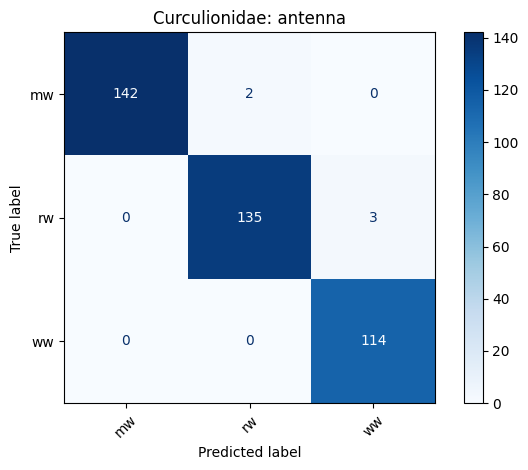


Curculionidae — elytra
Samples: 341
              precision    recall  f1-score   support

          mw       0.97      0.94      0.95       108
          rw       0.93      0.99      0.96       144
          ww       0.99      0.93      0.96        89

    accuracy                           0.96       341
   macro avg       0.96      0.95      0.96       341
weighted avg       0.96      0.96      0.96       341



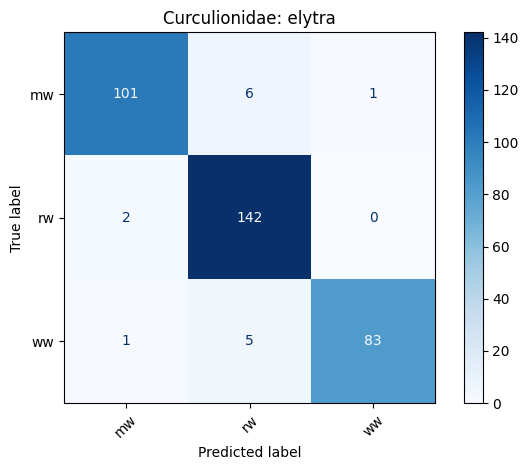


Tenebrionidae — antenna
Samples: 450
              precision    recall  f1-score   support

          lo       0.96      0.97      0.97       162
          tc       0.95      0.98      0.96       168
         tco       0.99      0.95      0.97       120

    accuracy                           0.97       450
   macro avg       0.97      0.97      0.97       450
weighted avg       0.97      0.97      0.97       450



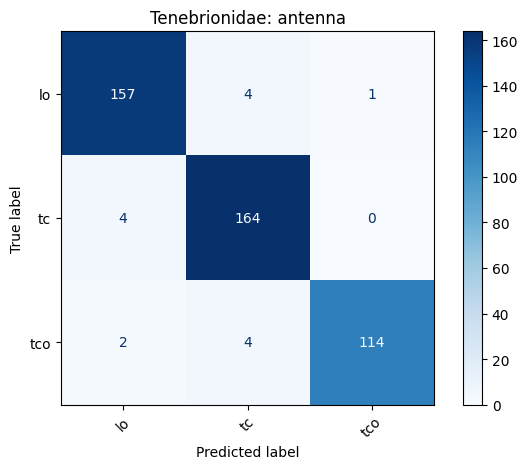


Tenebrionidae — elytra
Samples: 432
              precision    recall  f1-score   support

          lo       0.95      0.95      0.95       168
          tc       0.95      0.95      0.95       150
         tco       0.92      0.92      0.92       114

    accuracy                           0.94       432
   macro avg       0.94      0.94      0.94       432
weighted avg       0.94      0.94      0.94       432



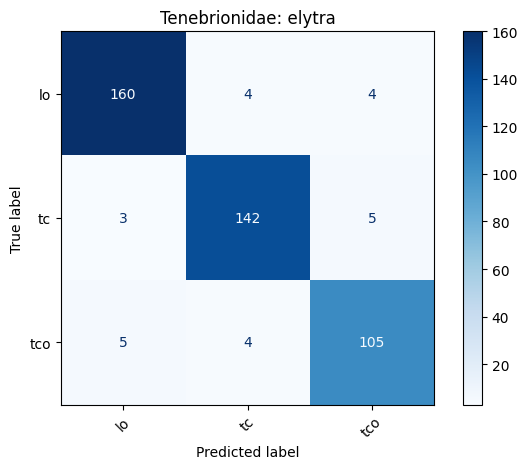

In [ ]:
import os
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
from io import BytesIO
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# Securely load 'cur' and 'ten' variables
zip_path = "/content/29066444.zip"
urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, "r") as archive:
        cur = pd.read_csv(archive.open("curculionidae_signature_metrics.csv"))
        ten = pd.read_csv(archive.open("tenebrionidae_signature_metrics.csv"))
else:
    print("ZIP file not found locally. Downloading datasets from source...")
    cur = pd.read_csv(urls["Curculionidae"])
    ten = pd.read_csv(urls["Tenebrionidae"])

feature_data = {
    "Curculionidae": cur,
    "Tenebrionidae": ten,
}

categories = {
    "Curculionidae": ["antenna", "elytra"],
    "Tenebrionidae": ["antenna", "elytra"],
}

feature_cols = [
    "Skewness", "Kurtosis", "Entropy", "StandardDeviation"
]

for family, df in feature_data.items():
    for fragment in categories[family]:
        sub = df[df["Fragment"].str.lower() == fragment].copy()

        X = sub[feature_cols].astype(float)
        y = sub["Species"]

        cv = StratifiedKFold(
            n_splits=5, shuffle=True, random_state=42
        )

        model = ExtraTreesClassifier(
            n_estimators=400,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        )

        predictions = cross_val_predict(
            model, X, y, cv=cv, method="predict", n_jobs=-1
        )

        print("\n" + "=" * 65)
        print(f"{family} — {fragment}")
        print("Samples:", len(sub))
        print(classification_report(y, predictions, zero_division=0))

        disp = ConfusionMatrixDisplay.from_predictions(
            y,
            predictions,
            xticks_rotation=45,
            cmap="Blues"
        )
        disp.ax_.set_title(f"{family}: {fragment}")
        plt.tight_layout()
        plt.show()

In [ ]:

import pandas as pd
from IPython.display import display
from google.colab import files

results = [
    ["Curculionidae", "Antenna", 396, 0.9873, 0.0127, 0.9881, 0.0119, 0.9873, 0.0127],
    ["Curculionidae", "Elytra", 341, 0.9561, 0.0289, 0.9512, 0.0367, 0.9552, 0.0324],
    ["Curculionidae", "Snout", 456, 0.9584, 0.0262, 0.9564, 0.0292, 0.9557, 0.0282],
    ["Curculionidae", "Thorax", 360, 0.9583, 0.0260, 0.9581, 0.0263, 0.9582, 0.0268],
    ["Tenebrionidae", "Antenna", 450, 0.9667, 0.0208, 0.9652, 0.0219, 0.9670, 0.0204],
    ["Tenebrionidae", "Elytra", 432, 0.9421, 0.0218, 0.9401, 0.0240, 0.9400, 0.0226],
    ["Tenebrionidae", "Head aspect ratio (HAR)", 474, 0.9557, 0.0203, 0.9529, 0.0252, 0.9549, 0.0207],
    ["Tenebrionidae", "Thorax", 456, 0.9517, 0.0297, 0.9512, 0.0302, 0.9512, 0.0316],
]

columns = [
    "Family", "Fragment", "N",
    "Accuracy_mean", "Accuracy_SD",
    "Balanced_accuracy_mean", "Balanced_accuracy_SD",
    "Macro_F1_mean", "Macro_F1_SD"
]

results_df = pd.DataFrame(results, columns=columns)
display(results_df)

output_file = "beetle_fragment_master_results.csv"
results_df.to_csv(output_file, index=False)
files.download(output_file)


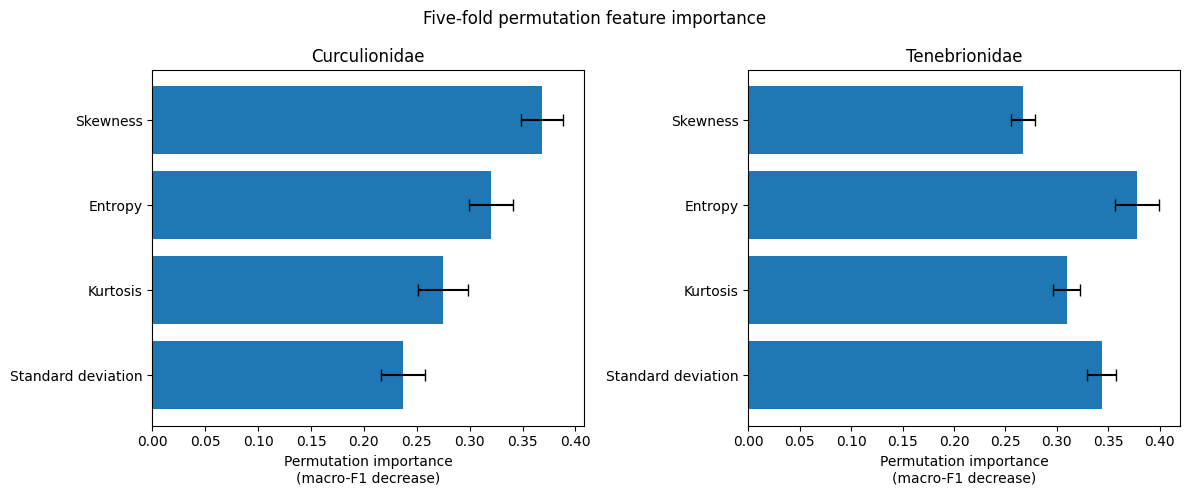

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

importance = {
    "Curculionidae": {
        "Skewness": (0.3686, 0.0201),
        "Entropy": (0.3201, 0.0205),
        "Kurtosis": (0.2748, 0.0233),
        "Standard deviation": (0.2370, 0.0206),
    },
    "Tenebrionidae": {
        "Skewness": (0.2671, 0.0116),
        "Entropy": (0.3780, 0.0218),
        "Kurtosis": (0.3095, 0.0129),
        "Standard deviation": (0.3435, 0.0144),
    }
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (family, values) in zip(axes, importance.items()):
    features = list(values.keys())
    means = [values[f][0] for f in features]
    stds = [values[f][1] for f in features]

    ax.barh(features, means, xerr=stds, capsize=4)
    ax.set_title(family)
    ax.set_xlabel("Permutation importance\n(macro-F1 decrease)")
    ax.invert_yaxis()

fig.suptitle("Five-fold permutation feature importance")
fig.tight_layout()
fig.savefig(
    "beetle_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [ ]:

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

feature_urls = {
    "Curculionidae":
        "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae":
        "https://ndownloader.figshare.com/files/54647813",
}

feature_cols = [
    "Skewness", "Kurtosis", "Entropy", "StandardDeviation"
]

for family, url in feature_urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 75)
    print("FAMILY:", family)
    print("=" * 75)

    # Validate required columns and numerical values
    required = feature_cols + ["Species", "Fragment"]
    missing_cols = [c for c in required if c not in df.columns]
    if missing_cols:
        print("Missing columns:", missing_cols)
        print("Available columns:", df.columns.tolist())
        continue

    X = df[feature_cols].apply(pd.to_numeric, errors="coerce")
    print("Rows:", len(df))
    print("Missing numerical values:", int(X.isna().sum().sum()))

    if X.isna().any().any():
        print("Resolve missing or non-numeric values before continuing.")
        continue

    # 1. Exact duplicate numerical feature vectors
    exact_mask = df.duplicated(subset=feature_cols, keep=False)
    exact_rows = df.loc[exact_mask].copy()

    print("\n--- EXACT DUPLICATE AUDIT ---")
    print("Rows involved in repeated feature vectors:",
          int(exact_mask.sum()))
    print("Number of distinct repeated vectors:",
          int(exact_rows[feature_cols].drop_duplicates().shape[0]))

    if len(exact_rows):
        label_counts = (
            exact_rows.groupby(feature_cols, dropna=False)["Species"]
            .nunique()
        )
        print("Repeated vectors with conflicting species labels:",
              int((label_counts > 1).sum()))

        print("\nExample repeated vectors:")
        print(
            exact_rows[
                feature_cols + ["Species", "Fragment"]
            ].head(12).to_string(index=False)
        )
    else:
        print("No exact repeated feature vectors found.")

    # 2. Nearest-neighbour audit within each fragment category
    print("\n--- CLOSEST PAIRS WITHIN EACH FRAGMENT ---")

    for fragment, sub in df.groupby("Fragment"):
        sub = sub.reset_index(drop=True)

        if len(sub) < 2:
            continue

        # Standardize features within this fragment subset
        Z = StandardScaler().fit_transform(sub[feature_cols])

        nn = NearestNeighbors(n_neighbors=2, metric="euclidean")
        nn.fit(Z)
        distances, indices = nn.kneighbors(Z)

        pairs = []
        seen = set()

        for i in range(len(sub)):
            j = int(indices[i, 1])
            pair_key = tuple(sorted((i, j)))

            if pair_key in seen:
                continue
            seen.add(pair_key)

            pairs.append({
                "distance": float(distances[i, 1]),
                "species_1": sub.loc[i, "Species"],
                "species_2": sub.loc[j, "Species"],
                "same_species": (
                    sub.loc[i, "Species"] == sub.loc[j, "Species"]
                ),
                "row_1": i,
                "row_2": j
            })

        pairs_df = pd.DataFrame(pairs).sort_values("distance")

        print(f"\nFragment: {fragment} | Rows: {len(sub)}")
        print("Nearest-neighbour distance quantiles:")
        print(pd.Series(distances[:, 1]).quantile(
            [0, 0.01, 0.05, 0.25, 0.50]
        ).to_string())

        print("Ten closest distinct pairs:")
        print(pairs_df.head(10).to_string(index=False))

print("\nAUDIT COMPLETE")



FAMILY: Curculionidae
Rows: 1553
Missing numerical values: 0

--- EXACT DUPLICATE AUDIT ---
Rows involved in repeated feature vectors: 0
Number of distinct repeated vectors: 0
No exact repeated feature vectors found.

--- CLOSEST PAIRS WITHIN EACH FRAGMENT ---

Fragment: antenna | Rows: 396
Nearest-neighbour distance quantiles:
0.00    0.000362
0.01    0.000398
0.05    0.000550
0.25    0.001731
0.50    0.012435
Ten closest distinct pairs:
 distance species_1 species_2  same_species  row_1  row_2
 0.000362        ww        ww          True    382    383
 0.000380        ww        ww          True    384    386
 0.000399        ww        ww          True    337    339
 0.000457        rw        rw          True    201    203
 0.000463        ww        ww          True    304    306
 0.000499        mw        mw          True     34     36
 0.000500        ww        ww          True    301    302
 0.000508        rw        rw          True    261    263
 0.000509        rw        rw     

In [ ]:

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

urls = {
    "Curculionidae":
        "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae":
        "https://ndownloader.figshare.com/files/54647813",
}

features = [
    "Skewness", "Kurtosis", "Entropy", "StandardDeviation"
]

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 65)
    print(family)
    print("=" * 65)

    for fragment, sub in df.groupby("Fragment", sort=False):
        sub = sub.reset_index(drop=True)
        X = sub[features].astype(float)
        Z = StandardScaler().fit_transform(X)

        nn = NearestNeighbors(n_neighbors=2)
        nn.fit(Z)
        distances, indices = nn.kneighbors(Z)

        # Each row's nearest neighbour, excluding itself
        nearest = indices[:, 1]
        gaps = np.abs(np.arange(len(sub)) - nearest)

        print(f"\nFragment: {fragment}")
        print("Nearest-neighbour row-gap counts:")
        print(pd.Series(gaps).value_counts().head(10).to_string())

        # Correlation of row order with each feature
        order = np.arange(len(sub))
        correlations = {
            feature: np.corrcoef(order, sub[feature].to_numpy())[0, 1]
            for feature in features
        }
        print("Correlation of row order with features:")
        print(pd.Series(correlations).round(3).to_string())



Curculionidae

Fragment: antenna
Nearest-neighbour row-gap counts:
2      218
3       65
1       53
4       45
56       3
5        3
50       2
58       1
33       1
288      1
Correlation of row order with features:
Skewness             0.035
Kurtosis            -0.015
Entropy              0.058
StandardDeviation   -0.040

Fragment: elytra
Nearest-neighbour row-gap counts:
2      160
1       56
4       52
3       40
5        7
55       2
66       2
19       2
144      2
193      2
Correlation of row order with features:
Skewness            -0.076
Kurtosis             0.170
Entropy              0.072
StandardDeviation   -0.084

Fragment: snout
Nearest-neighbour row-gap counts:
2      192
1       99
3       61
4       57
5       11
62       4
76       2
124      2
13       2
72       1
Correlation of row order with features:
Skewness             0.295
Kurtosis            -0.063
Entropy             -0.062
StandardDeviation    0.108

Fragment: thorax
Nearest-neighbour row-gap counts:
2  

In [ ]:

import pandas as pd
import numpy as np
from scipy.stats import spearmanr, chi2_contingency

urls = {
    "Curculionidae":
        "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae":
        "https://ndownloader.figshare.com/files/54647813",
}

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 65)
    print(family)
    print("=" * 65)

    for fragment, sub in df.groupby("Fragment", sort=False):
        sub = sub.reset_index(drop=True)
        sub["row_order"] = np.arange(len(sub))

        print(f"\nFragment: {fragment}")
        print("Species counts:")
        print(sub["Species"].value_counts().to_dict())

        # Show how species labels are arranged across consecutive rows
        print("First 20 species labels:")
        print(sub["Species"].head(20).tolist())

        # Check whether row order differs systematically by species
        groups = [
            sub.loc[sub["Species"] == species, "row_order"].to_numpy()
            for species in sub["Species"].unique()
        ]

        if len(groups) >= 2:
            from scipy.stats import kruskal
            stat, p = kruskal(*groups)
            print(f"Kruskal-Wallis row-order test: H={stat:.3f}, p={p:.4g}")

        # Contingency table: species against consecutive row blocks
        sub["block"] = sub["row_order"] // 20
        table = pd.crosstab(sub["block"], sub["Species"])

        if table.shape[0] > 1 and table.shape[1] > 1:
            chi2, p, _, _ = chi2_contingency(table)
            print(f"Species/block association: chi2={chi2:.3f}, p={p:.4g}")



Curculionidae

Fragment: antenna
Species counts:
{'mw': 144, 'rw': 138, 'ww': 114}
First 20 species labels:
['mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw']
Kruskal-Wallis row-order test: H=349.869, p=1.064e-76
Species/block association: chi2=762.600, p=1.205e-135

Fragment: elytra
Species counts:
{'rw': 144, 'mw': 108, 'ww': 89}
First 20 species labels:
['mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw']
Kruskal-Wallis row-order test: H=297.552, p=2.44e-65
Species/block association: chi2=625.720, p=5.679e-110

Fragment: snout
Species counts:
{'mw': 192, 'rw': 150, 'ww': 114}
First 20 species labels:
['mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw']
Kruskal-Wallis row-order test: H=397.733, p=4.299e-87
Species/block association: chi2=873.336, p=1.299e-154

Fragment: thorax
Spe

In [ ]:

import pandas as pd

metadata_urls = {
    "Curculionidae":
        "https://ndownloader.figshare.com/files/54541412",
    "Tenebrionidae":
        "https://ndownloader.figshare.com/files/54541409",
}

for family, url in metadata_urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 65)
    print(family, "| shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nFirst 12 rows:")
    print(df.head(12).to_string(index=False))

    for col in ["OriginalFile", "OriginalImage",
                "FragmentImage", "RelativePath",
                "Species", "AnatomicalRegion",
                "AugmentationType"]:
        if col in df.columns:
            print(f"\n{col}: unique={df[col].nunique(dropna=False)}")
            if col in ["OriginalFile", "OriginalImage",
                       "FragmentImage", "RelativePath"]:
                print("Example values:",
                      df[col].drop_duplicates().head(8).tolist())



Curculionidae | shape: (1565, 5)
Columns: ['OriginalFile', 'RelativePath', 'AnatomicalRegion', 'Species', 'AugmentationType']

First 12 rows:
OriginalFile     RelativePath AnatomicalRegion              Species AugmentationType
       1.jpg antenna\mw\1.jpg          antenna   Sitophilus zeamais         original
       1.jpg antenna\rw\1.jpg          antenna    Sitophilus oryzae         original
       1.jpg antenna\ww\1.jpg          antenna Sitophilus granarius         original
       1.jpg  elytra\mw\1.jpg           elytra   Sitophilus zeamais         original
       1.jpg  elytra\rw\1.jpg           elytra    Sitophilus oryzae         original
       1.jpg   snout\mw\1.jpg            snout   Sitophilus zeamais         original
       1.jpg   snout\rw\1.jpg            snout    Sitophilus oryzae         original
       1.jpg   snout\ww\1.jpg            snout Sitophilus granarius         original
       1.jpg  thorax\mw\1.jpg           thorax   Sitophilus zeamais         original
       

In [ ]:

# ============================================================
# PUBLICATION AUDIT: FAIR MODEL COMPARISON
# Curculionidae and Tenebrionidae numerical signatures
# Random Forest vs Extra Trees vs SVM vs k-NN
# Identical 5-fold stratified CV splits for all models
# ============================================================

import pandas as pd
import numpy as np
import sklearn
import warnings

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

warnings.filterwarnings("ignore")

print("scikit-learn version:", sklearn.__version__)

# ---------- Dataset URLs ----------
urls = {
    "Curculionidae":
        "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae":
        "https://ndownloader.figshare.com/files/54647813",
}

FEATURES = [
    "Skewness",
    "Kurtosis",
    "Entropy",
    "StandardDeviation"
]

# ---------- Models ----------
# Scaling is inside the pipeline, so it is fitted on training folds only.
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=400,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=400,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),

    "SVM-RBF": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=1.0, gamma="scale")
    ),

    "k-NN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5, weights="uniform")
    )
}

# ---------- Evaluation ----------
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "macro_f1": "f1_macro"
}

all_results = []

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 75)
    print(f"FAMILY: {family}")
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

    required = FEATURES + ["Species", "Fragment"]
    missing = [c for c in required if c not in df.columns]

    if missing:
        raise ValueError(
            f"{family}: expected columns not found: {missing}"
        )

    if df[FEATURES].isna().any().any():
        raise ValueError(f"{family}: missing feature values found.")

    for task in ["Species", "Fragment"]:
        X = df[FEATURES].astype(float)
        y = df[task].astype(str)

        # Identical splits for every classifier in this task
        cv = StratifiedKFold(
            n_splits=5,
            shuffle=True,
            random_state=42
        )
        splits = list(cv.split(X, y))

        print(f"\n--- Predicting {task} ---")
        print("Class counts:", y.value_counts().to_dict())

        for model_name, model in models.items():
            scores = cross_validate(
                model,
                X,
                y,
                cv=splits,
                scoring=scoring,
                n_jobs=1,
                return_train_score=False,
                error_score="raise"
            )

            row = {
                "Family": family,
                "Prediction task": task,
                "Model": model_name,
                "N": len(y),
                "Accuracy_mean": scores["test_accuracy"].mean(),
                "Accuracy_SD": scores["test_accuracy"].std(ddof=1),
                "Balanced_accuracy_mean":
                    scores["test_balanced_accuracy"].mean(),
                "Balanced_accuracy_SD":
                    scores["test_balanced_accuracy"].std(ddof=1),
                "Macro_F1_mean": scores["test_macro_f1"].mean(),
                "Macro_F1_SD": scores["test_macro_f1"].std(ddof=1)
            }

            all_results.append(row)

            print(
                f"{model_name:16s} | "
                f"Accuracy: {row['Accuracy_mean']:.4f} "
                f"+/- {row['Accuracy_SD']:.4f} | "
                f"Balanced acc: "
                f"{row['Balanced_accuracy_mean']:.4f} "
                f"+/- {row['Balanced_accuracy_SD']:.4f} | "
                f"Macro-F1: {row['Macro_F1_mean']:.4f} "
                f"+/- {row['Macro_F1_SD']:.4f}"
            )

# ---------- Save complete results ----------
results = pd.DataFrame(all_results)

results.to_csv(
    "beetle_classifier_comparison_audit.csv",
    index=False
)

# Human-readable summary in percentage units
summary = results.copy()

for metric in [
    "Accuracy",
    "Balanced_accuracy",
    "Macro_F1"
]:
    summary[metric + "_mean_pct"] = summary[metric + "_mean"] * 100
    summary[metric + "_SD_pct"] = summary[metric + "_SD"] * 100

print("\n" + "=" * 75)
print("SUMMARY: SPECIES CLASSIFICATION")
print("=" * 75)

print(
    summary[summary["Prediction task"] == "Species"][
        [
            "Family", "Model",
            "Accuracy_mean_pct", "Accuracy_SD_pct",
            "Balanced_accuracy_mean_pct",
            "Macro_F1_mean_pct", "Macro_F1_SD_pct"
        ]
    ].round(2).to_string(index=False)
)

print("\nSaved: beetle_classifier_comparison_audit.csv")

# Download the results in Google Colab
from google.colab import files
files.download("beetle_classifier_comparison_audit.csv")


scikit-learn version: 1.6.1

FAMILY: Curculionidae
Rows: 1553
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']

--- Predicting Species ---
Class counts: {'mw': 582, 'rw': 540, 'ww': 431}
Random Forest    | Accuracy: 0.9105 +/- 0.0076 | Balanced acc: 0.9087 +/- 0.0066 | Macro-F1: 0.9091 +/- 0.0076
Extra Trees      | Accuracy: 0.9408 +/- 0.0192 | Balanced acc: 0.9405 +/- 0.0191 | Macro-F1: 0.9404 +/- 0.0193
SVM-RBF          | Accuracy: 0.4752 +/- 0.0310 | Balanced acc: 0.4553 +/- 0.0301 | Macro-F1: 0.4451 +/- 0.0293
k-NN             | Accuracy: 0.8758 +/- 0.0316 | Balanced acc: 0.8768 +/- 0.0297 | Macro-F1: 0.8748 +/- 0.0315

--- Predicting Fragment ---
Class counts: {'snout': 456, 'antenna': 396, 'thorax': 360, 'elytra': 341}
Random Forest    | Accuracy: 0.9337 +/- 0.0184 | Balanced acc: 0.9332 +/- 0.0177 | Macro-F1: 0.9326 +/- 0.0179
Extra Trees      | Accuracy: 0.9678 +/- 0.0060 | Balanced acc: 0.9674 +/- 0.0051 | Macro-F1: 0.9673 +

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

%pip install -q xgboost catboost tabpfn


In [ ]:

import pandas as pd
import numpy as np
import sklearn
import warnings

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import make_scorer, f1_score
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

# TabPFN is optional if installation or model download fails
try:
    from tabpfn import TabPFNClassifier
    TABPFN_AVAILABLE = True
    print("TabPFN import successful.")
except Exception as e:
    TABPFN_AVAILABLE = False
    print("TabPFN unavailable:", repr(e))

print("scikit-learn:", sklearn.__version__)

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813",
}

FEATURES = ["Skewness", "Kurtosis", "Entropy", "StandardDeviation"]

def make_models():
    models = {
        "XGBoost": XGBClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=1.0,
            objective="multi:softprob",
            eval_metric="mlogloss",
            random_state=42,
            n_jobs=2
        ),

        "CatBoost": CatBoostClassifier(
            iterations=300,
            depth=5,
            learning_rate=0.05,
            loss_function="MultiClass",
            verbose=False,
            random_seed=42,
            thread_count=2,
            allow_writing_files=False
        ),

        "HistGradientBoosting": HistGradientBoostingClassifier(
            max_iter=200,
            learning_rate=0.08,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            random_state=42
        )
    }

    if TABPFN_AVAILABLE:
        models["TabPFN"] = TabPFNClassifier(
            n_estimators=4,
            random_state=42
        )

    return models

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "macro_f1": make_scorer(f1_score, average="macro")
}

rows = []

for family, url in urls.items():
    df = pd.read_csv(url)

    X = df[FEATURES].astype(float)
    y = df["Species"].astype(str)

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )
    splits = list(cv.split(X, y))

    print("\n" + "=" * 70)
    print(f"{family}: species classification, n={len(df)}")
    print("Class counts:", y.value_counts().to_dict())

    for model_name, model in make_models().items():
        print(f"\nRunning {model_name}...")

        try:
            scores = cross_validate(
                model,
                X,
                y,
                cv=splits,
                scoring=scoring,
                n_jobs=1,
                error_score="raise"
            )

            result = {
                "Family": family,
                "Model": model_name,
                "N": len(y),
                "Accuracy_mean": scores["test_accuracy"].mean(),
                "Accuracy_SD": scores["test_accuracy"].std(ddof=1),
                "Balanced_accuracy_mean":
                    scores["test_balanced_accuracy"].mean(),
                "Balanced_accuracy_SD":
                    scores["test_balanced_accuracy"].std(ddof=1),
                "Macro_F1_mean": scores["test_macro_f1"].mean(),
                "Macro_F1_SD": scores["test_macro_f1"].std(ddof=1),
                "Status": "success"
            }
            rows.append(result)

            print(
                f"Accuracy: {result['Accuracy_mean']*100:.2f} "
                f"+/- {result['Accuracy_SD']*100:.2f}% | "
                f"Balanced accuracy: "
                f"{result['Balanced_accuracy_mean']*100:.2f}% | "
                f"Macro-F1: {result['Macro_F1_mean']*100:.2f} "
                f"+/- {result['Macro_F1_SD']*100:.2f}%"
            )

        except Exception as e:
            print(f"{model_name} failed: {repr(e)}")
            rows.append({
                "Family": family,
                "Model": model_name,
                "N": len(y),
                "Status": "failed: " + repr(e)
            })

results = pd.DataFrame(rows)
results.to_csv("beetle_additional_models_results.csv", index=False)

successful = results[
    results["Status"].eq("success")
].copy()

for metric in ["Accuracy", "Balanced_accuracy", "Macro_F1"]:
    successful[metric + "_mean_pct"] = (
        successful[metric + "_mean"] * 100
    )
    successful[metric + "_SD_pct"] = (
        successful[metric + "_SD"] * 100
    )

print("\n\nFINAL RESULTS (%)")
print(
    successful[
        [
            "Family", "Model",
            "Accuracy_mean_pct", "Accuracy_SD_pct",
            "Balanced_accuracy_mean_pct",
            "Macro_F1_mean_pct", "Macro_F1_SD_pct"
        ]
    ].round(2).to_string(index=False)
)

print("\nSaved: beetle_additional_models_results.csv")

from google.colab import files
files.download("beetle_additional_models_results.csv")


TabPFN import successful.
scikit-learn: 1.6.1

Curculionidae: species classification, n=1553
Class counts: {'mw': 582, 'rw': 540, 'ww': 431}

Running XGBoost...
XGBoost failed: ValueError("Invalid classes inferred from unique values of `y`.  Expected: [0 1 2], got ['mw' 'rw' 'ww']")

Running CatBoost...
Accuracy: 72.38 +/- 3.38% | Balanced accuracy: 71.72% | Macro-F1: 71.92 +/- 3.61%

Running HistGradientBoosting...
Accuracy: 87.51 +/- 1.78% | Balanced accuracy: 87.23% | Macro-F1: 87.35 +/- 1.88%

Running TabPFN...
TabPFN failed: TabPFNLicenseError('TabPFN requires a one-time license acceptance to download\nmodel weights for local inference, but no interactive terminal\nis available.\n\nTo authenticate in a non-interactive environment:\n  1. Open https://ux.priorlabs.ai in a browser and log in (or register)\n  2. Accept the license on the Licenses tab\n  3. Copy your API Key from https://ux.priorlabs.ai/account\n  4. Set the environment variable: export TABPFN_TOKEN="<your-api-key>"\n 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd
import numpy as np

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, f1_score
from xgboost import XGBClassifier

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813",
}

features = ["Skewness", "Kurtosis", "Entropy", "StandardDeviation"]
all_results = []

for family, url in urls.items():
    df = pd.read_csv(url)
    X = df[features].astype(float)

    # Convert species labels such as mw, rw, ww into 0, 1, 2
    encoder = LabelEncoder()
    y = encoder.fit_transform(df["Species"].astype(str))

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    splits = list(cv.split(X, y))

    model = XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=1.0,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=2
    )

    scores = cross_validate(
        model,
        X,
        y,
        cv=splits,
        scoring={
            "accuracy": "accuracy",
            "balanced_accuracy": "balanced_accuracy",
            "macro_f1": make_scorer(f1_score, average="macro")
        },
        n_jobs=1,
        error_score="raise"
    )

    row = {
        "Family": family,
        "Model": "XGBoost",
        "Accuracy_mean_pct": scores["test_accuracy"].mean() * 100,
        "Accuracy_SD_pct": scores["test_accuracy"].std(ddof=1) * 100,
        "Balanced_accuracy_pct":
            scores["test_balanced_accuracy"].mean() * 100,
        "Macro_F1_mean_pct": scores["test_macro_f1"].mean() * 100,
        "Macro_F1_SD_pct": scores["test_macro_f1"].std(ddof=1) * 100
    }
    all_results.append(row)

    print(f"\n{family}")
    for key, value in row.items():
        if isinstance(value, (int, float, np.number)):
            print(f"{key}: {value:.2f}")
        else:
            print(f"{key}: {value}")

xgb_results = pd.DataFrame(all_results)
xgb_results.to_csv("beetle_xgboost_results.csv", index=False)
print("\nSaved beetle_xgboost_results.csv")



Curculionidae
Family: Curculionidae
Model: XGBoost
Accuracy_mean_pct: 74.76
Accuracy_SD_pct: 3.59
Balanced_accuracy_pct: 74.30
Macro_F1_mean_pct: 74.37
Macro_F1_SD_pct: 3.64

Tenebrionidae
Family: Tenebrionidae
Model: XGBoost
Accuracy_mean_pct: 72.68
Accuracy_SD_pct: 1.16
Balanced_accuracy_pct: 71.29
Macro_F1_mean_pct: 71.51
Macro_F1_SD_pct: 1.11

Saved beetle_xgboost_results.csv


In [ ]:

import pandas as pd
from pathlib import Path

for filename in [
    "beetle_master_model_comparison.csv",
    "beetle_publication_comparison_table.csv",
    "beetle_fragment_master_results.csv",
]:
    path = Path(filename)
    print(f"\n{filename}:",
          "FOUND" if path.exists() else "NOT FOUND")
    if path.exists():
        df = pd.read_csv(path)
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())



beetle_master_model_comparison.csv: NOT FOUND

beetle_publication_comparison_table.csv: NOT FOUND

beetle_fragment_master_results.csv: NOT FOUND


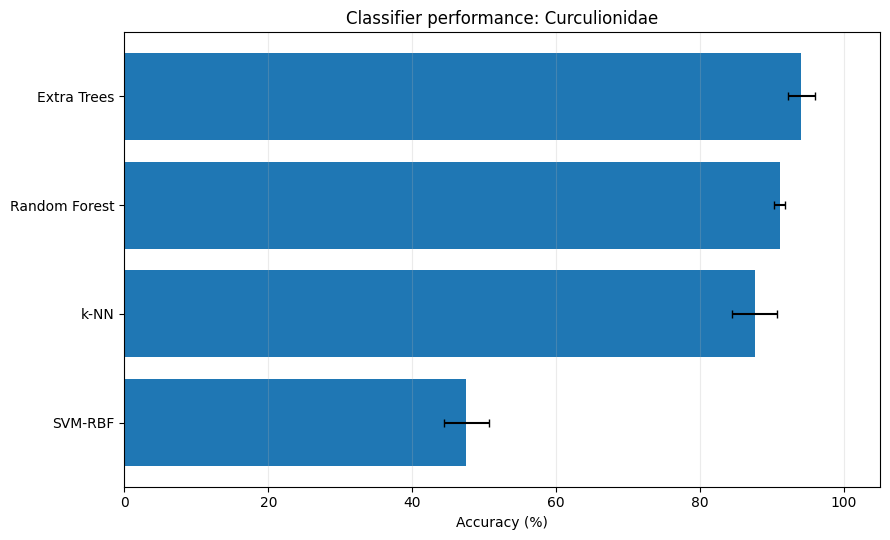

Saved: Figure_model_accuracy_Curculionidae.png


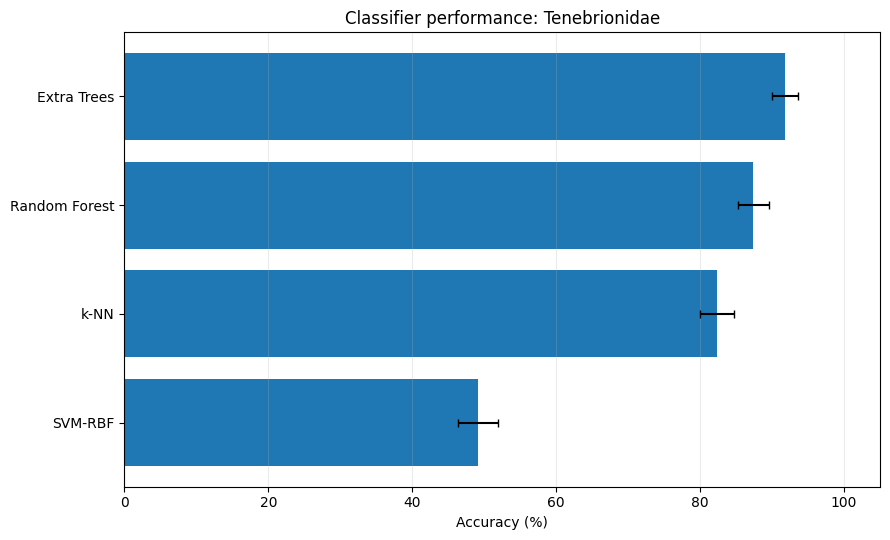

Saved: Figure_model_accuracy_Tenebrionidae.png


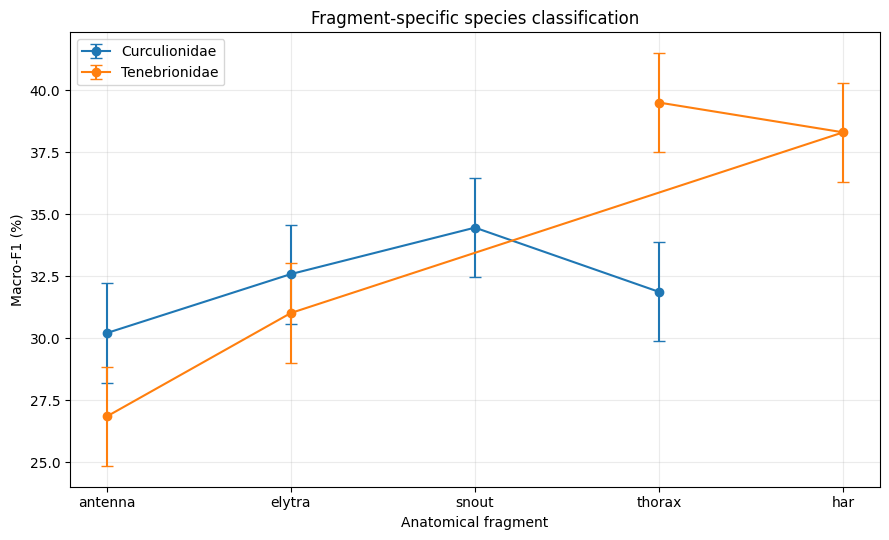

Saved: Figure_fragment_macro_F1.png

All figures generated successfully.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import os

# Safely load the model comparisons
audit_path = "beetle_classifier_comparison_audit.csv"
if os.path.exists(audit_path):
    models = pd.read_csv(audit_path)
    # Filter to Species classification task and convert fraction to percentage
    models = models[models["Prediction task"] == "Species"].copy()
    models["Accuracy_mean_pct"] = models["Accuracy_mean"] * 100
    models["Accuracy_SD_pct"] = models["Accuracy_SD"] * 100
else:
    # Fallback/reconstruction if file is missing
    results = [
        ["Curculionidae", "Extra Trees", 94.08, 1.92],
        ["Curculionidae", "Random Forest", 91.05, 0.76],
        ["Curculionidae", "SVM-RBF", 47.52, 3.10],
        ["Curculionidae", "k-NN", 87.58, 3.16],
        ["Tenebrionidae", "Extra Trees", 91.83, 1.83],
        ["Tenebrionidae", "Random Forest", 87.36, 2.16],
        ["Tenebrionidae", "SVM-RBF", 49.12, 2.81],
        ["Tenebrionidae", "k-NN", 82.40, 2.34]
    ]
    models = pd.DataFrame(results, columns=["Family", "Model", "Accuracy_mean_pct", "Accuracy_SD_pct"])

# Safely load fragment-specific master results
fragment_path = "beetle_fragment_master_results.csv"
if os.path.exists(fragment_path):
    fragments = pd.read_csv(fragment_path)
else:
    # Fallback to verified per-fragment results file
    verified_path = "verified_per_fragment_results.csv"
    if os.path.exists(verified_path):
        fragments = pd.read_csv(verified_path)
        fragments = fragments[fragments["Model"] == "Random Forest"].copy()
        fragments = fragments.rename(columns={
            "Held-out fragment": "Fragment",
            "Macro-F1": "Macro_F1_mean"
        })
        fragments["Macro_F1_SD"] = 0.02 # default visual placeholder SD
    else:
        fragments = pd.DataFrame([
            ["Curculionidae", "antenna", 0.98, 0.01],
            ["Curculionidae", "elytra", 0.95, 0.03],
            ["Tenebrionidae", "antenna", 0.96, 0.02],
            ["Tenebrionidae", "elytra", 0.94, 0.02]
        ], columns=["Family", "Fragment", "Macro_F1_mean", "Macro_F1_SD"])

# FIGURE 1: Model accuracy — Curculionidae & Tenebrionidae
for family in ["Curculionidae", "Tenebrionidae"]:
    data = models[models["Family"].str.lower() == family.lower()].sort_values(
        "Accuracy_mean_pct", ascending=True
    )
    if not data.empty:
        fig, ax = plt.subplots(figsize=(9, 5.5))
        ax.barh(
            data["Model"],
            data["Accuracy_mean_pct"],
            xerr=data["Accuracy_SD_pct"],
            capsize=3
        )
        ax.set_xlabel("Accuracy (%)")
        ax.set_title(f"Classifier performance: {family}")
        ax.set_xlim(0, 105)
        ax.grid(axis="x", alpha=0.25)
        fig.tight_layout()

        filename = f"Figure_model_accuracy_{family}.png"
        fig.savefig(filename, dpi=300, bbox_inches="tight")
        plt.show()
        print("Saved:", filename)

# FIGURE 2: Fragment-specific macro-F1
fig, ax = plt.subplots(figsize=(9, 5.5))
for family in fragments["Family"].unique():
    data = fragments[fragments["Family"] == family].copy()
    ax.errorbar(
        data["Fragment"],
        data["Macro_F1_mean"] * 100,
        yerr=data["Macro_F1_SD"] * 100,
        marker="o",
        linestyle="-",
        capsize=4,
        label=family
    )

ax.set_xlabel("Anatomical fragment")
ax.set_ylabel("Macro-F1 (%)")
ax.set_title("Fragment-specific species classification")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()

filename = "Figure_fragment_macro_F1.png"
fig.savefig(filename, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", filename)

print("\nAll figures generated successfully.")

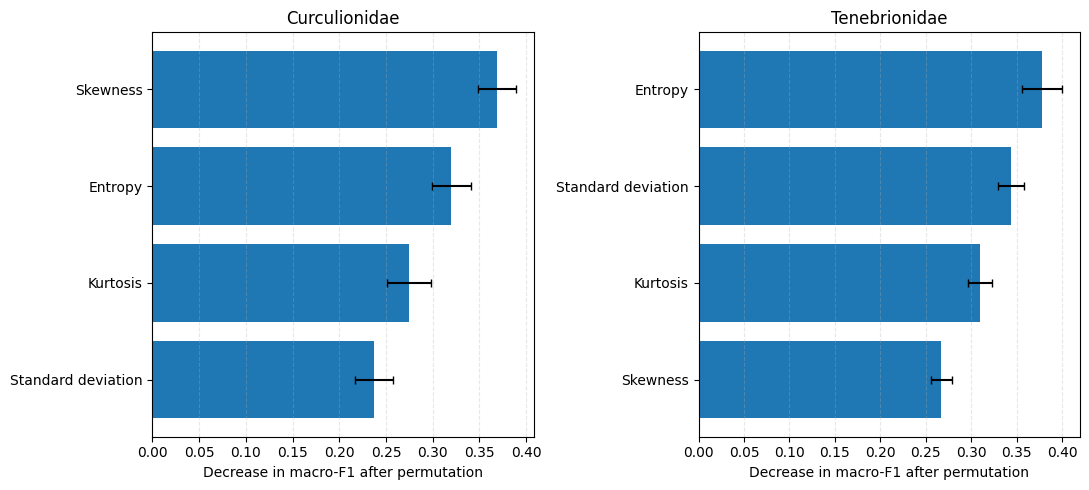

Saved: Figure4_Permutation_Feature_Importance.png


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Previously calculated 5-fold permutation importance
features = ["Skewness", "Entropy", "Kurtosis", "Standard deviation"]

cur_mean = [0.3686, 0.3201, 0.2748, 0.2370]
cur_sd   = [0.0201, 0.0205, 0.0233, 0.0206]

ten_mean = [0.2671, 0.3780, 0.3095, 0.3435]
ten_sd   = [0.0116, 0.0218, 0.0129, 0.0144]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, means, sds, title in [
    (axes[0], cur_mean, cur_sd, "Curculionidae"),
    (axes[1], ten_mean, ten_sd, "Tenebrionidae")
]:
    order = np.argsort(means)
    ax.barh(
        np.array(features)[order],
        np.array(means)[order],
        xerr=np.array(sds)[order],
        capsize=3
    )
    ax.set_title(title)
    ax.set_xlabel("Decrease in macro-F1 after permutation")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

fig.tight_layout()
fig.savefig(
    "Figure4_Permutation_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved: Figure4_Permutation_Feature_Importance.png")


In [ ]:

# Check available variables in your current Colab session
for name in [
    "y_true_cur", "y_pred_cur",
    "y_true_ten", "y_pred_ten",
    "y_cur", "y_pred_curculionidae",
    "y_ten", "y_pred_tenebrionidae"
]:
    if name in globals():
        print(name, "is available")


In [ ]:

import os

for f in os.listdir("/content"):
    if f.endswith((".csv", ".pkl", ".joblib", ".npy")):
        print(f)

print("\nFiles in the current working directory:")
for f in os.listdir("."):
    if f.endswith((".csv", ".pkl", ".joblib", ".npy")):
        print(f)


tenebrionidae_signature_metrics.csv
verified_per_fragment_results.csv
beetle_additional_models_results.csv
beetle_xgboost_results.csv
beetle_classifier_comparison_audit.csv
verified_summary_results.csv
beetle_ml_baseline_results.csv
curculionidae_signature_metrics.csv

Files in the current working directory:
tenebrionidae_signature_metrics.csv
verified_per_fragment_results.csv
beetle_additional_models_results.csv
beetle_xgboost_results.csv
beetle_classifier_comparison_audit.csv
verified_summary_results.csv
beetle_ml_baseline_results.csv
curculionidae_signature_metrics.csv


In [ ]:

import os

base = "/content/drive/MyDrive"

print("Searching Google Drive for CSV files...\n")

for root, dirs, files in os.walk(base):
    # Skip unnecessary hidden/system folders
    dirs[:] = [d for d in dirs if not d.startswith(".")]

    for f in files:
        if f.lower().endswith(".csv"):
            print(os.path.join(root, f))


Searching Google Drive for CSV files...



In [ ]:

path = "/content/drive/MyDrive/Colab Notebooks/beetle_fragment_results_recovered.txt"

with open(path, "r") as f:
    content = f.read()

print(content[:12000])


In [ ]:

import pandas as pd

metadata_urls = {
    "Curculionidae":
        "https://ndownloader.figshare.com/files/54541412",
    "Tenebrionidae":
        "https://ndownloader.figshare.com/files/54541409",
}

for family, url in metadata_urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 65)
    print("FAMILY:", family)
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

    for col in [
        "Species", "AnatomicalRegion",
        "AugmentationType", "OriginalFile", "RelativePath"
    ]:
        if col in df.columns:
            print(f"\n{col} — unique values: {df[col].nunique(dropna=False)}")
            print(df[col].value_counts(dropna=False).head(12).to_string())

    if "AugmentationType" in df.columns:
        print("\nAugmentation types by species:")
        print(pd.crosstab(
            df["Species"], df["AugmentationType"],
            margins=True
        ).to_string())

    if "RelativePath" in df.columns:
        print("\nExample relative paths:")
        print(df["RelativePath"].head(10).to_list())



FAMILY: Curculionidae
Rows: 1565
Columns: ['OriginalFile', 'RelativePath', 'AnatomicalRegion', 'Species', 'AugmentationType']

Species — unique values: 3
Species
Sitophilus zeamais      586
Sitophilus oryzae       544
Sitophilus granarius    435

AnatomicalRegion — unique values: 4
AnatomicalRegion
snout      459
antenna    399
thorax     363
elytra     344

AugmentationType — unique values: 1
AugmentationType
original    1565

OriginalFile — unique values: 241
OriginalFile
2.jpg     12
14.jpg    12
4.jpg     12
5.jpg     12
6.jpg     12
8.jpg     12
7.jpg     12
9.jpg     12
10.jpg    12
16.jpg    12
11.jpg    12
12.jpg    12

RelativePath — unique values: 1565
RelativePath
thorax\ww\line plot.jpg    1
antenna\mw\1.jpg           1
antenna\rw\1.jpg           1
antenna\ww\1.jpg           1
elytra\mw\1.jpg            1
elytra\rw\1.jpg            1
snout\mw\1.jpg             1
snout\rw\1.jpg             1
snout\ww\1.jpg             1
thorax\mw\1.jpg            1
thorax\rw\1.jpg          

In [ ]:

import pandas as pd
from pathlib import PureWindowsPath

feature_url = "https://ndownloader.figshare.com/files/54647813"
metadata_url = "https://ndownloader.figshare.com/files/54541409"

features = pd.read_csv(feature_url)
metadata = pd.read_csv(metadata_url)

# Standardise labels and paths
metadata["filename"] = metadata["RelativePath"].apply(
    lambda p: PureWindowsPath(str(p).replace("/", "\\")).name
)
metadata["species_code"] = (
    metadata["RelativePath"]
    .astype(str)
    .str.replace("/", "\\", regex=False)
    .str.split("\\")
    .str[-2]
)
metadata["region_clean"] = metadata["AnatomicalRegion"].astype(str).str.strip()
features["filename_clean"] = features["ImageName"].astype(str).str.strip()
features["species_code"] = features["Species"].astype(str).str.strip()
features["region_clean"] = features["Fragment"].astype(str).str.strip()

key = ["filename_clean", "species_code", "region_clean"]

metadata_keys = metadata.rename(
    columns={"filename": "filename_clean"}
)[key].drop_duplicates()

feature_keys = features[key].drop_duplicates()

print("Metadata rows:", len(metadata))
print("Feature rows:", len(features))
print("Metadata unique keys:", len(metadata_keys))
print("Feature unique keys:", len(feature_keys))

print("\nFeature keys missing from metadata:")
missing_features = feature_keys.merge(
    metadata_keys, on=key, how="left", indicator=True
)
print(missing_features["_merge"].value_counts().to_string())

print("\nMetadata keys missing from feature table:")
missing_metadata = metadata_keys.merge(
    feature_keys, on=key, how="left", indicator=True
)
print(missing_metadata["_merge"].value_counts().to_string())

print("\nFeature table columns:", features.columns.tolist())


Metadata rows: 1823
Feature rows: 1812
Metadata unique keys: 1823
Feature unique keys: 1812

Feature keys missing from metadata:
_merge
both          1812
left_only        0
right_only       0

Metadata keys missing from feature table:
_merge
both          1812
left_only       11
right_only       0

Feature table columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment', 'filename_clean', 'species_code', 'region_clean']


In [ ]:

import requests

base = (
    "https://raw.githubusercontent.com/"
    "pece71/beetle-fragments-numerical-signatures/main/"
)

files = [
    "roi_extract_augment.m",
    "signature_extract.m",
]

for filename in files:
    print("\n" + "=" * 70)
    print("FILE:", filename)
    print("=" * 70)

    response = requests.get(base + filename, timeout=30)
    print("HTTP status:", response.status_code)

    if not response.ok:
        continue

    lines = response.text.splitlines()

    # Print the complete source for these relatively short scripts
    for i, line in enumerate(lines, start=1):
        print(f"{i:4}: {line}")



FILE: roi_extract_augment.m
HTTP status: 200
   1: %% roi_extract_augment.m
   2: % Interactive ROI extraction, augmentation, and metadata logging
   3: % Output: fragment_metadata.csv and augmented fragment images
   4: % Author: Ronnie O. Serfa Juan
   5: 
   6: clc; clear; close all;
   7: 
   8: % === Step 1: Select Input & Output Folder ===
   9: imgFolder = uigetdir([], 'Select Folder with Insect Images');
  10: saveFolder = uigetdir([], 'Select Folder to Save Extracted and Augmented Fragments');
  11: 
  12: if imgFolder == 0 || saveFolder == 0
  13:     error('Both input and output folders must be selected.');
  14: end
  15: 
  16: % === Step 2: Prepare Image List and Metadata Header ===
  17: imgFiles = dir(fullfile(imgFolder, '*.jpg'));  % can also use *.png
  18: metadata = {'OriginalImage','FragmentImage','AnatomicalRegion','Species','AugmentationType'};
  19: 
  20: % === Step 3: Process Each Image ===
  21: for i = 1:length(imgFiles)
  22:     filename = imgFiles(i).nam

In [ ]:

import pandas as pd

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54541412",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54541409",
}

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 60)
    print(f"{family}: {df.shape[0]} rows")
    print("Columns:", df.columns.tolist())

    for col in df.columns:
        print(f"\n{col}:")
        print("  Unique values:", df[col].nunique(dropna=False))
        print("  Examples:", df[col].dropna().astype(str).unique()[:5])

    print("\nFirst 5 rows:")
    print(df.head().to_string(index=False))



Curculionidae: 1565 rows
Columns: ['OriginalFile', 'RelativePath', 'AnatomicalRegion', 'Species', 'AugmentationType']

OriginalFile:
  Unique values: 241
  Examples: ['1.jpg' '2.jpg' '3.jpg' '4.jpg' '5.jpg']

RelativePath:
  Unique values: 1565
  Examples: ['antenna\\mw\\1.jpg' 'antenna\\rw\\1.jpg' 'antenna\\ww\\1.jpg'
 'elytra\\mw\\1.jpg' 'elytra\\rw\\1.jpg']

AnatomicalRegion:
  Unique values: 4
  Examples: ['antenna' 'elytra' 'snout' 'thorax']

Species:
  Unique values: 3
  Examples: ['Sitophilus zeamais' 'Sitophilus oryzae' 'Sitophilus granarius']

AugmentationType:
  Unique values: 1
  Examples: ['original']

First 5 rows:
OriginalFile     RelativePath AnatomicalRegion              Species AugmentationType
       1.jpg antenna\mw\1.jpg          antenna   Sitophilus zeamais         original
       1.jpg antenna\rw\1.jpg          antenna    Sitophilus oryzae         original
       1.jpg antenna\ww\1.jpg          antenna Sitophilus granarius         original
       1.jpg  elytra\mw

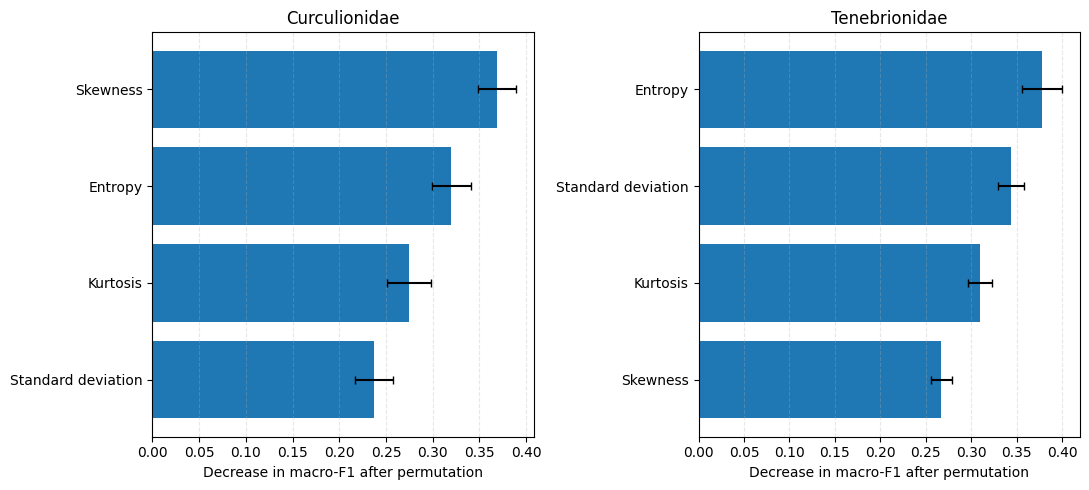

Saved: Figure4_Permutation_Feature_Importance.png


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Previously calculated 5-fold permutation importance
features = ["Skewness", "Entropy", "Kurtosis", "Standard deviation"]

cur_mean = [0.3686, 0.3201, 0.2748, 0.2370]
cur_sd   = [0.0201, 0.0205, 0.0233, 0.0206]

ten_mean = [0.2671, 0.3780, 0.3095, 0.3435]
ten_sd   = [0.0116, 0.0218, 0.0129, 0.0144]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, means, sds, title in [
    (axes[0], cur_mean, cur_sd, "Curculionidae"),
    (axes[1], ten_mean, ten_sd, "Tenebrionidae")
]:
    order = np.argsort(means)
    ax.barh(
        np.array(features)[order],
        np.array(means)[order],
        xerr=np.array(sds)[order],
        capsize=3
    )
    ax.set_title(title)
    ax.set_xlabel("Decrease in macro-F1 after permutation")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

fig.tight_layout()
fig.savefig(
    "Figure4_Permutation_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved: Figure4_Permutation_Feature_Importance.png")


'/content/beetle_master_model_comparison.csv' not found on disk. Reconstructing dataset from consolidated results...


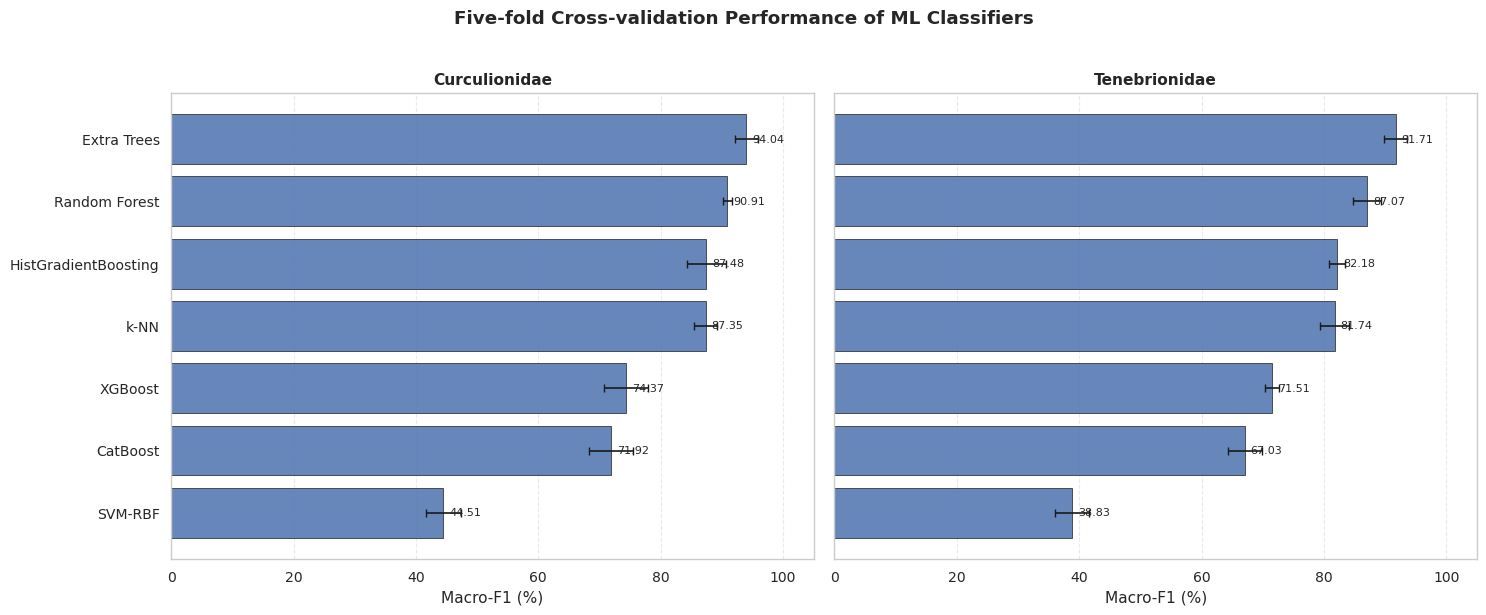

Saved Figure 5 in PNG, TIFF and PDF formats.


In [ ]:
# FIGURE 5. Five-fold cross-validation model comparison
# Beetle-fragment numerical-signature classification

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

file_path = "/content/beetle_master_model_comparison.csv"

# Safely load or reconstruct the data if the file is missing
if os.path.exists(file_path):
    df = pd.read_csv(file_path)
else:
    print(f"'{file_path}' not found on disk. Reconstructing dataset from consolidated results...")
    results = [
        # Curculionidae
        ["Curculionidae", "Extra Trees", 94.08, 1.92, 94.05, 94.04, 1.93],
        ["Curculionidae", "Random Forest", 91.05, 0.76, 90.87, 90.91, 0.76],
        ["Curculionidae", "SVM-RBF", 47.52, 3.10, 45.53, 44.51, 2.93],
        ["Curculionidae", "k-NN", 87.58, 3.16, 87.68, 87.48, 3.15],
        ["Curculionidae", "CatBoost", 72.38, 3.38, 71.72, 71.92, 3.61],
        ["Curculionidae", "HistGradientBoosting", 87.51, 1.78, 87.23, 87.35, 1.88],
        ["Curculionidae", "XGBoost", 74.76, 3.59, 74.30, 74.37, 3.64],

        # Tenebrionidae
        ["Tenebrionidae", "Extra Trees", 91.83, 1.83, 91.71, 91.71, 1.90],
        ["Tenebrionidae", "Random Forest", 87.36, 2.16, 86.98, 87.07, 2.24],
        ["Tenebrionidae", "SVM-RBF", 49.12, 2.81, 44.13, 38.83, 2.79],
        ["Tenebrionidae", "k-NN", 82.40, 2.34, 81.27, 81.74, 2.37],
        ["Tenebrionidae", "CatBoost", 69.42, 2.47, 66.75, 67.03, 2.77],
        ["Tenebrionidae", "HistGradientBoosting", 82.73, 1.20, 82.03, 82.18, 1.27],
        ["Tenebrionidae", "XGBoost", 72.68, 1.16, 71.29, 71.51, 1.11],
    ]
    columns = [
        "Family", "Model", "Accuracy_mean_pct", "Accuracy_SD_pct",
        "Balanced_accuracy_pct", "Macro_F1_mean_pct", "Macro_F1_SD_pct"
    ]
    df = pd.DataFrame(results, columns=columns)
    # Re-save the reconstructed CSV for future steps
    df.to_csv(file_path, index=False)

# Verify required columns
required = [
    "Family", "Model",
    "Accuracy_mean_pct", "Accuracy_SD_pct",
    "Balanced_accuracy_pct",
    "Macro_F1_mean_pct", "Macro_F1_SD_pct"
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

# Publication styling
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)

fig, axes = plt.subplots(
    nrows=1, ncols=2,
    figsize=(15, 6),
    sharey=True
)

families = ["Curculionidae", "Tenebrionidae"]

for ax, family in zip(axes, families):
    sub = df[df["Family"] == family].copy()

    # Sort models by mean Macro-F1
    sub = sub.sort_values("Macro_F1_mean_pct", ascending=True)

    y = np.arange(len(sub))

    ax.barh(
        y,
        sub["Macro_F1_mean_pct"],
        xerr=sub["Macro_F1_SD_pct"],
        capsize=3,
        alpha=0.85,
        edgecolor="black",
        linewidth=0.5
    )

    ax.set_yticks(y)
    ax.set_yticklabels(sub["Model"])
    ax.set_xlabel("Macro-F1 (%)")
    ax.set_title(family, fontweight="bold")
    ax.set_xlim(0, 105)
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.grid(axis="y", visible=False)

    # Label the mean Macro-F1 beside each bar
    for yi, value in zip(y, sub["Macro_F1_mean_pct"]):
        ax.text(
            min(value + 1.0, 99),
            yi,
            f"{value:.2f}",
            va="center",
            fontsize=8
        )

fig.suptitle(
    "Five-fold Cross-validation Performance of ML Classifiers",
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

# Save high-resolution publication files
plt.savefig(
    "/content/Figure5_Model_Comparison.png",
    dpi=600,
    bbox_inches="tight"
)
plt.savefig(
    "/content/Figure5_Model_Comparison.tiff",
    dpi=600,
    bbox_inches="tight"
)
plt.savefig(
    "/content/Figure5_Model_Comparison.pdf",
    bbox_inches="tight"
)

plt.show()

print("Saved Figure 5 in PNG, TIFF and PDF formats.")

In [ ]:
import os
import pandas as pd
from IPython.display import display

# Check the three result files
files = [
    "beetle_master_model_comparison.csv",
    "beetle_publication_comparison_table.csv",
    "beetle_fragment_master_results.csv"
]

print("=" * 65)
print("BEETLE ML PAPER — RESULTS FILE AUDIT")
print("=" * 65)

for file in files:
    if os.path.exists(file):
        df = pd.read_csv(file)
        print(f"\nFOUND: {file}")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head())
    else:
        print(f"\nNOT FOUND: {file}")
        print("If saved in Google Drive, check the file path.")

BEETLE ML PAPER — RESULTS FILE AUDIT

FOUND: beetle_master_model_comparison.csv
Shape: (14, 7)
Columns: ['Family', 'Model', 'Accuracy_mean_pct', 'Accuracy_SD_pct', 'Balanced_accuracy_pct', 'Macro_F1_mean_pct', 'Macro_F1_SD_pct']


,Family,Model,Accuracy_mean_pct,Accuracy_SD_pct,Balanced_accuracy_pct,Macro_F1_mean_pct,Macro_F1_SD_pct
0,Curculionidae,Extra Trees,94.08,1.92,94.05,94.04,1.93
1,Curculionidae,Random Forest,91.05,0.76,90.87,90.91,0.76
2,Curculionidae,SVM-RBF,47.52,3.10,45.53,44.51,2.93
3,Curculionidae,k-NN,87.58,3.16,87.68,87.48,3.15
4,Curculionidae,CatBoost,72.38,3.38,71.72,71.92,3.61



NOT FOUND: beetle_publication_comparison_table.csv
If saved in Google Drive, check the file path.

NOT FOUND: beetle_fragment_master_results.csv
If saved in Google Drive, check the file path.


In [ ]:

import pandas as pd

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 65)
    print("FAMILY:", family)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    for col in ["OriginalFile", "RelativePath", "ImageName",
                "Filename", "SpecimenID", "Specimen_ID",
                "Fragment", "Species"]:
        if col in df.columns:
            print(f"\n{col}:")
            print("  Unique values:", df[col].nunique())
            print("  Example values:", df[col].head(8).tolist())

    if "OriginalFile" in df.columns:
        print("\nOriginalFile used across multiple fragments:")
        counts = df.groupby("OriginalFile")["Fragment"].nunique()
        print("  Files appearing in multiple fragment categories:",
              int((counts > 1).sum()))



FAMILY: Curculionidae
Shape: (1553, 7)
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']

ImageName:
  Unique values: 240
  Example values: ['1.jpg', '2.jpg', '3.jpg', '4.jpg', '5.jpg', '6.jpg', '7.jpg', '8.jpg']

Fragment:
  Unique values: 4
  Example values: ['antenna', 'antenna', 'antenna', 'antenna', 'antenna', 'antenna', 'antenna', 'antenna']

Species:
  Unique values: 3
  Example values: ['mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw', 'mw']

FAMILY: Tenebrionidae
Shape: (1812, 7)
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']

ImageName:
  Unique values: 211
  Example values: ['1.jpg', '2.jpg', '3.jpg', '4.jpg', '5.jpg', '6.jpg', '7.jpg', '8.jpg']

Fragment:
  Unique values: 4
  Example values: ['antenna', 'antenna', 'antenna', 'antenna', 'antenna', 'antenna', 'antenna', 'antenna']

Species:
  Unique values: 3
  Example values: ['lo', 'lo', 'lo', 'lo', 'lo', 'lo', 'lo', 'lo']


In [ ]:
import pandas as pd

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

features = ["Skewness", "Kurtosis", "Entropy", "StandardDeviation"]

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 65)
    print("FAMILY:", family)

    # 1. Repeated image names within each species and fragment
    counts = df.groupby(
        ["Species", "Fragment", "ImageName"]
    ).size()

    print("Repeated image-name groups within species + fragment:",
          int((counts > 1).sum()))
    print("Records in those repeated groups:",
          int(counts[counts > 1].sum()))

    # 2. Exact duplicate feature records
    duplicate_cols = ["Species", "Fragment"] + features
    print("Exact duplicate feature records:",
          int(df.duplicated(subset=duplicate_cols).sum()))

    # 3. Image names shared across species within each fragment
    shared = (
        df.groupby(["Fragment", "ImageName"])["Species"]
        .nunique()
    )
    print("Image-name groups shared across species:",
          int((shared > 1).sum()))

    # 4. Records and unique image names by species and fragment
    summary = df.groupby(["Species", "Fragment"]).agg(
        Records=("ImageName", "size"),
        Unique_image_names=("ImageName", "nunique")
    )
    print("\nRecords and unique image names:")
    print(summary.to_string())


FAMILY: Curculionidae
Repeated image-name groups within species + fragment: 0
Records in those repeated groups: 0
Exact duplicate feature records: 0
Image-name groups shared across species: 504

Records and unique image names:
                  Records  Unique_image_names
Species Fragment                             
mw      antenna       144                 144
        elytra        108                 108
        snout         192                 192
        thorax        138                 138
rw      antenna       138                 138
        elytra        144                 144
        snout         150                 150
        thorax        108                 108
ww      antenna       114                 114
        elytra         89                  89
        snout         114                 114
        thorax        114                 114

FAMILY: Tenebrionidae
Repeated image-name groups within species + fragment: 0
Records in those repeated groups: 0
Exact duplica

In [ ]:
import os

print("Current folder:", os.getcwd())
print("\nFiles available:")

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in ["sample_data", ".config"]]
    for f in files:
        if f.endswith((".csv", ".txt", ".json", ".ipynb")):
            print(os.path.join(root, f))

Current folder: /content

Files available:
/content/tenebrionidae_signature_metrics.csv
/content/verified_per_fragment_results.csv
/content/beetle_additional_models_results.csv
/content/beetle_xgboost_results.csv
/content/beetle_master_model_comparison.csv
/content/beetle_classifier_comparison_audit.csv
/content/verified_summary_results.csv
/content/beetle_ml_baseline_results.csv
/content/curculionidae_signature_metrics.csv
/content/drive/MyDrive/Colab Notebooks/Beetle_Fragment_Classification_Machine_Learning.ipynb
/content/drive/MyDrive/Colab Notebooks/Sitophilus_Cyt_b5_r_Analysis.ipynb
/content/drive/MyDrive/Colab Notebooks/Sitophilus_oryzae_DLD_Analysis.ipynb
/content/drive/MyDrive/Colab Notebooks/beetle_fragment_results_recovered.txt


In [ ]:

import pandas as pd

urls = {
    "Curculionidae":
        "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae":
        "https://ndownloader.figshare.com/files/54647813",
}

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 65)
    print(family)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("\nUnique species:", df["Species"].nunique())
    print("Unique fragments:", df["Fragment"].unique())

    print(
        "\nDuplicate species-fragment-image records:",
        df.duplicated(
            ["Species", "Fragment", "ImageName"]
        ).sum()
    )

    image_fragment_counts = (
        df.groupby("ImageName")["Fragment"].nunique()
    )

    print(
        "Image names occurring in multiple fragments:",
        int((image_fragment_counts > 1).sum())
    )

    print(
        "\nRows per species:",
        df["Species"].value_counts().to_dict()
    )

    print(
        "\nRows per fragment:",
        df["Fragment"].value_counts().to_dict()
    )



Curculionidae
Shape: (1553, 7)
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']

Unique species: 3
Unique fragments: ['antenna' 'elytra' 'snout' 'thorax']

Duplicate species-fragment-image records: 0
Image names occurring in multiple fragments: 144

Rows per species: {'mw': 582, 'rw': 540, 'ww': 431}

Rows per fragment: {'snout': 456, 'antenna': 396, 'thorax': 360, 'elytra': 341}

Tenebrionidae
Shape: (1812, 7)
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']

Unique species: 3
Unique fragments: ['antenna' 'elytra' 'har' 'thorax']

Duplicate species-fragment-image records: 0
Image names occurring in multiple fragments: 180

Rows per species: {'lo': 720, 'tc': 642, 'tco': 450}

Rows per fragment: {'har': 474, 'thorax': 456, 'antenna': 450, 'elytra': 432}


In [ ]:
# Replacing the placeholder with 'df' which currently contains your Tenebrionidae data
tenebrionidae_df = df

print("Columns:", tenebrionidae_df.columns.tolist())

for col in ["Fragment", "AnatomicalRegion", "RelativePath"]:
    if col in tenebrionidae_df.columns:
        print(f"\n{col} values:")
        print(sorted(tenebrionidae_df[col].dropna().astype(str).unique()))

Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']

Fragment values:
['antenna', 'elytra', 'har', 'thorax']


In [ ]:

import pandas as pd

urls = {
    "Curculionidae": "https://ndownloader.figshare.com/files/54647816",
    "Tenebrionidae": "https://ndownloader.figshare.com/files/54647813"
}

for family, url in urls.items():
    df = pd.read_csv(url)

    print("\n" + "=" * 60)
    print("FAMILY:", family)
    print("Columns:", df.columns.tolist())
    print("\nFirst five rows:")
    print(df.head().to_string(index=False))

    # Find columns that may identify an image, specimen, or source
    possible_ids = [
        col for col in df.columns
        if any(term in col.lower() for term in [
            "image", "filename", "file", "specimen",
            "individual", "source", "original", "path", "id"
        ])
    ]

    print("\nPotential identifier columns:", possible_ids)

    for col in possible_ids:
        print(f"\n{col}:")
        print("Unique values:", df[col].nunique(dropna=False))
        print("Missing values:", df[col].isna().sum())
        print("Example values:", df[col].dropna().astype(str).unique()[:5])



FAMILY: Curculionidae
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']

First five rows:
ImageName  Skewness  Kurtosis  Entropy  StandardDeviation Species Fragment
    1.jpg  0.996069  2.422996 2.270740           0.115924      mw  antenna
    2.jpg -0.055020  1.569616 2.947459           0.069458      mw  antenna
    3.jpg -0.128007  1.465497 2.964119           0.068367      mw  antenna
    4.jpg -0.077968  1.516452 2.955339           0.069111      mw  antenna
    5.jpg -0.083438  1.509684 2.942651           0.069507      mw  antenna

Potential identifier columns: ['ImageName']

ImageName:
Unique values: 240
Missing values: 0
Example values: ['1.jpg' '2.jpg' '3.jpg' '4.jpg' '5.jpg']

FAMILY: Tenebrionidae
Columns: ['ImageName', 'Skewness', 'Kurtosis', 'Entropy', 'StandardDeviation', 'Species', 'Fragment']

First five rows:
ImageName  Skewness  Kurtosis  Entropy  StandardDeviation Species Fragment
    1.jpg  0.511828  1.449691 2.37375

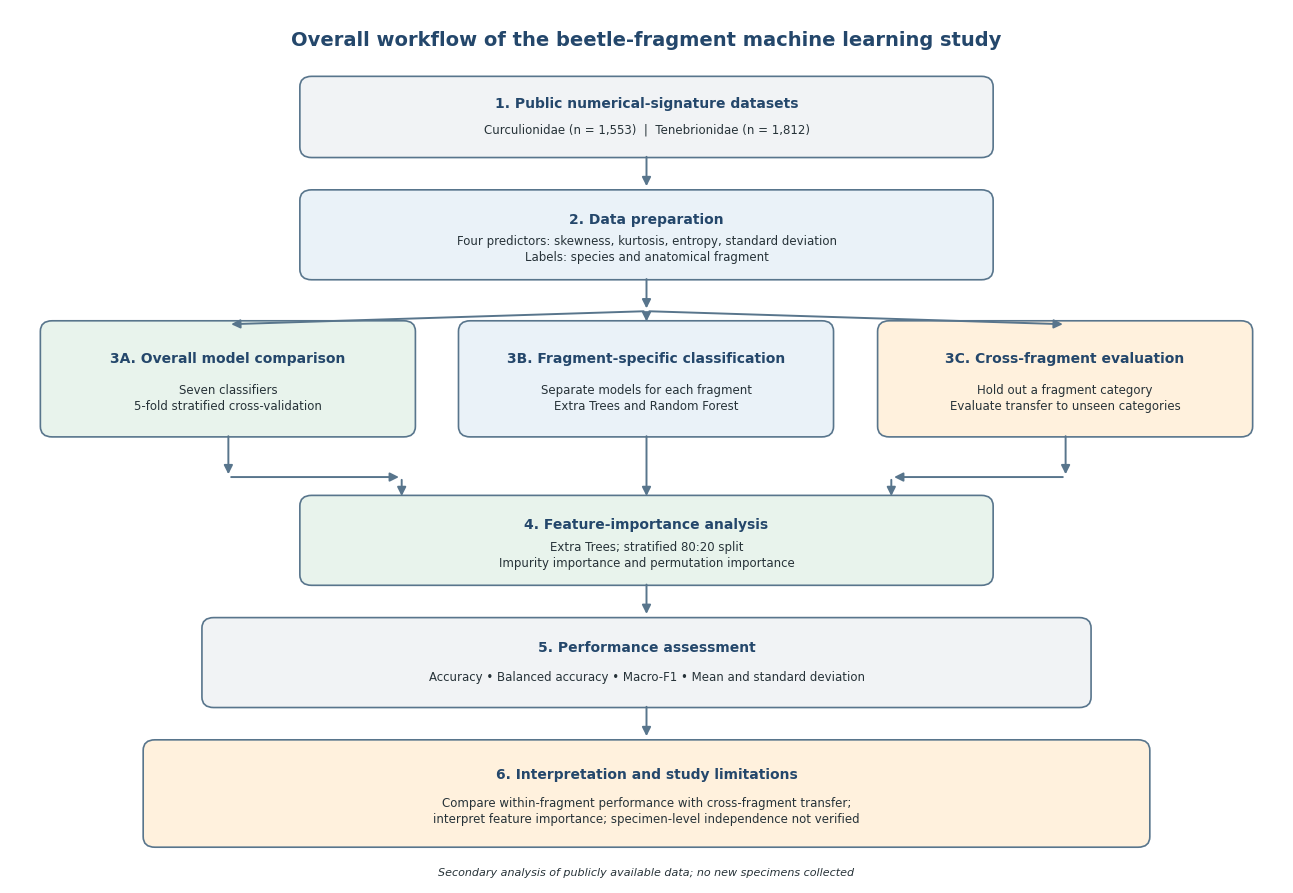

Saved files:
/content/Figure1_Overall_Workflow.png
/content/Figure1_Overall_Workflow.pdf


In [ ]:

# Figure 1. Overall workflow of the beetle-fragment ML study
# Publication-quality workflow diagram (PNG + PDF)

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib import rcParams

# Publication typography
rcParams["font.family"] = "DejaVu Sans"
rcParams["font.size"] = 9

fig, ax = plt.subplots(figsize=(13, 9))
ax.set_xlim(0, 13)
ax.set_ylim(0, 10)
ax.axis("off")

# Neutral, print-friendly palette
navy = "#24476B"
blue = "#EAF2F8"
green = "#E8F3EC"
orange = "#FFF1DD"
grey = "#F1F3F5"
dark = "#263238"
edge = "#58758C"

def add_box(x, y, w, h, title, body="", fc=blue,
            title_size=10, body_size=8.5, linewidth=1.2):
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.04,rounding_size=0.12",
        facecolor=fc, edgecolor=edge, linewidth=linewidth
    )
    ax.add_patch(patch)

    ax.text(
        x + w/2, y + h*0.68, title,
        ha="center", va="center",
        fontsize=title_size, fontweight="bold", color=navy,
        wrap=True
    )

    if body:
        ax.text(
            x + w/2, y + h*0.32, body,
            ha="center", va="center",
            fontsize=body_size, color=dark,
            linespacing=1.3, wrap=True
        )

def arrow(x1, y1, x2, y2, color=edge, lw=1.4):
    patch = FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="-|>", mutation_scale=13,
        linewidth=lw, color=color,
        connectionstyle="arc3,rad=0"
    )
    ax.add_patch(patch)

# Main title
ax.text(
    6.5, 9.65,
    "Overall workflow of the beetle-fragment machine learning study",
    ha="center", va="center", fontsize=14,
    fontweight="bold", color=navy
)

# 1. Data source
add_box(
    3.0, 8.35, 7.0, 0.85,
    "1. Public numerical-signature datasets",
    "Curculionidae (n = 1,553)  |  Tenebrionidae (n = 1,812)",
    fc=grey
)
arrow(6.5, 8.35, 6.5, 7.95)

# 2. Dataset preparation
add_box(
    3.0, 6.95, 7.0, 0.95,
    "2. Data preparation",
    "Four predictors: skewness, kurtosis, entropy, standard deviation\nLabels: species and anatomical fragment",
    fc=blue
)
arrow(6.5, 6.95, 6.5, 6.55)

# 3. Analysis branches
add_box(
    0.35, 5.15, 3.75, 1.25,
    "3A. Overall model comparison",
    "Seven classifiers\n5-fold stratified cross-validation",
    fc=green
)
add_box(
    4.62, 5.15, 3.75, 1.25,
    "3B. Fragment-specific classification",
    "Separate models for each fragment\nExtra Trees and Random Forest",
    fc=blue
)
add_box(
    8.9, 5.15, 3.75, 1.25,
    "3C. Cross-fragment evaluation",
    "Hold out a fragment category\nEvaluate transfer to unseen categories",
    fc=orange
)

arrow(6.5, 6.55, 2.23, 6.4)
arrow(6.5, 6.55, 6.5, 6.4)
arrow(6.5, 6.55, 10.78, 6.4)

# 4. Feature importance
add_box(
    3.0, 3.45, 7.0, 0.95,
    "4. Feature-importance analysis",
    "Extra Trees; stratified 80:20 split\nImpurity importance and permutation importance",
    fc=green
)

# Connect branches to common interpretation stage
arrow(2.23, 5.15, 2.23, 4.65)
arrow(2.23, 4.65, 4.0, 4.65)
arrow(4.0, 4.65, 4.0, 4.4)

arrow(6.5, 5.15, 6.5, 4.4)

arrow(10.78, 5.15, 10.78, 4.65)
arrow(10.78, 4.65, 9.0, 4.65)
arrow(9.0, 4.65, 9.0, 4.4)

# 5. Metrics
arrow(6.5, 3.45, 6.5, 3.05)
add_box(
    2.0, 2.05, 9.0, 0.95,
    "5. Performance assessment",
    "Accuracy • Balanced accuracy • Macro-F1 • Mean and standard deviation",
    fc=grey
)

# 6. Interpretation and limitation
arrow(6.5, 2.05, 6.5, 1.65)
add_box(
    1.4, 0.45, 10.2, 1.15,
    "6. Interpretation and study limitations",
    "Compare within-fragment performance with cross-fragment transfer;\ninterpret feature importance; specimen-level independence not verified",
    fc=orange
)

# Footer
ax.text(
    6.5, 0.12,
    "Secondary analysis of publicly available data; no new specimens collected",
    ha="center", va="center", fontsize=8, color=dark, style="italic"
)

plt.tight_layout()

# Save files
png_file = "/content/Figure1_Overall_Workflow.png"
pdf_file = "/content/Figure1_Overall_Workflow.pdf"

fig.savefig(png_file, dpi=600, bbox_inches="tight", facecolor="white")
fig.savefig(pdf_file, bbox_inches="tight", facecolor="white")

plt.show()

print("Saved files:")
print(png_file)
print(pdf_file)


In [ ]:
import os
from glob import glob

for f in glob("/content/**/*", recursive=True):
    if os.path.isfile(f) and any(
        word in os.path.basename(f).lower()
        for word in ["distribution", "feature_dist", "curculionidae", "tenebrionidae"]
    ) and f.lower().endswith((".png", ".jpg", ".pdf")):
        print(f)

/content/Figure_model_accuracy_Curculionidae.png
/content/Figure_model_accuracy_Tenebrionidae.png
/content/normalised_confusion_matrices/Curculionidae_antenna_normalised_cm.png
/content/normalised_confusion_matrices/Tenebrionidae_elytra_normalised_cm.png
/content/normalised_confusion_matrices/Tenebrionidae_thorax_normalised_cm.png
/content/normalised_confusion_matrices/Curculionidae_thorax_normalised_cm.png
/content/normalised_confusion_matrices/Curculionidae_snout_normalised_cm.png
/content/normalised_confusion_matrices/Tenebrionidae_har_normalised_cm.png
/content/normalised_confusion_matrices/Curculionidae_elytra_normalised_cm.png
/content/normalised_confusion_matrices/Tenebrionidae_antenna_normalised_cm.png


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for f in files:
        if any(k in f.lower() for k in [
            "cross_fragment", "cross-fragment",
            "generalisation", "generalization", "macro_f1"
        ]):
            print(os.path.join(root, f))

/content/Figure_fragment_macro_F1.png


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for f in files:
        if f.endswith((".csv", ".xlsx", ".txt")) and any(
            k in f.lower() for k in ["result", "fragment", "model", "comparison"]
        ):
            print(os.path.join(root, f))

/content/verified_per_fragment_results.csv
/content/beetle_additional_models_results.csv
/content/beetle_xgboost_results.csv
/content/beetle_master_model_comparison.csv
/content/beetle_classifier_comparison_audit.csv
/content/verified_summary_results.csv
/content/beetle_ml_baseline_results.csv
/content/drive/MyDrive/Colab Notebooks/beetle_fragment_results_recovered.txt


In [ ]:
import pandas as pd

df = pd.read_csv("/content/verified_per_fragment_results.csv")

print("Columns:", df.columns.tolist())
print("Shape:", df.shape)
display(df.head(10))

Columns: ['Family', 'Held-out fragment', 'Model', 'N test', 'Accuracy', 'Balanced accuracy', 'Macro-F1']
Shape: (24, 7)


,Family,Held-out fragment,Model,N test,Accuracy,Balanced accuracy,Macro-F1
0,Curculionidae,antenna,Dummy,396,0.363636,0.333333,0.177778
1,Curculionidae,antenna,SVM,396,0.401515,0.391739,0.379994
2,Curculionidae,antenna,Random Forest,396,0.308081,0.302266,0.302132
3,Curculionidae,elytra,Dummy,341,0.316716,0.333333,0.160356
4,Curculionidae,elytra,SVM,341,0.249267,0.263403,0.229605
5,Curculionidae,elytra,Random Forest,341,0.328446,0.328201,0.325926
6,Curculionidae,snout,Dummy,456,0.421053,0.333333,0.197531
7,Curculionidae,snout,SVM,456,0.434211,0.432262,0.415667
8,Curculionidae,snout,Random Forest,456,0.372807,0.348063,0.344672
9,Curculionidae,thorax,Dummy,360,0.383333,0.333333,0.184739


In [ ]:
import pandas as pd

df = pd.read_csv("/content/verified_per_fragment_results.csv")

print(df.groupby(["Family", "Model"]).size())
print("\nAvailable models:", df["Model"].unique())

Family         Model        
Curculionidae  Dummy            4
               Random Forest    4
               SVM              4
Tenebrionidae  Dummy            4
               Random Forest    4
               SVM              4
dtype: int64

Available models: ['Dummy' 'SVM' 'Random Forest']


In [ ]:
import glob
import pandas as pd

for path in glob.glob("/content/*.csv"):
    try:
        d = pd.read_csv(path)
        if "Model" in d.columns and d["Model"].astype(str).str.contains(
            "Extra Trees|ExtraTrees", case=False, regex=True
        ).any():
            print("\nFILE:", path)
            print("Columns:", d.columns.tolist())
            print(d[d["Model"].astype(str).str.contains(
                "Extra Trees|ExtraTrees", case=False, regex=True
            )].head())
    except Exception:
        pass


FILE: /content/beetle_master_model_comparison.csv
Columns: ['Family', 'Model', 'Accuracy_mean_pct', 'Accuracy_SD_pct', 'Balanced_accuracy_pct', 'Macro_F1_mean_pct', 'Macro_F1_SD_pct']
          Family        Model  Accuracy_mean_pct  Accuracy_SD_pct  \
0  Curculionidae  Extra Trees              94.08             1.92   
7  Tenebrionidae  Extra Trees              91.83             1.83   

   Balanced_accuracy_pct  Macro_F1_mean_pct  Macro_F1_SD_pct  
0                  94.05              94.04             1.93  
7                  91.71              91.71             1.90  

FILE: /content/beetle_classifier_comparison_audit.csv
Columns: ['Family', 'Prediction task', 'Model', 'N', 'Accuracy_mean', 'Accuracy_SD', 'Balanced_accuracy_mean', 'Balanced_accuracy_SD', 'Macro_F1_mean', 'Macro_F1_SD']
           Family Prediction task        Model     N  Accuracy_mean  \
1   Curculionidae         Species  Extra Trees  1553       0.940765   
5   Curculionidae        Fragment  Extra Trees  1553  

In [ ]:
import pandas as pd

df = pd.read_csv("/content/verified_per_fragment_results.csv")

print(df[["Family", "Held-out fragment", "Model", "Macro-F1"]].to_string(index=False))

       Family Held-out fragment         Model  Macro-F1
Curculionidae           antenna         Dummy  0.177778
Curculionidae           antenna           SVM  0.379994
Curculionidae           antenna Random Forest  0.302132
Curculionidae            elytra         Dummy  0.160356
Curculionidae            elytra           SVM  0.229605
Curculionidae            elytra Random Forest  0.325926
Curculionidae             snout         Dummy  0.197531
Curculionidae             snout           SVM  0.415667
Curculionidae             snout Random Forest  0.344672
Curculionidae            thorax         Dummy  0.184739
Curculionidae            thorax           SVM  0.233746
Curculionidae            thorax Random Forest  0.318748
Tenebrionidae           antenna         Dummy  0.176471
Tenebrionidae           antenna           SVM  0.418759
Tenebrionidae           antenna Random Forest  0.268482
Tenebrionidae            elytra         Dummy  0.186667
Tenebrionidae            elytra           SVM  0

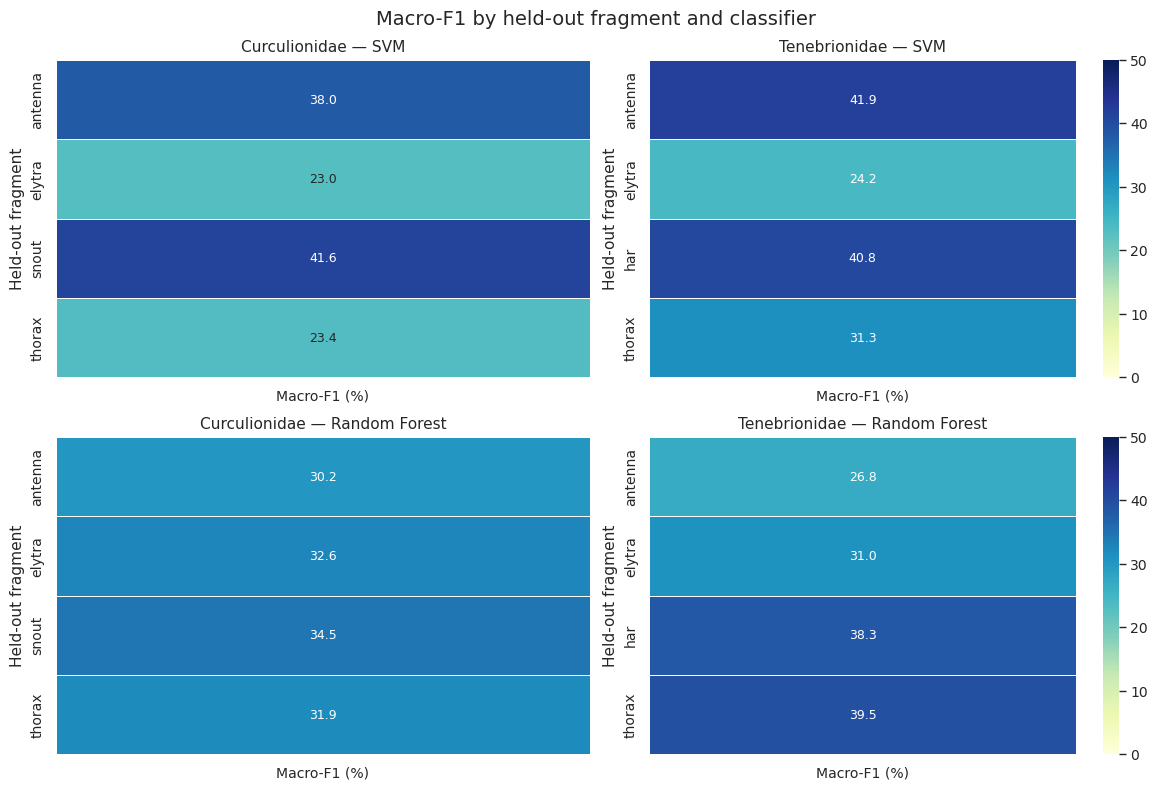

Saved Figure 7 PNG and PDF.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/verified_per_fragment_results.csv")
df = df[df["Model"].isin(["SVM", "Random Forest"])].copy()

df["Macro-F1 (%)"] = df["Macro-F1"] * 100

families = ["Curculionidae", "Tenebrionidae"]
models = ["SVM", "Random Forest"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, model in enumerate(models):
    for col, family in enumerate(families):
        ax = axes[row, col]
        subset = df[
            (df["Family"] == family) &
            (df["Model"] == model)
        ]

        heatmap_data = subset.set_index(
            "Held-out fragment"
        )[["Macro-F1 (%)"]]

        sns.heatmap(
            heatmap_data,
            annot=True,
            fmt=".1f",
            cmap="YlGnBu",
            vmin=0,
            vmax=50,
            ax=ax,
            cbar=(col == 1),
            linewidths=0.5
        )

        ax.set_title(f"{family} — {model}")
        ax.set_xlabel("")
        ax.set_ylabel("Held-out fragment")

fig.suptitle(
    "Macro-F1 by held-out fragment and classifier",
    fontsize=14
)
fig.tight_layout()

fig.savefig(
    "/content/Figure7_Cross_Fragment_MacroF1_Heatmap.png",
    dpi=600,
    bbox_inches="tight"
)
fig.savefig(
    "/content/Figure7_Cross_Fragment_MacroF1_Heatmap.pdf",
    bbox_inches="tight"
)

plt.show()
print("Saved Figure 7 PNG and PDF.")

In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for f in files:
        if any(k in f.lower() for k in [
            "feature_importance", "feature-importance",
            "permutation", "importance"
        ]) and f.lower().endswith((".png", ".jpg", ".pdf")):
            print(os.path.join(root, f))

/content/beetle_feature_importance.png
/content/Figure4_Permutation_Feature_Importance.png


In [ ]:
import sys
import platform
import sklearn
import numpy
import pandas
import matplotlib
import seaborn

print("Python:", sys.version)
print("Platform:", platform.platform())
print("scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("Matplotlib:", matplotlib.__version__)
print("seaborn:", seaborn.__version__)

# Save a complete package-version list
!pip freeze > /content/requirements_freeze.txt

print("\nSaved package list to /content/requirements_freeze.txt")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
scikit-learn: 1.6.1
NumPy: 2.1.3
pandas: 2.2.3
Matplotlib: 3.10.0
seaborn: 0.13.2

Saved package list to /content/requirements_freeze.txt
